In [3]:
# ==============================================================
# 纯净版消融实验：分类 (LDA) 与回归 (Random Forest)
# 降级对比版：无监督/伪自适应 DNN 融合 (不接触真实特征与标签)
# 极速非线性版：mutual_info_classif 预计算查表
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# --- Sklearn ---
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import normalize
from sklearn.metrics import r2_score, accuracy_score

# --- Models ---
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, RandomForestRegressor 
from sklearn.svm import SVC, SVR
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression

# 统一的方法排序，保证最后输出表格的列顺序一致
METHOD_ORDER = [
    "Single-Obj (Class)", 
    "Single-Obj (Reg)", 
    "Mean-Agg (No NN)", 
    "GA+DNN (Fixed Weights)", 
    "GA+DNN (Adaptive - Ours)"
]

# ==============================================================
# 0. Configuration
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# ==============================================================
# 1. Safe & Fast Fitness Functions (极速查表化)
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.02):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def calc_mi_class_fast(mask, opts):
    sel = np.where(mask == 1)[0]
    if len(sel) == 0: return 1e6
    mi_scores = opts['mi_scores'] 
    return -float(np.mean(mi_scores[sel])) + _size_penalty(len(sel), len(mask))

def calc_redundancy_safe(mask, opts):
    sel = np.where(mask == 1)[0]
    xt_in = opts['xt_in']
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt_in.shape[1])
    Xs = xt_in[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    m = C.shape[0]
    return float(C.sum() / max(1, m * (m - 1))) + _size_penalty(len(sel), xt_in.shape[1])

def calc_regression_safe(mask, opts):
    sel = np.where(mask == 1)[0]
    xt_in, yt_in, xv_in, yv_in = opts['xt_in'], opts['yt_in'], opts['xv_in'], opts['yv_in']
    if len(sel) == 0: return 1e6
    model = LinearRegression()
    model.fit(xt_in[:, sel], yt_in)
    r2 = r2_score(yv_in, model.predict(xv_in[:, sel]))
    return -float(r2) + _size_penalty(len(sel), xt_in.shape[1])

# ==============================================================
# 2. GA Components
# ==============================================================
def init_position(lb, ub, N, dim):
    return lb + (ub - lb) * np.random.rand(N, dim)

def binary_conversion(X, thres):
    return (X > thres).astype(int)

def roulette_wheel(prob):
    C = np.cumsum(prob); C[-1] = 1.0
    P = np.random.rand()
    idx = np.searchsorted(C, P)
    return min(idx, len(prob) - 1)

def jfs_single_obj_fast(mode, opts):
    ub, lb, thres = 1, 0, 0.5
    CR, MR, N, max_iter = 0.8, 0.01, opts['N'], opts['T']
    dim = opts['xt_in'].shape[1]
    X = binary_conversion(init_position(lb, ub, N, dim), thres)
    
    fit_funcs = {
        'class': calc_mi_class_fast,
        'redundancy': calc_redundancy_safe,
        'regression': calc_regression_safe
    }
    fit_function = fit_funcs[mode]
    
    fit = np.array([fit_function(X[i], opts) for i in range(N)])
    best_idx = int(np.argmin(fit)); fitG = fit[best_idx]
    
    for t in range(1, max_iter):
        sorted_idx = np.argsort(fit)
        ranks = np.empty(N); ranks[sorted_idx] = np.arange(N, 0, -1)
        prob = ranks / ranks.sum()
        Nc = max(1, int(np.sum(np.random.rand(N) < CR)))
        x1, x2 = np.zeros((Nc, dim), dtype=int), np.zeros((Nc, dim), dtype=int)
        
        for i in range(Nc):
            P1 = X[roulette_wheel(prob)]; P2 = X[roulette_wheel(prob)]
            idx = np.random.randint(1, dim - 1) if dim > 2 else 1
            child1 = np.concatenate((P1[:idx], P2[idx:])); child2 = np.concatenate((P2[:idx], P1[idx:]))
            
            child1 ^= (np.random.rand(dim) < MR).astype(int)
            child2 ^= (np.random.rand(dim) < MR).astype(int)
            x1[i], x2[i] = child1, child2
            
        Xnew = np.vstack((x1, x2))
        Fnew = np.array([fit_function(Xnew[i], opts) for i in range(Xnew.shape[0])])
        new_best_idx = int(np.argmin(Fnew))
        if Fnew[new_best_idx] < fitG: fitG = Fnew[new_best_idx]
        
        XX = np.vstack((X, Xnew)); FF = np.concatenate((fit, Fnew))
        keep = np.argsort(FF)[:N]; X, fit = XX[keep], FF[keep]
        
    return X, fit

def keep_elite(X, fit, elite_ratio=0.2):
    n = X.shape[0]; ne = max(5, int(np.ceil(n * elite_ratio)))
    idx = np.argsort(fit.ravel())[:ne]
    return X[idx]

# ==============================================================
# 3. Unsupervised SoftMaskNet (退回至“伪自适应”与无监督基准)
# ==============================================================
class SoftMaskDNN(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        self.fc1 = nn.Linear(3 * num_features, 64)
        self.fc2 = nn.Linear(64, num_features)
    def forward(self, x):
        return self.fc2(F.relu(self.fc1(x)))

def train_softmask_dnn_adaptive_unsupervised(pop1, pop2, pop3, num_features, epochs=60, lr=1e-3):
    """无监督/伪自适应版本：不接触真实标签与数据，纯靠拼凑 Mask 优化自身"""
    device = "cuda" if torch.cuda.is_available() else "cpu"
    X_list = []
    if len(pop1)==0: pop1=np.zeros((1, num_features))
    if len(pop2)==0: pop2=np.zeros((1, num_features))
    if len(pop3)==0: pop3=np.zeros((1, num_features))

    for _ in range(800):
        i1, i2, i3 = random.randint(0, len(pop1)-1), random.randint(0, len(pop2)-1), random.randint(0, len(pop3)-1)
        inp = torch.tensor(np.concatenate([pop1[i1], pop2[i2], pop3[i3]]), dtype=torch.float32)
        X_list.append(inp)
        
    dataloader = DataLoader(TensorDataset(torch.stack(X_list)), batch_size=32, shuffle=True)
    model = SoftMaskDNN(num_features).to(device)
    w_logits = nn.Parameter(torch.ones(3, device=device))
    optimizer = torch.optim.Adam(list(model.parameters()) + [w_logits], lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    
    model.train()
    for _ in range(epochs):
        for (bx,) in dataloader:
            bx = bx.to(device)
            m1, m2, m3 = torch.chunk(bx, 3, dim=1)
            current_w = F.softmax(w_logits, dim=0)
            pred_logits = model(bx)
            # 无监督目标：逼近三个种群的动态线性组合
            target = (current_w[0]*m1 + current_w[1]*m2 + current_w[2]*m3).clamp(0.0, 1.0)
            loss = loss_fn(pred_logits, target)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            
    model.eval()
    with torch.no_grad():
        m1 = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device)
        m2 = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device)
        m3 = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device)
        inp = torch.cat([m1, m2, m3]).unsqueeze(0)
        scores = torch.sigmoid(model(inp)).squeeze(0).cpu().numpy()
    return scores

def train_softmask_dnn_fixed_unsupervised(pop1, pop2, pop3, num_features, epochs=60, lr=1e-3):
    """无监督 Fixed 基准：固定目标权重为 1/3"""
    device = "cuda" if torch.cuda.is_available() else "cpu"
    X_list = []
    if len(pop1)==0: pop1=np.zeros((1, num_features))
    if len(pop2)==0: pop2=np.zeros((1, num_features))
    if len(pop3)==0: pop3=np.zeros((1, num_features))

    for _ in range(800):
        i1, i2, i3 = random.randint(0, len(pop1)-1), random.randint(0, len(pop2)-1), random.randint(0, len(pop3)-1)
        inp = torch.tensor(np.concatenate([pop1[i1], pop2[i2], pop3[i3]]), dtype=torch.float32)
        X_list.append(inp)
        
    dataloader = DataLoader(TensorDataset(torch.stack(X_list)), batch_size=32, shuffle=True)
    model = SoftMaskDNN(num_features).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    fixed_w = [1/3, 1/3, 1/3]
    
    model.train()
    for _ in range(epochs):
        for (bx,) in dataloader:
            bx = bx.to(device)
            m1, m2, m3 = torch.chunk(bx, 3, dim=1)
            pred_logits = model(bx)
            # 目标为固定的平均值
            target = (fixed_w[0]*m1 + fixed_w[1]*m2 + fixed_w[2]*m3).clamp(0.0, 1.0)
            loss = loss_fn(pred_logits, target)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            
    model.eval()
    with torch.no_grad():
        m1 = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device)
        m2 = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device)
        m3 = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device)
        inp = torch.cat([m1, m2, m3]).unsqueeze(0)
        scores = torch.sigmoid(model(inp)).squeeze(0).cpu().numpy()
    return scores

# ==============================================================
# 4. Main Experiment Pipeline
# ==============================================================
def run_ablation_benchmark_safe(features, class_labels, regression_target, n_runs=10, out_csv="Ablation_Detailed_Results_Unsupervised.csv"):
    y_class = np.asarray(class_labels)
    y_reg = np.asarray(regression_target)
    feat = normalize(np.asarray(features), norm='l1')
    
    classifiers = {
        "KNN": KNeighborsClassifier(3), "LDA": LinearDiscriminantAnalysis(),
        "AdaBoost": AdaBoostClassifier(random_state=42),
        "SVM": SVC(kernel='linear', random_state=42),
        "RF": RandomForestClassifier(n_estimators=50, random_state=42)
    }

    regressors = {
        "PLS": PLSRegression(n_components=5), "SVR": SVR(kernel='linear'),
        "RF": RandomForestRegressor(n_estimators=50, random_state=42) 
    }

    all_results = []
    print("=" * 60)
    print(f"Starting UNSUPERVISED (CONTRAST) BENCHMARK: {n_runs} Runs")
    print("=" * 60)

    for run_idx in range(n_runs):
        print(f"\n>>> Run {run_idx+1}/{n_runs}...")
        current_seed = 42 + run_idx
        set_seed(current_seed)
        
        # 1. 切分独立测试集
        xt_tr, xt_te, yc_tr, yc_te, yr_tr, yr_te = train_test_split(
            feat, y_class, y_reg, test_size=0.3, stratify=y_class, random_state=current_seed
        )
        
        # 2. GA 内部验证集
        xt_in, xv_in, yc_in, yc_val, yr_in, yr_val = train_test_split(
            xt_tr, yc_tr, yr_tr, test_size=0.25, stratify=yc_tr, random_state=current_seed
        )
        
        print("  [Pre-compute] Calculating Mutual Information (1000x Speedup)...")
        mi_scores = mutual_info_classif(xt_in, yc_in, random_state=42)
        
        opts_c = {'xt_in': xt_in, 'yt_in': yc_in, 'xv_in': xv_in, 'yv_in': yc_val, 'N': 40, 'T': 40, 'mi_scores': mi_scores}
        opts_r = {'xt_in': xt_in, 'yt_in': yr_in, 'xv_in': xv_in, 'yv_in': yr_val, 'N': 40, 'T': 40}
        
        print("  [1/3] Evolving GA populations...")
        pop1 = keep_elite(*jfs_single_obj_fast('class', opts_c))
        pop2 = keep_elite(*jfs_single_obj_fast('redundancy', opts_c))
        pop3 = keep_elite(*jfs_single_obj_fast('regression', opts_r))
        
        print("  [2/3] Training Unsupervised DNN Ablation Variants...")
        scores_single_class = pop1.mean(0)
        scores_single_reg = pop3.mean(0)
        scores_mean_agg = (pop1.mean(0) + pop2.mean(0) + pop3.mean(0)) / 3.0
        
        # ⚠️ 这里直接运行无监督的融合网络，不传入真实数据特征与标签
        scores_dnn_fixed = train_softmask_dnn_fixed_unsupervised(pop1, pop2, pop3, xt_tr.shape[1])
        scores_dnn_adapt = train_softmask_dnn_adaptive_unsupervised(pop1, pop2, pop3, xt_tr.shape[1])
        
        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else [0]
        
        print("  [3/3] Evaluating on Unseen Test Data...")
        for k in range(1, 16):
            # 分类与回归使用同一组伪自适应/无监督分值
            methods = {
                "Single-Obj (Class)": get_top_k(scores_single_class, k),
                "Single-Obj (Reg)": get_top_k(scores_single_reg, k),
                "Mean-Agg (No NN)": get_top_k(scores_mean_agg, k),
                "GA+DNN (Fixed Weights)": get_top_k(scores_dnn_fixed, k),
                "GA+DNN (Adaptive - Ours)": get_top_k(scores_dnn_adapt, k) 
            }
            
            # 分类任务评估
            for m_name, idx in methods.items():
                for clf_name, clf in classifiers.items():
                    clf.fit(xt_tr[:, idx], yc_tr)
                    acc = clf.score(xt_te[:, idx], yc_te)
                    all_results.append({"Run": run_idx+1, "Method": m_name, "K": k, "Task": "Classification", "Model": clf_name, "Score": acc})
            
            # 回归任务评估
            for m_name, idx in methods.items():
                for reg_name, reg in regressors.items():
                    if reg_name == "PLS": reg = PLSRegression(n_components=min(k, 5))
                    reg.fit(xt_tr[:, idx], yr_tr)
                    r2 = r2_score(yr_te, reg.predict(xt_te[:, idx]))
                    all_results.append({"Run": run_idx+1, "Method": m_name, "K": k, "Task": "Regression", "Model": reg_name, "Score": r2})

    # ==============================================================
    # 6. Data Summary & Output
    # ==============================================================
    df = pd.DataFrame(all_results)
    df.to_csv(out_csv, index=False)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

    print("\n" + "="*60 + "\nGenerating Clean Output Tables (Mean ± Std)...")
    
    df_lda = df[(df["Task"] == "Classification") & (df["Model"] == "LDA")]
    if not df_lda.empty:
        table_lda = df_lda.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_lda = table_lda[[m for m in METHOD_ORDER if m in table_lda.columns]]
        table_lda.to_csv("Table_Unsupervised_Class_LDA.csv")
        print("\n[TABLE 1] Classification Accuracy (LDA Only) [UNSUPERVISED DNN]:\n", table_lda)

    df_rf = df[(df["Task"] == "Regression") & (df["Model"] == "RF")]
    if not df_rf.empty:
        table_rf = df_rf.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_rf = table_rf[[m for m in METHOD_ORDER if m in table_rf.columns]]
        table_rf.to_csv("Table_Unsupervised_Reg_RF.csv")
        print("\n[TABLE 2] Regression R2 Score (Random Forest Only) [UNSUPERVISED DNN]:\n", table_rf)

if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("DATASET.xlsx")
        label = df.iloc[:, 1].to_numpy()
        sugar = df.iloc[:, 2].to_numpy()
        features = df.drop(df.columns[[0, 1, 2]], axis=1).values
        
        run_ablation_benchmark_safe(features, label, sugar, n_runs=10)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        X = np.random.rand(150, 50); yc = np.random.randint(0, 2, 150); yr = np.random.rand(150)
        run_ablation_benchmark_safe(X, yc, yr, n_runs=2)

Loading Data...
Starting UNSUPERVISED (CONTRAST) BENCHMARK: 10 Runs

>>> Run 1/10...
  [Pre-compute] Calculating Mutual Information (1000x Speedup)...
  [1/3] Evolving GA populations...
  [2/3] Training Unsupervised DNN Ablation Variants...
  [3/3] Evaluating on Unseen Test Data...

>>> Run 2/10...
  [Pre-compute] Calculating Mutual Information (1000x Speedup)...
  [1/3] Evolving GA populations...
  [2/3] Training Unsupervised DNN Ablation Variants...
  [3/3] Evaluating on Unseen Test Data...

>>> Run 3/10...
  [Pre-compute] Calculating Mutual Information (1000x Speedup)...
  [1/3] Evolving GA populations...
  [2/3] Training Unsupervised DNN Ablation Variants...
  [3/3] Evaluating on Unseen Test Data...

>>> Run 4/10...
  [Pre-compute] Calculating Mutual Information (1000x Speedup)...
  [1/3] Evolving GA populations...
  [2/3] Training Unsupervised DNN Ablation Variants...
  [3/3] Evaluating on Unseen Test Data...

>>> Run 5/10...
  [Pre-compute] Calculating Mutual Information (1000x S

In [4]:
# ==============================================================
# 纯净版消融实验：分类 (LDA) 与回归 (Random Forest)
# 降级对比版：无监督/伪自适应 DNN 融合 (不接触真实特征与标签)
# 极速非线性版：mutual_info_classif 预计算查表
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# --- Sklearn ---
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import normalize
from sklearn.metrics import r2_score, accuracy_score

# --- Models ---
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, RandomForestRegressor 
from sklearn.svm import SVC, SVR
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression

# 统一的方法排序，保证最后输出表格的列顺序一致
METHOD_ORDER = [
    "Single-Obj (Class)", 
    "Single-Obj (Reg)", 
    "Mean-Agg (No NN)", 
    "GA+DNN (Fixed Weights)", 
    "GA+DNN (Adaptive - Ours)"
]

# ==============================================================
# 0. Configuration
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# ==============================================================
# 1. Safe & Fast Fitness Functions (极速查表化)
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.02):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def calc_mi_class_fast(mask, opts):
    sel = np.where(mask == 1)[0]
    if len(sel) == 0: return 1e6
    mi_scores = opts['mi_scores'] 
    return -float(np.mean(mi_scores[sel])) + _size_penalty(len(sel), len(mask))

def calc_redundancy_safe(mask, opts):
    sel = np.where(mask == 1)[0]
    xt_in = opts['xt_in']
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt_in.shape[1])
    Xs = xt_in[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    m = C.shape[0]
    return float(C.sum() / max(1, m * (m - 1))) + _size_penalty(len(sel), xt_in.shape[1])

def calc_regression_safe(mask, opts):
    sel = np.where(mask == 1)[0]
    xt_in, yt_in, xv_in, yv_in = opts['xt_in'], opts['yt_in'], opts['xv_in'], opts['yv_in']
    if len(sel) == 0: return 1e6
    model = LinearRegression()
    model.fit(xt_in[:, sel], yt_in)
    r2 = r2_score(yv_in, model.predict(xv_in[:, sel]))
    return -float(r2) + _size_penalty(len(sel), xt_in.shape[1])

# ==============================================================
# 2. GA Components
# ==============================================================
def init_position(lb, ub, N, dim):
    return lb + (ub - lb) * np.random.rand(N, dim)

def binary_conversion(X, thres):
    return (X > thres).astype(int)

def roulette_wheel(prob):
    C = np.cumsum(prob); C[-1] = 1.0
    P = np.random.rand()
    idx = np.searchsorted(C, P)
    return min(idx, len(prob) - 1)

def jfs_single_obj_fast(mode, opts):
    ub, lb, thres = 1, 0, 0.5
    CR, MR, N, max_iter = 0.8, 0.01, opts['N'], opts['T']
    dim = opts['xt_in'].shape[1]
    X = binary_conversion(init_position(lb, ub, N, dim), thres)
    
    fit_funcs = {
        'class': calc_mi_class_fast,
        'redundancy': calc_redundancy_safe,
        'regression': calc_regression_safe
    }
    fit_function = fit_funcs[mode]
    
    fit = np.array([fit_function(X[i], opts) for i in range(N)])
    best_idx = int(np.argmin(fit)); fitG = fit[best_idx]
    
    for t in range(1, max_iter):
        sorted_idx = np.argsort(fit)
        ranks = np.empty(N); ranks[sorted_idx] = np.arange(N, 0, -1)
        prob = ranks / ranks.sum()
        Nc = max(1, int(np.sum(np.random.rand(N) < CR)))
        x1, x2 = np.zeros((Nc, dim), dtype=int), np.zeros((Nc, dim), dtype=int)
        
        for i in range(Nc):
            P1 = X[roulette_wheel(prob)]; P2 = X[roulette_wheel(prob)]
            idx = np.random.randint(1, dim - 1) if dim > 2 else 1
            child1 = np.concatenate((P1[:idx], P2[idx:])); child2 = np.concatenate((P2[:idx], P1[idx:]))
            
            child1 ^= (np.random.rand(dim) < MR).astype(int)
            child2 ^= (np.random.rand(dim) < MR).astype(int)
            x1[i], x2[i] = child1, child2
            
        Xnew = np.vstack((x1, x2))
        Fnew = np.array([fit_function(Xnew[i], opts) for i in range(Xnew.shape[0])])
        new_best_idx = int(np.argmin(Fnew))
        if Fnew[new_best_idx] < fitG: fitG = Fnew[new_best_idx]
        
        XX = np.vstack((X, Xnew)); FF = np.concatenate((fit, Fnew))
        keep = np.argsort(FF)[:N]; X, fit = XX[keep], FF[keep]
        
    return X, fit

def keep_elite(X, fit, elite_ratio=0.2):
    n = X.shape[0]; ne = max(5, int(np.ceil(n * elite_ratio)))
    idx = np.argsort(fit.ravel())[:ne]
    return X[idx]

# ==============================================================
# 3. Unsupervised SoftMaskNet (退回至“伪自适应”与无监督基准)
# ==============================================================
class SoftMaskDNN(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        self.fc1 = nn.Linear(3 * num_features, 64)
        self.fc2 = nn.Linear(64, num_features)
    def forward(self, x):
        return self.fc2(F.relu(self.fc1(x)))

def train_softmask_dnn_adaptive_unsupervised(pop1, pop2, pop3, num_features, epochs=60, lr=1e-3):
    """无监督/伪自适应版本：不接触真实标签与数据，纯靠拼凑 Mask 优化自身"""
    device = "cuda" if torch.cuda.is_available() else "cpu"
    X_list = []
    if len(pop1)==0: pop1=np.zeros((1, num_features))
    if len(pop2)==0: pop2=np.zeros((1, num_features))
    if len(pop3)==0: pop3=np.zeros((1, num_features))

    for _ in range(800):
        i1, i2, i3 = random.randint(0, len(pop1)-1), random.randint(0, len(pop2)-1), random.randint(0, len(pop3)-1)
        inp = torch.tensor(np.concatenate([pop1[i1], pop2[i2], pop3[i3]]), dtype=torch.float32)
        X_list.append(inp)
        
    dataloader = DataLoader(TensorDataset(torch.stack(X_list)), batch_size=32, shuffle=True)
    model = SoftMaskDNN(num_features).to(device)
    w_logits = nn.Parameter(torch.ones(3, device=device))
    optimizer = torch.optim.Adam(list(model.parameters()) + [w_logits], lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    
    model.train()
    for _ in range(epochs):
        for (bx,) in dataloader:
            bx = bx.to(device)
            m1, m2, m3 = torch.chunk(bx, 3, dim=1)
            current_w = F.softmax(w_logits, dim=0)
            pred_logits = model(bx)
            # 无监督目标：逼近三个种群的动态线性组合
            target = (current_w[0]*m1 + current_w[1]*m2 + current_w[2]*m3).clamp(0.0, 1.0)
            loss = loss_fn(pred_logits, target)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            
    model.eval()
    with torch.no_grad():
        m1 = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device)
        m2 = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device)
        m3 = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device)
        inp = torch.cat([m1, m2, m3]).unsqueeze(0)
        scores = torch.sigmoid(model(inp)).squeeze(0).cpu().numpy()
    return scores

def train_softmask_dnn_fixed_unsupervised(pop1, pop2, pop3, num_features, epochs=60, lr=1e-3):
    """无监督 Fixed 基准：固定目标权重为 1/3"""
    device = "cuda" if torch.cuda.is_available() else "cpu"
    X_list = []
    if len(pop1)==0: pop1=np.zeros((1, num_features))
    if len(pop2)==0: pop2=np.zeros((1, num_features))
    if len(pop3)==0: pop3=np.zeros((1, num_features))

    for _ in range(800):
        i1, i2, i3 = random.randint(0, len(pop1)-1), random.randint(0, len(pop2)-1), random.randint(0, len(pop3)-1)
        inp = torch.tensor(np.concatenate([pop1[i1], pop2[i2], pop3[i3]]), dtype=torch.float32)
        X_list.append(inp)
        
    dataloader = DataLoader(TensorDataset(torch.stack(X_list)), batch_size=32, shuffle=True)
    model = SoftMaskDNN(num_features).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    fixed_w = [1/3, 1/3, 1/3]
    
    model.train()
    for _ in range(epochs):
        for (bx,) in dataloader:
            bx = bx.to(device)
            m1, m2, m3 = torch.chunk(bx, 3, dim=1)
            pred_logits = model(bx)
            # 目标为固定的平均值
            target = (fixed_w[0]*m1 + fixed_w[1]*m2 + fixed_w[2]*m3).clamp(0.0, 1.0)
            loss = loss_fn(pred_logits, target)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            
    model.eval()
    with torch.no_grad():
        m1 = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device)
        m2 = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device)
        m3 = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device)
        inp = torch.cat([m1, m2, m3]).unsqueeze(0)
        scores = torch.sigmoid(model(inp)).squeeze(0).cpu().numpy()
    return scores

# ==============================================================
# 4. Main Experiment Pipeline
# ==============================================================
def run_ablation_benchmark_safe(features, class_labels, regression_target, n_runs=10, out_csv="Ablation_Detailed_Results_Unsupervised2.csv"):
    y_class = np.asarray(class_labels)
    y_reg = np.asarray(regression_target)
    feat = normalize(np.asarray(features), norm='l1')
    
    classifiers = {
        "KNN": KNeighborsClassifier(3), "LDA": LinearDiscriminantAnalysis(),
        "AdaBoost": AdaBoostClassifier(random_state=42),
        "SVM": SVC(kernel='linear', random_state=42),
        "RF": RandomForestClassifier(n_estimators=50, random_state=42)
    }

    regressors = {
        "PLS": PLSRegression(n_components=5), "SVR": SVR(kernel='linear'),
        "RF": RandomForestRegressor(n_estimators=50, random_state=42) 
    }

    all_results = []
    print("=" * 60)
    print(f"Starting UNSUPERVISED (CONTRAST) BENCHMARK: {n_runs} Runs")
    print("=" * 60)

    for run_idx in range(n_runs):
        print(f"\n>>> Run {run_idx+1}/{n_runs}...")
        current_seed = 42 + run_idx
        set_seed(current_seed)
        
        # 1. 切分独立测试集
        xt_tr, xt_te, yc_tr, yc_te, yr_tr, yr_te = train_test_split(
            feat, y_class, y_reg, test_size=0.3, stratify=y_class, random_state=current_seed
        )
        
        # 2. GA 内部验证集
        xt_in, xv_in, yc_in, yc_val, yr_in, yr_val = train_test_split(
            xt_tr, yc_tr, yr_tr, test_size=0.25, stratify=yc_tr, random_state=current_seed
        )
        
        print("  [Pre-compute] Calculating Mutual Information (1000x Speedup)...")
        mi_scores = mutual_info_classif(xt_in, yc_in, random_state=42)
        
        opts_c = {'xt_in': xt_in, 'yt_in': yc_in, 'xv_in': xv_in, 'yv_in': yc_val, 'N': 40, 'T': 40, 'mi_scores': mi_scores}
        opts_r = {'xt_in': xt_in, 'yt_in': yr_in, 'xv_in': xv_in, 'yv_in': yr_val, 'N': 40, 'T': 40}
        
        print("  [1/3] Evolving GA populations...")
        pop1 = keep_elite(*jfs_single_obj_fast('class', opts_c))
        pop2 = keep_elite(*jfs_single_obj_fast('redundancy', opts_c))
        pop3 = keep_elite(*jfs_single_obj_fast('regression', opts_r))
        
        print("  [2/3] Training Unsupervised DNN Ablation Variants...")
        scores_single_class = pop1.mean(0)
        scores_single_reg = pop3.mean(0)
        scores_mean_agg = (pop1.mean(0) + pop2.mean(0) + pop3.mean(0)) / 3.0
        
        # ⚠️ 这里直接运行无监督的融合网络，不传入真实数据特征与标签
        scores_dnn_fixed = train_softmask_dnn_fixed_unsupervised(pop1, pop2, pop3, xt_tr.shape[1])
        scores_dnn_adapt = train_softmask_dnn_adaptive_unsupervised(pop1, pop2, pop3, xt_tr.shape[1])
        
        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else [0]
        
        print("  [3/3] Evaluating on Unseen Test Data...")
        for k in range(1, 16):
            # 分类与回归使用同一组伪自适应/无监督分值
            methods = {
                "Single-Obj (Class)": get_top_k(scores_single_class, k),
                "Single-Obj (Reg)": get_top_k(scores_single_reg, k),
                "Mean-Agg (No NN)": get_top_k(scores_mean_agg, k),
                "GA+DNN (Fixed Weights)": get_top_k(scores_dnn_fixed, k),
                "GA+DNN (Adaptive - Ours)": get_top_k(scores_dnn_adapt, k) 
            }
            
            # 分类任务评估
            for m_name, idx in methods.items():
                for clf_name, clf in classifiers.items():
                    clf.fit(xt_tr[:, idx], yc_tr)
                    acc = clf.score(xt_te[:, idx], yc_te)
                    all_results.append({"Run": run_idx+1, "Method": m_name, "K": k, "Task": "Classification", "Model": clf_name, "Score": acc})
            
            # 回归任务评估
            for m_name, idx in methods.items():
                for reg_name, reg in regressors.items():
                    if reg_name == "PLS": reg = PLSRegression(n_components=min(k, 5))
                    reg.fit(xt_tr[:, idx], yr_tr)
                    r2 = r2_score(yr_te, reg.predict(xt_te[:, idx]))
                    all_results.append({"Run": run_idx+1, "Method": m_name, "K": k, "Task": "Regression", "Model": reg_name, "Score": r2})

    # ==============================================================
    # 6. Data Summary & Output
    # ==============================================================
    df = pd.DataFrame(all_results)
    df.to_csv(out_csv, index=False)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

    print("\n" + "="*60 + "\nGenerating Clean Output Tables (Mean ± Std)...")
    
    df_lda = df[(df["Task"] == "Classification") & (df["Model"] == "LDA")]
    if not df_lda.empty:
        table_lda = df_lda.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_lda = table_lda[[m for m in METHOD_ORDER if m in table_lda.columns]]
        table_lda.to_csv("Table_Unsupervised_Class_LDA.csv")
        print("\n[TABLE 1] Classification Accuracy [UNSUPERVISED DNN]:\n", table_lda)

    df_rf = df[(df["Task"] == "Regression") & (df["Model"] == "RF")]
    if not df_rf.empty:
        table_rf = df_rf.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_rf = table_rf[[m for m in METHOD_ORDER if m in table_rf.columns]]
        table_rf.to_csv("Table_Unsupervised_Reg_RF.csv")
        print("\n[TABLE 2] Regression R2 Score [UNSUPERVISED DNN]:\n", table_rf)

if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("DATASET.xlsx")
        label = df.iloc[:, 1].to_numpy()
        sugar = df.iloc[:, 2].to_numpy()
        features = df.drop(df.columns[[0, 1, 2]], axis=1).values
        
        run_ablation_benchmark_safe(features, label, sugar, n_runs=30)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        X = np.random.rand(150, 50); yc = np.random.randint(0, 2, 150); yr = np.random.rand(150)
        run_ablation_benchmark_safe(X, yc, yr, n_runs=2)

Loading Data...
Starting UNSUPERVISED (CONTRAST) BENCHMARK: 30 Runs

>>> Run 1/30...
  [Pre-compute] Calculating Mutual Information (1000x Speedup)...
  [1/3] Evolving GA populations...
  [2/3] Training Unsupervised DNN Ablation Variants...
  [3/3] Evaluating on Unseen Test Data...

>>> Run 2/30...
  [Pre-compute] Calculating Mutual Information (1000x Speedup)...
  [1/3] Evolving GA populations...
  [2/3] Training Unsupervised DNN Ablation Variants...
  [3/3] Evaluating on Unseen Test Data...

>>> Run 3/30...
  [Pre-compute] Calculating Mutual Information (1000x Speedup)...
  [1/3] Evolving GA populations...
  [2/3] Training Unsupervised DNN Ablation Variants...
  [3/3] Evaluating on Unseen Test Data...

>>> Run 4/30...
  [Pre-compute] Calculating Mutual Information (1000x Speedup)...
  [1/3] Evolving GA populations...
  [2/3] Training Unsupervised DNN Ablation Variants...
  [3/3] Evaluating on Unseen Test Data...

>>> Run 5/30...
  [Pre-compute] Calculating Mutual Information (1000x S

In [6]:
# ==============================================================
# 升级版消融实验：分类 (LDA) 与回归 (Random Forest)
# 强悍进化版：弱监督双代理任务 DNN 融合 (Dual-Task Guided Fusion)
# 极速非线性版：mutual_info_classif 预计算查表
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# --- Sklearn ---
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import normalize
from sklearn.metrics import r2_score, accuracy_score

# --- Models ---
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, RandomForestRegressor 
from sklearn.svm import SVC, SVR
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression

# 统一的方法排序，保证最后输出表格的列顺序一致
METHOD_ORDER = [
    "Single-Obj (Class)", 
    "Single-Obj (Reg)", 
    "Mean-Agg (No NN)", 
    "GA+DNN (Fixed Weights)", 
    "GA+DNN (Adaptive - Ours)"
]

# ==============================================================
# 0. Configuration
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# ==============================================================
# 1. Safe & Fast Fitness Functions (极速查表化)
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.02):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def calc_mi_class_fast(mask, opts):
    sel = np.where(mask == 1)[0]
    if len(sel) == 0: return 1e6
    mi_scores = opts['mi_scores'] 
    return -float(np.mean(mi_scores[sel])) + _size_penalty(len(sel), len(mask))

def calc_redundancy_safe(mask, opts):
    sel = np.where(mask == 1)[0]
    xt_in = opts['xt_in']
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt_in.shape[1])
    Xs = xt_in[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    m = C.shape[0]
    return float(C.sum() / max(1, m * (m - 1))) + _size_penalty(len(sel), xt_in.shape[1])

def calc_regression_safe(mask, opts):
    sel = np.where(mask == 1)[0]
    xt_in, yt_in, xv_in, yv_in = opts['xt_in'], opts['yt_in'], opts['xv_in'], opts['yv_in']
    if len(sel) == 0: return 1e6
    model = LinearRegression()
    model.fit(xt_in[:, sel], yt_in)
    r2 = r2_score(yv_in, model.predict(xv_in[:, sel]))
    return -float(r2) + _size_penalty(len(sel), xt_in.shape[1])

# ==============================================================
# 2. GA Components
# ==============================================================
def init_position(lb, ub, N, dim):
    return lb + (ub - lb) * np.random.rand(N, dim)

def binary_conversion(X, thres):
    return (X > thres).astype(int)

def roulette_wheel(prob):
    C = np.cumsum(prob); C[-1] = 1.0
    P = np.random.rand()
    idx = np.searchsorted(C, P)
    return min(idx, len(prob) - 1)

def jfs_single_obj_fast(mode, opts):
    ub, lb, thres = 1, 0, 0.5
    CR, MR, N, max_iter = 0.8, 0.01, opts['N'], opts['T']
    dim = opts['xt_in'].shape[1]
    X = binary_conversion(init_position(lb, ub, N, dim), thres)
    
    fit_funcs = {
        'class': calc_mi_class_fast,
        'redundancy': calc_redundancy_safe,
        'regression': calc_regression_safe
    }
    fit_function = fit_funcs[mode]
    
    fit = np.array([fit_function(X[i], opts) for i in range(N)])
    best_idx = int(np.argmin(fit)); fitG = fit[best_idx]
    
    for t in range(1, max_iter):
        sorted_idx = np.argsort(fit)
        ranks = np.empty(N); ranks[sorted_idx] = np.arange(N, 0, -1)
        prob = ranks / ranks.sum()
        Nc = max(1, int(np.sum(np.random.rand(N) < CR)))
        x1, x2 = np.zeros((Nc, dim), dtype=int), np.zeros((Nc, dim), dtype=int)
        
        for i in range(Nc):
            P1 = X[roulette_wheel(prob)]; P2 = X[roulette_wheel(prob)]
            idx = np.random.randint(1, dim - 1) if dim > 2 else 1
            child1 = np.concatenate((P1[:idx], P2[idx:])); child2 = np.concatenate((P2[:idx], P1[idx:]))
            
            child1 ^= (np.random.rand(dim) < MR).astype(int)
            child2 ^= (np.random.rand(dim) < MR).astype(int)
            x1[i], x2[i] = child1, child2
            
        Xnew = np.vstack((x1, x2))
        Fnew = np.array([fit_function(Xnew[i], opts) for i in range(Xnew.shape[0])])
        new_best_idx = int(np.argmin(Fnew))
        if Fnew[new_best_idx] < fitG: fitG = Fnew[new_best_idx]
        
        XX = np.vstack((X, Xnew)); FF = np.concatenate((fit, Fnew))
        keep = np.argsort(FF)[:N]; X, fit = XX[keep], FF[keep]
        
    return X, fit

def keep_elite(X, fit, elite_ratio=0.2):
    n = X.shape[0]; ne = max(5, int(np.ceil(n * elite_ratio)))
    idx = np.argsort(fit.ravel())[:ne]
    return X[idx]

# ==============================================================
# 3. WEAKLY SUPERVISED DUAL-TASK SoftMaskNet
# ==============================================================
class DualProxyMaskNet(nn.Module):
    def __init__(self, num_features, adaptive=True):
        super().__init__()
        self.adaptive = adaptive
        
        # Adaptive Weights (Lambda)
        if self.adaptive:
            self.w_logits = nn.Parameter(torch.ones(3))
        else:
            self.register_buffer('fixed_w', torch.tensor([1/3, 1/3, 1/3]))
            
        # Non-linear Residual Refinement
        self.refine = nn.Sequential(
            nn.Linear(num_features, 64),
            nn.ReLU(),
            nn.Linear(64, num_features)
        )
        
        # Dual Proxy Heads (One for Class, One for Reg)
        self.cls_head = nn.Linear(num_features, 1)
        self.reg_head = nn.Linear(num_features, 1)

    def get_mask(self, m1, m2, m3):
        if self.adaptive:
            w = F.softmax(self.w_logits, dim=0)
        else:
            w = self.fixed_w
            
        base_mask = w[0]*m1 + w[1]*m2 + w[2]*m3
        refined_logits = base_mask + self.refine(base_mask)
        return torch.sigmoid(refined_logits), w if self.adaptive else self.fixed_w

    def forward(self, m1, m2, m3, x_raw):
        fused_mask, w = self.get_mask(m1, m2, m3)
        masked_x = x_raw * fused_mask
        
        cls_logits = self.cls_head(masked_x)
        reg_preds = self.reg_head(masked_x)
        return cls_logits, reg_preds, w

def train_softmask_dnn_dual_proxy(pop1, pop2, pop3, xtrain, yc_train, yr_train, num_features, adaptive=True, epochs=80, lr=1e-3):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    
    # 归一化回归目标，帮助稳定 MSE Loss
    yr_tensor_raw = torch.tensor(yr_train, dtype=torch.float32).unsqueeze(1)
    yr_mean, yr_std = yr_tensor_raw.mean(), yr_tensor_raw.std() + 1e-8
    yr_tensor_norm = (yr_tensor_raw - yr_mean) / yr_std
    
    x_tensor = torch.tensor(xtrain, dtype=torch.float32)
    yc_tensor = torch.tensor(yc_train, dtype=torch.float32).unsqueeze(1)
    
    dataloader = DataLoader(TensorDataset(x_tensor, yc_tensor, yr_tensor_norm), batch_size=32, shuffle=True)
    
    model = DualProxyMaskNet(num_features, adaptive=adaptive).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    
    # Dual Losses
    loss_fn_cls = nn.BCEWithLogitsLoss()
    loss_fn_reg = nn.MSELoss()
    
    lambda_history = []
    
    model.train()
    for epoch in range(epochs):
        for bx, by_c, by_r in dataloader:
            bx, by_c, by_r = bx.to(device), by_c.to(device), by_r.to(device)
            
            idx1 = np.random.randint(0, len(pop1), bx.shape[0])
            idx2 = np.random.randint(0, len(pop2), bx.shape[0])
            idx3 = np.random.randint(0, len(pop3), bx.shape[0])
            
            m1_batch = torch.tensor(pop1[idx1], dtype=torch.float32).to(device)
            m2_batch = torch.tensor(pop2[idx2], dtype=torch.float32).to(device)
            m3_batch = torch.tensor(pop3[idx3], dtype=torch.float32).to(device)
            
            cls_logits, reg_preds, current_w = model(m1_batch, m2_batch, m3_batch, bx)
            
            # Combine Losses: The network must balance classification AND regression
            loss_cls = loss_fn_cls(cls_logits, by_c)
            loss_reg = loss_fn_reg(reg_preds, by_r)
            total_loss = loss_cls + loss_reg
            
            optimizer.zero_grad(); total_loss.backward(); optimizer.step()
            
        if adaptive and (epoch == 0 or (epoch + 1) % 20 == 0):
            with torch.no_grad():
                lambda_history.append(f"Ep{epoch+1}: [{current_w[0]:.3f}, {current_w[1]:.3f}, {current_w[2]:.3f}]")
                
    if adaptive:
        with torch.no_grad():
            final_lambda = F.softmax(model.w_logits, dim=0).cpu().numpy()
            print(f"      └─> [Lambda 演变记录] {' -> '.join(lambda_history)}")
            print(f"      └─> [最终确定 Lambda] Obj1(分类): {final_lambda[0]:.4f} | Obj2(冗余): {final_lambda[1]:.4f} | Obj3(回归): {final_lambda[2]:.4f}")
            
    model.eval()
    with torch.no_grad():
        m1_mean = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        m2_mean = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        m3_mean = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        final_mask, _ = model.get_mask(m1_mean, m2_mean, m3_mean)
        
    return final_mask.squeeze(0).cpu().numpy()

# ==============================================================
# 4. Main Experiment Pipeline
# ==============================================================
def run_ablation_benchmark_safe(features, class_labels, regression_target, n_runs=10, out_csv="Ablation_Detailed_Results_Proxy.csv"):
    y_class = np.asarray(class_labels)
    y_reg = np.asarray(regression_target)
    feat = normalize(np.asarray(features), norm='l1')
    
    classifiers = {
        "KNN": KNeighborsClassifier(3), "LDA": LinearDiscriminantAnalysis(),
        "AdaBoost": AdaBoostClassifier(random_state=42),
        "SVM": SVC(kernel='linear', random_state=42),
        "RF": RandomForestClassifier(n_estimators=50, random_state=42)
    }

    regressors = {
        "PLS": PLSRegression(n_components=5), "SVR": SVR(kernel='linear'),
        "RF": RandomForestRegressor(n_estimators=50, random_state=42) 
    }

    all_results = []
    print("=" * 60)
    print(f"Starting PROXY SUPERVISED BENCHMARK: {n_runs} Runs")
    print("=" * 60)

    for run_idx in range(n_runs):
        print(f"\n>>> Run {run_idx+1}/{n_runs}...")
        current_seed = 42 + run_idx
        set_seed(current_seed)
        
        # 1. Test Split
        xt_tr, xt_te, yc_tr, yc_te, yr_tr, yr_te = train_test_split(
            feat, y_class, y_reg, test_size=0.3, stratify=y_class, random_state=current_seed
        )
        
        # 2. Validation Split
        xt_in, xv_in, yc_in, yc_val, yr_in, yr_val = train_test_split(
            xt_tr, yc_tr, yr_tr, test_size=0.25, stratify=yc_tr, random_state=current_seed
        )
        
        print("  [Pre-compute] Calculating Mutual Information...")
        mi_scores = mutual_info_classif(xt_in, yc_in, random_state=42)
        
        opts_c = {'xt_in': xt_in, 'yt_in': yc_in, 'xv_in': xv_in, 'yv_in': yc_val, 'N': 40, 'T': 40, 'mi_scores': mi_scores}
        opts_r = {'xt_in': xt_in, 'yt_in': yr_in, 'xv_in': xv_in, 'yv_in': yr_val, 'N': 40, 'T': 40}
        
        print("  [1/3] Evolving GA populations...")
        pop1 = keep_elite(*jfs_single_obj_fast('class', opts_c))
        pop2 = keep_elite(*jfs_single_obj_fast('redundancy', opts_c))
        pop3 = keep_elite(*jfs_single_obj_fast('regression', opts_r))
        
        print("  [2/3] Training Dual-Proxy DNN Ablation Variants...")
        scores_single_class = pop1.mean(0)
        scores_single_reg = pop3.mean(0)
        scores_mean_agg = (pop1.mean(0) + pop2.mean(0) + pop3.mean(0)) / 3.0
        
        # Proxy Task Variants (Passing True Data)
        scores_dnn_fixed = train_softmask_dnn_dual_proxy(pop1, pop2, pop3, xt_tr, yc_tr, yr_tr, xt_tr.shape[1], adaptive=False)
        scores_dnn_adapt = train_softmask_dnn_dual_proxy(pop1, pop2, pop3, xt_tr, yc_tr, yr_tr, xt_tr.shape[1], adaptive=True)
        
        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else [0]
        
        print("  [3/3] Evaluating on Unseen Test Data...")
        for k in range(1, 16):
            methods = {
                "Single-Obj (Class)": get_top_k(scores_single_class, k),
                "Single-Obj (Reg)": get_top_k(scores_single_reg, k),
                "Mean-Agg (No NN)": get_top_k(scores_mean_agg, k),
                "GA+DNN (Fixed Weights)": get_top_k(scores_dnn_fixed, k),
                "GA+DNN (Adaptive - Ours)": get_top_k(scores_dnn_adapt, k) 
            }
            
            # Classification Eval
            for m_name, idx in methods.items():
                for clf_name, clf in classifiers.items():
                    clf.fit(xt_tr[:, idx], yc_tr)
                    acc = clf.score(xt_te[:, idx], yc_te)
                    all_results.append({"Run": run_idx+1, "Method": m_name, "K": k, "Task": "Classification", "Model": clf_name, "Score": acc})
            
            # Regression Eval
            for m_name, idx in methods.items():
                for reg_name, reg in regressors.items():
                    if reg_name == "PLS": reg = PLSRegression(n_components=min(k, 5))
                    reg.fit(xt_tr[:, idx], yr_tr)
                    r2 = r2_score(yr_te, reg.predict(xt_te[:, idx]))
                    all_results.append({"Run": run_idx+1, "Method": m_name, "K": k, "Task": "Regression", "Model": reg_name, "Score": r2})

    # ==============================================================
    # 6. Data Summary & Output
    # ==============================================================
    df = pd.DataFrame(all_results)
    df.to_csv(out_csv, index=False)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

    print("\n" + "="*60 + "\nGenerating Clean Output Tables (Mean ± Std)...")
    
    df_lda = df[(df["Task"] == "Classification") & (df["Model"] == "LDA")]
    if not df_lda.empty:
        table_lda = df_lda.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_lda = table_lda[[m for m in METHOD_ORDER if m in table_lda.columns]]
        table_lda.to_csv("Table_Proxy_Class_LDA.csv")
        print("\n[TABLE 1] Classification Accuracy [PROXY DNN]:\n", table_lda)

    df_rf = df[(df["Task"] == "Regression") & (df["Model"] == "RF")]
    if not df_rf.empty:
        table_rf = df_rf.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_rf = table_rf[[m for m in METHOD_ORDER if m in table_rf.columns]]
        table_rf.to_csv("Table_Proxy_Reg_RF.csv")
        print("\n[TABLE 2] Regression R2 Score [PROXY DNN]:\n", table_rf)

if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("DATASET.xlsx")
        label = df.iloc[:, 1].to_numpy()
        sugar = df.iloc[:, 2].to_numpy()
        features = df.drop(df.columns[[0, 1, 2]], axis=1).values
        
        run_ablation_benchmark_safe(features, label, sugar, n_runs=30)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        X = np.random.rand(150, 50); yc = np.random.randint(0, 2, 150); yr = np.random.rand(150)
        run_ablation_benchmark_safe(X, yc, yr, n_runs=2)

Loading Data...
Starting PROXY SUPERVISED BENCHMARK: 30 Runs

>>> Run 1/30...
  [Pre-compute] Calculating Mutual Information...
  [1/3] Evolving GA populations...
  [2/3] Training Dual-Proxy DNN Ablation Variants...
      └─> [Lambda 演变记录] Ep1: [0.333, 0.335, 0.332] -> Ep20: [0.346, 0.302, 0.351] -> Ep40: [0.350, 0.291, 0.359] -> Ep60: [0.351, 0.286, 0.362] -> Ep80: [0.351, 0.285, 0.364]
      └─> [最终确定 Lambda] Obj1(分类): 0.3515 | Obj2(冗余): 0.2848 | Obj3(回归): 0.3638
  [3/3] Evaluating on Unseen Test Data...

>>> Run 2/30...
  [Pre-compute] Calculating Mutual Information...
  [1/3] Evolving GA populations...
  [2/3] Training Dual-Proxy DNN Ablation Variants...
      └─> [Lambda 演变记录] Ep1: [0.333, 0.332, 0.335] -> Ep20: [0.317, 0.308, 0.375] -> Ep40: [0.310, 0.301, 0.389] -> Ep60: [0.307, 0.298, 0.395] -> Ep80: [0.305, 0.296, 0.399]
      └─> [最终确定 Lambda] Obj1(分类): 0.3046 | Obj2(冗余): 0.2961 | Obj3(回归): 0.3993
  [3/3] Evaluating on Unseen Test Data...

>>> Run 3/30...
  [Pre-compute] Calc

In [10]:
# ==============================================================
# 升级版消融实验：分类 (LDA) 与回归 (Random Forest)
# 强悍进化版：弱监督双任务代理 DNN 融合 (Classification + Regression)
# 极速非线性版：mutual_info_classif 预计算查表
# 新增：多组 Fixed 权重对照组 + 回归 Loss 量级平衡 + Lambda 统计
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# --- Sklearn ---
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import normalize
from sklearn.metrics import r2_score, accuracy_score

# --- Models ---
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, RandomForestRegressor 
from sklearn.svm import SVC, SVR
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression

# 统一的方法排序，保证最后输出表格的列顺序一致
METHOD_ORDER = [
    "Single-Obj (Class)", 
    "Single-Obj (Reg)", 
    "Mean-Agg (No NN)", 
    "GA+DNN (Fixed W: Equal)",       # [0.33, 0.33, 0.33]
    "GA+DNN (Fixed W: 0.5,0.2,0.3)", # 偏重 Obj1(分类)
    "GA+DNN (Fixed W: 0.2,0.5,0.3)", # 偏重 Obj2(冗余)
    "GA+DNN (Adaptive - Ours)"
]

# ==============================================================
# 0. Configuration
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# ==============================================================
# 1. Safe & Fast Fitness Functions (极速查表化)
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.02):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def calc_mi_class_fast(mask, opts):
    sel = np.where(mask == 1)[0]
    if len(sel) == 0: return 1e6
    mi_scores = opts['mi_scores'] 
    return -float(np.mean(mi_scores[sel])) + _size_penalty(len(sel), len(mask))

def calc_redundancy_safe(mask, opts):
    sel = np.where(mask == 1)[0]
    xt_in = opts['xt_in']
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt_in.shape[1])
    Xs = xt_in[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    m = C.shape[0]
    return float(C.sum() / max(1, m * (m - 1))) + _size_penalty(len(sel), xt_in.shape[1])

def calc_regression_safe(mask, opts):
    sel = np.where(mask == 1)[0]
    xt_in, yt_in, xv_in, yv_in = opts['xt_in'], opts['yt_in'], opts['xv_in'], opts['yv_in']
    if len(sel) == 0: return 1e6
    model = LinearRegression()
    model.fit(xt_in[:, sel], yt_in)
    r2 = r2_score(yv_in, model.predict(xv_in[:, sel]))
    return -float(r2) + _size_penalty(len(sel), xt_in.shape[1])

# ==============================================================
# 2. GA Components
# ==============================================================
def init_position(lb, ub, N, dim):
    return lb + (ub - lb) * np.random.rand(N, dim)

def binary_conversion(X, thres):
    return (X > thres).astype(int)

def roulette_wheel(prob):
    C = np.cumsum(prob); C[-1] = 1.0
    P = np.random.rand()
    idx = np.searchsorted(C, P)
    return min(idx, len(prob) - 1)

def jfs_single_obj_fast(mode, opts):
    ub, lb, thres = 1, 0, 0.5
    CR, MR, N, max_iter = 0.8, 0.01, opts['N'], opts['T']
    dim = opts['xt_in'].shape[1]
    X = binary_conversion(init_position(lb, ub, N, dim), thres)
    
    fit_funcs = {
        'class': calc_mi_class_fast,
        'redundancy': calc_redundancy_safe,
        'regression': calc_regression_safe
    }
    fit_function = fit_funcs[mode]
    
    fit = np.array([fit_function(X[i], opts) for i in range(N)])
    best_idx = int(np.argmin(fit)); fitG = fit[best_idx]
    
    for t in range(1, max_iter):
        sorted_idx = np.argsort(fit)
        ranks = np.empty(N); ranks[sorted_idx] = np.arange(N, 0, -1)
        prob = ranks / ranks.sum()
        Nc = max(1, int(np.sum(np.random.rand(N) < CR)))
        x1, x2 = np.zeros((Nc, dim), dtype=int), np.zeros((Nc, dim), dtype=int)
        
        for i in range(Nc):
            P1 = X[roulette_wheel(prob)]; P2 = X[roulette_wheel(prob)]
            idx = np.random.randint(1, dim - 1) if dim > 2 else 1
            child1 = np.concatenate((P1[:idx], P2[idx:])); child2 = np.concatenate((P2[:idx], P1[idx:]))
            
            child1 ^= (np.random.rand(dim) < MR).astype(int)
            child2 ^= (np.random.rand(dim) < MR).astype(int)
            x1[i], x2[i] = child1, child2
            
        Xnew = np.vstack((x1, x2))
        Fnew = np.array([fit_function(Xnew[i], opts) for i in range(Xnew.shape[0])])
        new_best_idx = int(np.argmin(Fnew))
        if Fnew[new_best_idx] < fitG: fitG = Fnew[new_best_idx]
        
        XX = np.vstack((X, Xnew)); FF = np.concatenate((fit, Fnew))
        keep = np.argsort(FF)[:N]; X, fit = XX[keep], FF[keep]
        
    return X, fit

def keep_elite(X, fit, elite_ratio=0.2):
    n = X.shape[0]; ne = max(5, int(np.ceil(n * elite_ratio)))
    idx = np.argsort(fit.ravel())[:ne]
    return X[idx]

# ==============================================================
# 3. WEAKLY SUPERVISED DUAL-TASK SoftMaskNet (Class + Reg)
# ==============================================================
class DualProxyMaskNet(nn.Module):
    def __init__(self, num_features, adaptive=True, fixed_weights=None):
        super().__init__()
        self.adaptive = adaptive
        
        if self.adaptive:
            self.w_logits = nn.Parameter(torch.tensor([1.1, 1.0, 0.9]))
        else:
            if fixed_weights is None: fixed_weights = [1/3, 1/3, 1/3]
            self.register_buffer('fixed_w', torch.tensor(fixed_weights, dtype=torch.float32))
            
        # 任务 1：分类头 (Binary Classification -> BCEWithLogitsLoss)
        self.cls_head = nn.Sequential(
            nn.Linear(num_features, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1)
        )
        
        # 任务 2：回归头 (Regression -> MSELoss)
        self.reg_head = nn.Sequential(
            nn.Linear(num_features, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1)
        )

    def get_mask(self, m1, m2, m3):
        w = F.softmax(self.w_logits, dim=0) if self.adaptive else self.fixed_w
        fused_mask = w[0]*m1 + w[1]*m2 + w[2]*m3
        return fused_mask, w

    def forward(self, m1, m2, m3, x_raw):
        fused_mask, w = self.get_mask(m1, m2, m3)
        masked_x = x_raw * fused_mask
        
        cls_logits = self.cls_head(masked_x)
        reg_preds = self.reg_head(masked_x)
        return cls_logits, reg_preds, w


def train_softmask_dnn_dual_proxy(pop1, pop2, pop3, xtrain, yc_train, yr_train, num_features, adaptive=True, fixed_weights=None, epochs=80, lr=1e-3):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    
    # ⚠️ 关键操作：对回归目标进行 Z-Score 标准化！
    # 否则糖度如果数值很大，MSE Loss 会碾压分类的 BCE Loss
    yr_mean, yr_std = np.mean(yr_train), np.std(yr_train) + 1e-8
    yr_train_norm = (yr_train - yr_mean) / yr_std
    
    x_tensor = torch.tensor(xtrain, dtype=torch.float32)
    yc_tensor = torch.tensor(yc_train, dtype=torch.float32).unsqueeze(1)
    yr_tensor = torch.tensor(yr_train_norm, dtype=torch.float32).unsqueeze(1)
    
    dataloader = DataLoader(TensorDataset(x_tensor, yc_tensor, yr_tensor), batch_size=32, shuffle=True)
    
    model = DualProxyMaskNet(num_features, adaptive=adaptive, fixed_weights=fixed_weights).to(device)
    
    if adaptive:
        optimizer = torch.optim.Adam([
            {'params': model.cls_head.parameters(), 'lr': lr},
            {'params': model.reg_head.parameters(), 'lr': lr},
            {'params': [model.w_logits], 'lr': 0.05} 
        ])
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        
    loss_fn_cls = nn.BCEWithLogitsLoss()
    loss_fn_reg = nn.MSELoss()
    
    lambda_history = []
    
    model.train()
    for epoch in range(epochs):
        for bx, byc, byr in dataloader:
            bx, byc, byr = bx.to(device), byc.to(device), byr.to(device)
            
            idx1 = np.random.randint(0, len(pop1), bx.shape[0])
            idx2 = np.random.randint(0, len(pop2), bx.shape[0])
            idx3 = np.random.randint(0, len(pop3), bx.shape[0])
            
            m1_batch = torch.tensor(pop1[idx1], dtype=torch.float32).to(device)
            m2_batch = torch.tensor(pop2[idx2], dtype=torch.float32).to(device)
            m3_batch = torch.tensor(pop3[idx3], dtype=torch.float32).to(device)
            
            cls_logits, reg_preds, current_w = model(m1_batch, m2_batch, m3_batch, bx)
            
            # 双任务联合优化
            loss = loss_fn_cls(cls_logits, byc) + loss_fn_reg(reg_preds, byr)
            
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            
        if adaptive and (epoch == 0 or (epoch + 1) % 20 == 0):
            with torch.no_grad():
                current_lambda = F.softmax(model.w_logits, dim=0).cpu().numpy()
                lambda_history.append(f"Ep{epoch+1}: [{current_lambda[0]:.3f}, {current_lambda[1]:.3f}, {current_lambda[2]:.3f}]")
                
    final_lambda_val = None
    if adaptive:
        with torch.no_grad():
            final_lambda = F.softmax(model.w_logits, dim=0).cpu().numpy()
            final_lambda_val = final_lambda
            print(f"      └─> [Lambda Tracking] {' -> '.join(lambda_history)}")
            print(f"      └─> [Final Lambda] Obj1(Class): {final_lambda[0]:.4f} | Obj2(Redun): {final_lambda[1]:.4f} | Obj3(Reg): {final_lambda[2]:.4f}")
            
    model.eval()
    with torch.no_grad():
        m1_mean = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        m2_mean = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        m3_mean = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        final_mask, _ = model.get_mask(m1_mean, m2_mean, m3_mean)
        
    return final_mask.squeeze(0).cpu().numpy(), final_lambda_val
    
# ==============================================================
# 4. Main Experiment Pipeline
# ==============================================================
def run_ablation_benchmark_safe(features, class_labels, regression_target, n_runs=10, out_csv="Ablation_Detailed_Results_Proxy.csv"):
    y_class = np.asarray(class_labels)
    y_reg = np.asarray(regression_target)
    feat = normalize(np.asarray(features), norm='l1')
    
    classifiers = {
        "KNN": KNeighborsClassifier(3), "LDA": LinearDiscriminantAnalysis(),
        "AdaBoost": AdaBoostClassifier(random_state=42),
        "SVM": SVC(kernel='linear', random_state=42),
        "RF": RandomForestClassifier(n_estimators=50, random_state=42)
    }

    regressors = {
        "PLS": PLSRegression(n_components=5), "SVR": SVR(kernel='linear'),
        "RF": RandomForestRegressor(n_estimators=50, random_state=42) 
    }

    all_results = []
    lambdas_tracked = []
    
    print("=" * 60)
    print(f"Starting PROXY SUPERVISED BENCHMARK: {n_runs} Runs")
    print("=" * 60)

    for run_idx in range(n_runs):
        print(f"\n>>> Run {run_idx+1}/{n_runs}...")
        current_seed = 42 + run_idx
        set_seed(current_seed)
        
        # 1. Test Split
        xt_tr, xt_te, yc_tr, yc_te, yr_tr, yr_te = train_test_split(
            feat, y_class, y_reg, test_size=0.3, stratify=y_class, random_state=current_seed
        )
        
        # 2. Validation Split
        xt_in, xv_in, yc_in, yc_val, yr_in, yr_val = train_test_split(
            xt_tr, yc_tr, yr_tr, test_size=0.25, stratify=yc_tr, random_state=current_seed
        )
        
        print("  [Pre-compute] Calculating Mutual Information...")
        mi_scores = mutual_info_classif(xt_in, yc_in, random_state=42)
        
        opts_c = {'xt_in': xt_in, 'yt_in': yc_in, 'xv_in': xv_in, 'yv_in': yc_val, 'N': 40, 'T': 40, 'mi_scores': mi_scores}
        opts_r = {'xt_in': xt_in, 'yt_in': yr_in, 'xv_in': xv_in, 'yv_in': yr_val, 'N': 40, 'T': 40}
        
        print("  [1/3] Evolving GA populations...")
        pop1 = keep_elite(*jfs_single_obj_fast('class', opts_c))
        pop2 = keep_elite(*jfs_single_obj_fast('redundancy', opts_c))
        pop3 = keep_elite(*jfs_single_obj_fast('regression', opts_r))
        
        print("  [2/3] Training Dual-Proxy DNN Ablation Variants...")
        scores_single_class = pop1.mean(0)
        scores_single_reg = pop3.mean(0)
        scores_mean_agg = (pop1.mean(0) + pop2.mean(0) + pop3.mean(0)) / 3.0
        
        # Proxy Task Variants
        scores_dnn_fixed_eq, _ = train_softmask_dnn_dual_proxy(pop1, pop2, pop3, xt_tr, yc_tr, yr_tr, xt_tr.shape[1], adaptive=False, fixed_weights=[1/3, 1/3, 1/3])
        scores_dnn_fixed_p1, _ = train_softmask_dnn_dual_proxy(pop1, pop2, pop3, xt_tr, yc_tr, yr_tr, xt_tr.shape[1], adaptive=False, fixed_weights=[0.5, 0.2, 0.3])
        scores_dnn_fixed_p2, _ = train_softmask_dnn_dual_proxy(pop1, pop2, pop3, xt_tr, yc_tr, yr_tr, xt_tr.shape[1], adaptive=False, fixed_weights=[0.2, 0.5, 0.3])
        
        scores_dnn_adapt, lam = train_softmask_dnn_dual_proxy(pop1, pop2, pop3, xt_tr, yc_tr, yr_tr, xt_tr.shape[1], adaptive=True)
        if lam is not None: lambdas_tracked.append(lam)
        
        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else [0]
        
        print("  [3/3] Evaluating on Unseen Test Data...")
        for k in range(1, 16):
            methods = {
                "Single-Obj (Class)": get_top_k(scores_single_class, k),
                "Single-Obj (Reg)": get_top_k(scores_single_reg, k),
                "Mean-Agg (No NN)": get_top_k(scores_mean_agg, k),
                "GA+DNN (Fixed W: Equal)": get_top_k(scores_dnn_fixed_eq, k),
                "GA+DNN (Fixed W: 0.5,0.2,0.3)": get_top_k(scores_dnn_fixed_p1, k),
                "GA+DNN (Fixed W: 0.2,0.5,0.3)": get_top_k(scores_dnn_fixed_p2, k),
                "GA+DNN (Adaptive - Ours)": get_top_k(scores_dnn_adapt, k) 
            }
            
            # Classification Eval
            for m_name, idx in methods.items():
                for clf_name, clf in classifiers.items():
                    clf.fit(xt_tr[:, idx], yc_tr)
                    acc = clf.score(xt_te[:, idx], yc_te)
                    all_results.append({"Run": run_idx+1, "Method": m_name, "K": k, "Task": "Classification", "Model": clf_name, "Score": acc})
            
            # Regression Eval
            for m_name, idx in methods.items():
                for reg_name, reg in regressors.items():
                    if reg_name == "PLS": reg = PLSRegression(n_components=min(k, 5))
                    reg.fit(xt_tr[:, idx], yr_tr)
                    r2 = r2_score(yr_te, reg.predict(xt_te[:, idx]))
                    all_results.append({"Run": run_idx+1, "Method": m_name, "K": k, "Task": "Regression", "Model": reg_name, "Score": r2})

    # ==============================================================
    # 6. Data Summary & Output
    # ==============================================================
    df = pd.DataFrame(all_results)
    df.to_csv(out_csv, index=False)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

    print("\n" + "="*60 + "\nGenerating Clean Output Tables (Mean ± Std)...")
    
    df_lda = df[(df["Task"] == "Classification") & (df["Model"] == "LDA")]
    if not df_lda.empty:
        table_lda = df_lda.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_lda = table_lda[[m for m in METHOD_ORDER if m in table_lda.columns]]
        table_lda.to_csv("Table_Proxy_Class_LDA.csv")
        print("\n[TABLE 1] Classification Accuracy [PROXY DNN]:\n", table_lda)

    df_rf = df[(df["Task"] == "Regression") & (df["Model"] == "RF")]
    if not df_rf.empty:
        table_rf = df_rf.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_rf = table_rf[[m for m in METHOD_ORDER if m in table_rf.columns]]
        table_rf.to_csv("Table_Proxy_Reg_RF.csv")
        print("\n[TABLE 2] Regression R2 Score [PROXY DNN]:\n", table_rf)

    print("\n\n" + "="*60)
    print("         ADAPTIVE LAMBDA STATISTICS (Mean ± Std over runs)")
    print("="*60)
    if lambdas_tracked:
        l_mean, l_std = np.mean(lambdas_tracked, axis=0), np.std(lambdas_tracked, axis=0, ddof=1)
        print("\n[Class + Reg Dual-Task] Final Learned Lambda Statistics:")
        print(f"  Obj1 (Classification) : {l_mean[0]:.4f} ± {l_std[0]:.4f}")
        print(f"  Obj2 (Min Redundancy) : {l_mean[1]:.4f} ± {l_std[1]:.4f}")
        print(f"  Obj3 (Regression)     : {l_mean[2]:.4f} ± {l_std[2]:.4f}")

if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("DATASET.xlsx")
        label = df.iloc[:, 1].to_numpy()
        sugar = df.iloc[:, 2].to_numpy()
        features = df.drop(df.columns[[0, 1, 2]], axis=1).values
        
        run_ablation_benchmark_safe(features, label, sugar, n_runs=30)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        # 模拟：标签0/1，糖度连续值
        X = np.random.rand(150, 50); yc = np.random.randint(0, 2, 150); yr = np.random.rand(150) * 10 + 5
        run_ablation_benchmark_safe(X, yc, yr, n_runs=2)

Loading Data...
Starting PROXY SUPERVISED BENCHMARK: 30 Runs

>>> Run 1/30...
  [Pre-compute] Calculating Mutual Information...
  [1/3] Evolving GA populations...
  [2/3] Training Dual-Proxy DNN Ablation Variants...
      └─> [Lambda Tracking] Ep1: [0.480, 0.299, 0.221] -> Ep20: [0.997, 0.001, 0.002] -> Ep40: [0.999, 0.000, 0.001] -> Ep60: [0.999, 0.000, 0.000] -> Ep80: [1.000, 0.000, 0.000]
      └─> [Final Lambda] Obj1(Class): 0.9996 | Obj2(Redun): 0.0001 | Obj3(Reg): 0.0002
  [3/3] Evaluating on Unseen Test Data...

>>> Run 2/30...
  [Pre-compute] Calculating Mutual Information...
  [1/3] Evolving GA populations...
  [2/3] Training Dual-Proxy DNN Ablation Variants...
      └─> [Lambda Tracking] Ep1: [0.276, 0.277, 0.447] -> Ep20: [0.001, 0.001, 0.999] -> Ep40: [0.000, 0.000, 1.000] -> Ep60: [0.000, 0.000, 1.000] -> Ep80: [0.000, 0.000, 1.000]
      └─> [Final Lambda] Obj1(Class): 0.0001 | Obj2(Redun): 0.0001 | Obj3(Reg): 0.9999
  [3/3] Evaluating on Unseen Test Data...

>>> Run 3/30

In [14]:
# ==============================================================
# 升级版消融实验：分类 (LDA) 与回归 (Random Forest)
# 强悍进化版：弱监督双任务代理 DNN 融合 (Classification + Regression)
# 极速非线性版：mutual_info_classif 预计算查表
# 新增：多组 Fixed 权重对照组 + 回归 Loss 量级平衡 + Lambda 统计
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# --- Sklearn ---
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import normalize
from sklearn.metrics import r2_score, accuracy_score

# --- Models ---
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, RandomForestRegressor 
from sklearn.svm import SVC, SVR
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression

# 统一的方法排序，保证最后输出表格的列顺序一致
METHOD_ORDER = [
    "Single-Obj (Class)", 
    "Single-Obj (Reg)", 
    "Mean-Agg (No NN)", 
    "GA+DNN (Fixed W: Equal)",       # [0.33, 0.33, 0.33]
    "GA+DNN (Fixed W: 0.5,0.2,0.3)", # 偏重 Obj1(分类)
    "GA+DNN (Fixed W: 0.2,0.5,0.3)", # 偏重 Obj2(冗余)
    "GA+DNN (Adaptive - Ours)"
]

# ==============================================================
# 0. Configuration
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# ==============================================================
# 1. Safe & Fast Fitness Functions (极速查表化)
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.02):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def calc_mi_class_fast(mask, opts):
    sel = np.where(mask == 1)[0]
    if len(sel) == 0: return 1e6
    mi_scores = opts['mi_scores'] 
    return -float(np.mean(mi_scores[sel])) + _size_penalty(len(sel), len(mask))

def calc_redundancy_safe(mask, opts):
    sel = np.where(mask == 1)[0]
    xt_in = opts['xt_in']
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt_in.shape[1])
    Xs = xt_in[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    m = C.shape[0]
    return float(C.sum() / max(1, m * (m - 1))) + _size_penalty(len(sel), xt_in.shape[1])

def calc_regression_safe(mask, opts):
    sel = np.where(mask == 1)[0]
    xt_in, yt_in, xv_in, yv_in = opts['xt_in'], opts['yt_in'], opts['xv_in'], opts['yv_in']
    if len(sel) == 0: return 1e6
    model = LinearRegression()
    model.fit(xt_in[:, sel], yt_in)
    r2 = r2_score(yv_in, model.predict(xv_in[:, sel]))
    return -float(r2) + _size_penalty(len(sel), xt_in.shape[1])

# ==============================================================
# 2. GA Components
# ==============================================================
def init_position(lb, ub, N, dim):
    return lb + (ub - lb) * np.random.rand(N, dim)

def binary_conversion(X, thres):
    return (X > thres).astype(int)

def roulette_wheel(prob):
    C = np.cumsum(prob); C[-1] = 1.0
    P = np.random.rand()
    idx = np.searchsorted(C, P)
    return min(idx, len(prob) - 1)

def jfs_single_obj_fast(mode, opts):
    ub, lb, thres = 1, 0, 0.5
    CR, MR, N, max_iter = 0.8, 0.01, opts['N'], opts['T']
    dim = opts['xt_in'].shape[1]
    X = binary_conversion(init_position(lb, ub, N, dim), thres)
    
    fit_funcs = {
        'class': calc_mi_class_fast,
        'redundancy': calc_redundancy_safe,
        'regression': calc_regression_safe
    }
    fit_function = fit_funcs[mode]
    
    fit = np.array([fit_function(X[i], opts) for i in range(N)])
    best_idx = int(np.argmin(fit)); fitG = fit[best_idx]
    
    for t in range(1, max_iter):
        sorted_idx = np.argsort(fit)
        ranks = np.empty(N); ranks[sorted_idx] = np.arange(N, 0, -1)
        prob = ranks / ranks.sum()
        Nc = max(1, int(np.sum(np.random.rand(N) < CR)))
        x1, x2 = np.zeros((Nc, dim), dtype=int), np.zeros((Nc, dim), dtype=int)
        
        for i in range(Nc):
            P1 = X[roulette_wheel(prob)]; P2 = X[roulette_wheel(prob)]
            idx = np.random.randint(1, dim - 1) if dim > 2 else 1
            child1 = np.concatenate((P1[:idx], P2[idx:])); child2 = np.concatenate((P2[:idx], P1[idx:]))
            
            child1 ^= (np.random.rand(dim) < MR).astype(int)
            child2 ^= (np.random.rand(dim) < MR).astype(int)
            x1[i], x2[i] = child1, child2
            
        Xnew = np.vstack((x1, x2))
        Fnew = np.array([fit_function(Xnew[i], opts) for i in range(Xnew.shape[0])])
        new_best_idx = int(np.argmin(Fnew))
        if Fnew[new_best_idx] < fitG: fitG = Fnew[new_best_idx]
        
        XX = np.vstack((X, Xnew)); FF = np.concatenate((fit, Fnew))
        keep = np.argsort(FF)[:N]; X, fit = XX[keep], FF[keep]
        
    return X, fit

def keep_elite(X, fit, elite_ratio=0.2):
    n = X.shape[0]; ne = max(5, int(np.ceil(n * elite_ratio)))
    idx = np.argsort(fit.ravel())[:ne]
    return X[idx]

# ==============================================================
# 3. WEAKLY SUPERVISED DUAL-TASK SoftMaskNet (Class + Reg)
# ==============================================================
class DualProxyMaskNet(nn.Module):
    def __init__(self, num_features, adaptive=True, fixed_weights=None):
        super().__init__()
        self.adaptive = adaptive
        
        if self.adaptive:
            self.w_logits = nn.Parameter(torch.tensor([1.1, 1.0, 0.9]))
        else:
            if fixed_weights is None: fixed_weights = [1/3, 1/3, 1/3]
            self.register_buffer('fixed_w', torch.tensor(fixed_weights, dtype=torch.float32))
            
        # 任务 1：分类头 (Binary Classification -> BCEWithLogitsLoss)
        self.cls_head = nn.Sequential(
            nn.Linear(num_features, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1)
        )
        
        # 任务 2：回归头 (Regression -> MSELoss)
        self.reg_head = nn.Sequential(
            nn.Linear(num_features, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1)
        )

    def get_mask(self, m1, m2, m3):
        w = F.softmax(self.w_logits, dim=0) if self.adaptive else self.fixed_w
        fused_mask = w[0]*m1 + w[1]*m2 + w[2]*m3
        return fused_mask, w

    def forward(self, m1, m2, m3, x_raw):
        fused_mask, w = self.get_mask(m1, m2, m3)
        masked_x = x_raw * fused_mask
        
        cls_logits = self.cls_head(masked_x)
        reg_preds = self.reg_head(masked_x)
        return cls_logits, reg_preds, w


def train_softmask_dnn_dual_proxy(pop1, pop2, pop3, xtrain, yc_train, yr_train, num_features, adaptive=True, fixed_weights=None, epochs=80, lr=1e-3):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    
    # ⚠️ 关键操作：对回归目标进行 Z-Score 标准化！
    # 否则糖度如果数值很大，MSE Loss 会碾压分类的 BCE Loss
    yr_mean, yr_std = np.mean(yr_train), np.std(yr_train) + 1e-8
    yr_train_norm = (yr_train - yr_mean) / yr_std
    
    x_tensor = torch.tensor(xtrain, dtype=torch.float32)
    yc_tensor = torch.tensor(yc_train, dtype=torch.float32).unsqueeze(1)
    yr_tensor = torch.tensor(yr_train_norm, dtype=torch.float32).unsqueeze(1)
    
    dataloader = DataLoader(TensorDataset(x_tensor, yc_tensor, yr_tensor), batch_size=32, shuffle=True)
    
    model = DualProxyMaskNet(num_features, adaptive=adaptive, fixed_weights=fixed_weights).to(device)
    
    if adaptive:
        optimizer = torch.optim.Adam([
            {'params': model.cls_head.parameters(), 'lr': lr},
            {'params': model.reg_head.parameters(), 'lr': lr},
            {'params': [model.w_logits], 'lr': 0.05} 
        ])
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        
    loss_fn_cls = nn.BCEWithLogitsLoss()
    loss_fn_reg = nn.MSELoss()
    
    lambda_history = []
    
    model.train()
    for epoch in range(epochs):
        for bx, byc, byr in dataloader:
            bx, byc, byr = bx.to(device), byc.to(device), byr.to(device)
            
            idx1 = np.random.randint(0, len(pop1), bx.shape[0])
            idx2 = np.random.randint(0, len(pop2), bx.shape[0])
            idx3 = np.random.randint(0, len(pop3), bx.shape[0])
            
            m1_batch = torch.tensor(pop1[idx1], dtype=torch.float32).to(device)
            m2_batch = torch.tensor(pop2[idx2], dtype=torch.float32).to(device)
            m3_batch = torch.tensor(pop3[idx3], dtype=torch.float32).to(device)
            
            cls_logits, reg_preds, current_w = model(m1_batch, m2_batch, m3_batch, bx)
            
            # 双任务联合优化
            loss = loss_fn_cls(cls_logits, byc) + loss_fn_reg(reg_preds, byr)
            
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            
        if adaptive and (epoch == 0 or (epoch + 1) % 20 == 0):
            with torch.no_grad():
                current_lambda = F.softmax(model.w_logits, dim=0).cpu().numpy()
                lambda_history.append(f"Ep{epoch+1}: [{current_lambda[0]:.3f}, {current_lambda[1]:.3f}, {current_lambda[2]:.3f}]")
                
    final_lambda_val = None
    if adaptive:
        with torch.no_grad():
            final_lambda = F.softmax(model.w_logits, dim=0).cpu().numpy()
            final_lambda_val = final_lambda
            print(f"      └─> [Lambda Tracking] {' -> '.join(lambda_history)}")
            print(f"      └─> [Final Lambda] Obj1(Class): {final_lambda[0]:.4f} | Obj2(Redun): {final_lambda[1]:.4f} | Obj3(Reg): {final_lambda[2]:.4f}")
            
    model.eval()
    with torch.no_grad():
        m1_mean = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        m2_mean = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        m3_mean = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        final_mask, _ = model.get_mask(m1_mean, m2_mean, m3_mean)
        
    return final_mask.squeeze(0).cpu().numpy(), final_lambda_val
    
# ==============================================================
# 4. Main Experiment Pipeline
# ==============================================================
def run_ablation_benchmark_safe(features, class_labels, regression_target, n_runs=10, out_csv="Ablation_Detailed_Results_Proxy.csv"):
    y_class = np.asarray(class_labels)
    y_reg = np.asarray(regression_target)
    feat = normalize(np.asarray(features), norm='l1')
    
    classifiers = {
        "KNN": KNeighborsClassifier(3), "LDA": LinearDiscriminantAnalysis(),
        "AdaBoost": AdaBoostClassifier(random_state=42),
        "SVM": SVC(kernel='linear', random_state=42),
        "RF": RandomForestClassifier(n_estimators=50, random_state=42)
    }

    regressors = {
        "PLS": PLSRegression(n_components=5), "SVR": SVR(kernel='linear'),
        "RF": RandomForestRegressor(n_estimators=50, random_state=42) 
    }

    all_results = []
    lambdas_tracked = []
    
    print("=" * 60)
    print(f"Starting PROXY SUPERVISED BENCHMARK: {n_runs} Runs")
    print("=" * 60)

    for run_idx in range(n_runs):
        print(f"\n>>> Run {run_idx+1}/{n_runs}...")
        current_seed = 42 + run_idx
        set_seed(current_seed)
        
        # 1. Test Split
        xt_tr, xt_te, yc_tr, yc_te, yr_tr, yr_te = train_test_split(
            feat, y_class, y_reg, test_size=0.3, stratify=y_class, random_state=current_seed
        )
        
        # 2. Validation Split
        xt_in, xv_in, yc_in, yc_val, yr_in, yr_val = train_test_split(
            xt_tr, yc_tr, yr_tr, test_size=0.25, stratify=yc_tr, random_state=current_seed
        )
        
        print("  [Pre-compute] Calculating Mutual Information...")
        mi_scores = mutual_info_classif(xt_in, yc_in, random_state=42)
        
        opts_c = {'xt_in': xt_in, 'yt_in': yc_in, 'xv_in': xv_in, 'yv_in': yc_val, 'N': 40, 'T': 40, 'mi_scores': mi_scores}
        opts_r = {'xt_in': xt_in, 'yt_in': yr_in, 'xv_in': xv_in, 'yv_in': yr_val, 'N': 40, 'T': 40}
        
        print("  [1/3] Evolving GA populations...")
        pop1 = keep_elite(*jfs_single_obj_fast('class', opts_c))
        pop2 = keep_elite(*jfs_single_obj_fast('redundancy', opts_c))
        pop3 = keep_elite(*jfs_single_obj_fast('regression', opts_r))
        
        print("  [2/3] Training Dual-Proxy DNN Ablation Variants...")
        scores_single_class = pop1.mean(0)
        scores_single_reg = pop3.mean(0)
        scores_mean_agg = (pop1.mean(0) + pop2.mean(0) + pop3.mean(0)) / 3.0
        
        # Proxy Task Variants
        scores_dnn_fixed_eq, _ = train_softmask_dnn_dual_proxy(pop1, pop2, pop3, xt_tr, yc_tr, yr_tr, xt_tr.shape[1], adaptive=False, fixed_weights=[1/3, 1/3, 1/3])
        scores_dnn_fixed_p1, _ = train_softmask_dnn_dual_proxy(pop1, pop2, pop3, xt_tr, yc_tr, yr_tr, xt_tr.shape[1], adaptive=False, fixed_weights=[0.5, 0.2, 0.3])
        scores_dnn_fixed_p2, _ = train_softmask_dnn_dual_proxy(pop1, pop2, pop3, xt_tr, yc_tr, yr_tr, xt_tr.shape[1], adaptive=False, fixed_weights=[0.2, 0.5, 0.3])
        
        scores_dnn_adapt, lam = train_softmask_dnn_dual_proxy(pop1, pop2, pop3, xt_tr, yc_tr, yr_tr, xt_tr.shape[1], adaptive=True)
        if lam is not None: lambdas_tracked.append(lam)
        
        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else [0]
        
        print("  [3/3] Evaluating on Unseen Test Data...")
        for k in range(1, 16):
            methods = {
                "Single-Obj (Class)": get_top_k(scores_single_class, k),
                "Single-Obj (Reg)": get_top_k(scores_single_reg, k),
                "Mean-Agg (No NN)": get_top_k(scores_mean_agg, k),
                "GA+DNN (Fixed W: Equal)": get_top_k(scores_dnn_fixed_eq, k),
                "GA+DNN (Fixed W: 0.5,0.2,0.3)": get_top_k(scores_dnn_fixed_p1, k),
                "GA+DNN (Fixed W: 0.2,0.5,0.3)": get_top_k(scores_dnn_fixed_p2, k),
                "GA+DNN (Adaptive - Ours)": get_top_k(scores_dnn_adapt, k) 
            }
            
            # Classification Eval
            for m_name, idx in methods.items():
                for clf_name, clf in classifiers.items():
                    clf.fit(xt_tr[:, idx], yc_tr)
                    acc = clf.score(xt_te[:, idx], yc_te)
                    all_results.append({"Run": run_idx+1, "Method": m_name, "K": k, "Task": "Classification", "Model": clf_name, "Score": acc})
            
            # Regression Eval
            for m_name, idx in methods.items():
                for reg_name, reg in regressors.items():
                    if reg_name == "PLS": reg = PLSRegression(n_components=min(k, 5))
                    reg.fit(xt_tr[:, idx], yr_tr)
                    r2 = r2_score(yr_te, reg.predict(xt_te[:, idx]))
                    all_results.append({"Run": run_idx+1, "Method": m_name, "K": k, "Task": "Regression", "Model": reg_name, "Score": r2})

    # ==============================================================
    # 6. Data Summary & Output
    # ==============================================================
    df = pd.DataFrame(all_results)
    df.to_csv(out_csv, index=False)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

    print("\n" + "="*60 + "\nGenerating Clean Output Tables (Mean ± Std)...")
    
    df_lda = df[(df["Task"] == "Classification") & (df["Model"] == "LDA")]
    if not df_lda.empty:
        table_lda = df_lda.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_lda = table_lda[[m for m in METHOD_ORDER if m in table_lda.columns]]
        table_lda.to_csv("Table_Proxy_Class_LDA.csv")
        print("\n[TABLE 1] Classification Accuracy [PROXY DNN]:\n", table_lda)

    df_rf = df[(df["Task"] == "Regression") & (df["Model"] == "RF")]
    if not df_rf.empty:
        table_rf = df_rf.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_rf = table_rf[[m for m in METHOD_ORDER if m in table_rf.columns]]
        table_rf.to_csv("Table_Proxy_Reg_RF.csv")
        print("\n[TABLE 2] Regression R2 Score [PROXY DNN]:\n", table_rf)

    print("\n\n" + "="*60)
    print("         ADAPTIVE LAMBDA STATISTICS (Mean ± Std over runs)")
    print("="*60)
    if lambdas_tracked:
        l_mean, l_std = np.mean(lambdas_tracked, axis=0), np.std(lambdas_tracked, axis=0, ddof=1)
        print("\n[Class + Reg Dual-Task] Final Learned Lambda Statistics:")
        print(f"  Obj1 (Classification) : {l_mean[0]:.4f} ± {l_std[0]:.4f}")
        print(f"  Obj2 (Min Redundancy) : {l_mean[1]:.4f} ± {l_std[1]:.4f}")
        print(f"  Obj3 (Regression)     : {l_mean[2]:.4f} ± {l_std[2]:.4f}")

if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("DATASET.xlsx")
        label = df.iloc[:, 1].to_numpy()
        sugar = df.iloc[:, 2].to_numpy()
        features = df.drop(df.columns[[0, 1, 2]], axis=1).values
        
        run_ablation_benchmark_safe(features, label, sugar, n_runs=30)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        # 模拟：标签0/1，糖度连续值
        X = np.random.rand(150, 50); yc = np.random.randint(0, 2, 150); yr = np.random.rand(150) * 10 + 5
        run_ablation_benchmark_safe(X, yc, yr, n_runs=2)

Loading Data...
Starting PROXY SUPERVISED BENCHMARK: 30 Runs

>>> Run 1/30...
  [Pre-compute] Calculating Mutual Information...
  [1/3] Evolving GA populations...
  [2/3] Training Dual-Proxy DNN Ablation Variants...
      └─> [Lambda Tracking] Ep1: [0.447, 0.310, 0.243] -> Ep20: [0.993, 0.002, 0.006] -> Ep40: [0.998, 0.001, 0.001] -> Ep60: [0.999, 0.000, 0.001] -> Ep80: [0.999, 0.000, 0.000]
      └─> [Final Lambda] Obj1(Class): 0.9993 | Obj2(Redun): 0.0003 | Obj3(Reg): 0.0004
  [3/3] Evaluating on Unseen Test Data...

>>> Run 2/30...
  [Pre-compute] Calculating Mutual Information...
  [1/3] Evolving GA populations...
  [2/3] Training Dual-Proxy DNN Ablation Variants...
      └─> [Lambda Tracking] Ep1: [0.302, 0.296, 0.402] -> Ep20: [0.001, 0.001, 0.997] -> Ep40: [0.000, 0.000, 0.999] -> Ep60: [0.000, 0.000, 1.000] -> Ep80: [0.000, 0.000, 1.000]
      └─> [Final Lambda] Obj1(Class): 0.0001 | Obj2(Redun): 0.0002 | Obj3(Reg): 0.9997
  [3/3] Evaluating on Unseen Test Data...

>>> Run 3/30

In [13]:
# ==============================================================
# 纯净版消融实验：分类 (LDA) 与回归 (Random Forest)
# 基准测试版：SOTA MOEAs (NSGA-II, NSGA-III, RVEA, SPEA2, MOEA/D)
# 依赖库要求：pip install pymoo==0.6.0
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random

# --- Sklearn ---
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import normalize
from sklearn.metrics import r2_score, accuracy_score

# --- Models ---
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, RandomForestRegressor 
from sklearn.svm import SVC, SVR
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression

# --- Pymoo (v0.6.0+) ---
from pymoo.core.problem import Problem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.algorithms.moo.nsga3 import NSGA3
from pymoo.algorithms.moo.spea2 import SPEA2
from pymoo.algorithms.moo.rvea import RVEA
from pymoo.algorithms.moo.moead import MOEAD
from pymoo.operators.crossover.pntx import SinglePointCrossover
from pymoo.operators.mutation.bitflip import BitflipMutation
from pymoo.operators.sampling.rnd import BinaryRandomSampling
from pymoo.util.ref_dirs import get_reference_directions
from pymoo.optimize import minimize

# 统一的方法排序，保证最后输出表格的列顺序一致
METHOD_ORDER = ["NSGA-II", "NSGA-III", "RVEA", "SPEA2", "MOEA/D"]

# ==============================================================
# 0. Configuration
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

# ==============================================================
# 1. Safe & Fast Fitness Functions (与原版完全对齐)
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.02):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

class DualTaskFeatureSelection(Problem):
    def __init__(self, opts, **kwargs):
        # 3 个目标：1. 最大化分类MI, 2. 最小化冗余, 3. 最大化回归R2
        super().__init__(n_var=opts['xt_in'].shape[1], 
                         n_obj=3, 
                         n_ieq_constr=0, 
                         xl=0, xu=1, vtype=bool, **kwargs)
        self.opts = opts

    def _evaluate(self, X, out, *args, **kwargs):
        f1 = np.zeros(X.shape[0])
        f2 = np.zeros(X.shape[0])
        f3 = np.zeros(X.shape[0])
        
        for i in range(X.shape[0]):
            mask = X[i].astype(int)
            sel = np.where(mask == 1)[0]
            
            if len(sel) == 0:
                f1[i], f2[i], f3[i] = 1e6, 1e6, 1e6
                continue
                
            penalty = _size_penalty(len(sel), len(mask))
            
            # Obj 1: Classification MI (Minimize negative MI)
            f1[i] = -float(np.mean(self.opts['mi_scores'][sel])) + penalty
            
            # Obj 2: Redundancy (Minimize Correlation)
            if len(sel) <= 1:
                f2[i] = 0.0 + penalty
            else:
                Xs = self.opts['xt_in'][:, sel]
                Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
                C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1))
                np.fill_diagonal(C, 0)
                m = C.shape[0]
                f2[i] = float(C.sum() / max(1, m * (m - 1))) + penalty
                
            # Obj 3: Regression Proxy (Minimize negative R2)
            model = LinearRegression()
            model.fit(self.opts['xt_in'][:, sel], self.opts['yr_in'])
            r2 = r2_score(self.opts['yr_val'], model.predict(self.opts['xv_in'][:, sel]))
            # 截断极度恶劣的负数 R2，防止破坏 Pareto 前沿
            r2 = max(0.0, float(r2)) 
            f3[i] = -r2 + penalty
            
        out["F"] = np.column_stack([f1, f2, f3])

# ==============================================================
# 2. Core Evaluation Routine (SOTA MOEAs)
# ==============================================================
def run_moeas_benchmark_safe(features, class_labels, regression_target, n_runs=10):
    y_class = np.asarray(class_labels)
    y_reg = np.asarray(regression_target)
    feat = normalize(np.asarray(features), norm='l1') # 保持与原版相同的预处理
    
    classifiers = {
        "KNN": KNeighborsClassifier(3), "LDA": LinearDiscriminantAnalysis(),
        "AdaBoost": AdaBoostClassifier(random_state=42),
        "SVM": SVC(kernel='linear', random_state=42),
        "RF": RandomForestClassifier(n_estimators=50, random_state=42)
    }

    regressors = {
        "PLS": PLSRegression(n_components=5), "SVR": SVR(kernel='linear'),
        "RF": RandomForestRegressor(n_estimators=50, random_state=42) 
    }

    all_results = []
    
    print("=" * 60)
    print(f"Starting SOTA MOEA BENCHMARK (Class + Reg): {n_runs} Runs")
    print("=" * 60)

    for run_idx in range(n_runs):
        print(f"\n>>> Run {run_idx+1}/{n_runs}...")
        current_seed = 42 + run_idx
        set_seed(current_seed)
        
        # 1. Test Split
        xt_tr, xt_te, yc_tr, yc_te, yr_tr, yr_te = train_test_split(
            feat, y_class, y_reg, test_size=0.3, stratify=y_class, random_state=current_seed
        )
        
        # 2. Validation Split (用于GA内部计算Regression R2)
        xt_in, xv_in, yc_in, yc_val, yr_in, yr_val = train_test_split(
            xt_tr, yc_tr, yr_tr, test_size=0.25, stratify=yc_tr, random_state=current_seed
        )
        
        print("  [Pre-compute] Calculating Mutual Information...")
        mi_scores = mutual_info_classif(xt_in, yc_in, random_state=42)
        
        opts = {
            'xt_in': xt_in, 'yc_in': yc_in, 'yr_in': yr_in,
            'xv_in': xv_in, 'yc_val': yc_val, 'yr_val': yr_val,
            'mi_scores': mi_scores
        }
        
        problem = DualTaskFeatureSelection(opts)
        
        # Das-Dennis 生成 91 个参考向量 (3 目标, 12 partitions)
        ref_dirs = get_reference_directions("das-dennis", 3, n_partitions=12)
        pop_size = len(ref_dirs)
        
        sampling = BinaryRandomSampling()
        crossover = SinglePointCrossover(prob=0.8)
        mutation = BitflipMutation(prob=0.01)
        
        algorithms = {
            "NSGA-II": NSGA2(pop_size=pop_size, sampling=sampling, crossover=crossover, mutation=mutation),
            "NSGA-III": NSGA3(ref_dirs=ref_dirs, pop_size=pop_size, sampling=sampling, crossover=crossover, mutation=mutation),
            "SPEA2": SPEA2(pop_size=pop_size, sampling=sampling, crossover=crossover, mutation=mutation),
            "RVEA": RVEA(ref_dirs=ref_dirs, pop_size=pop_size, sampling=sampling, crossover=crossover, mutation=mutation),
            "MOEA/D": MOEAD(ref_dirs=ref_dirs, n_neighbors=15, sampling=sampling, crossover=crossover, mutation=mutation)
        }
        
        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else [0]
            
        print("  [Optimizing] Running MOEAs...")
        for algo_name, algo in algorithms.items():
            res = minimize(problem, algo, ('n_gen', 40), seed=current_seed, verbose=False)
            
            # 提取最终种群的选择频率 (Soft Ranking)
            final_pop = res.pop.get("X").astype(int)
            scores_algo = final_pop.mean(axis=0)
            
            for k in range(1, 16):
                idx = get_top_k(scores_algo, k)
                
                # 分类任务验证
                for clf_name, clf in classifiers.items():
                    clf.fit(xt_tr[:, idx], yc_tr)
                    acc = clf.score(xt_te[:, idx], yc_te)
                    all_results.append({
                        "Run": run_idx+1, "Method": algo_name, "K": k, 
                        "Task": "Classification", "Model": clf_name, "Score": acc
                    })
                
                # 回归任务验证
                for reg_name, reg in regressors.items():
                    if reg_name == "PLS": reg = PLSRegression(n_components=min(k, 5))
                    reg.fit(xt_tr[:, idx], yr_tr)
                    r2 = r2_score(yr_te, reg.predict(xt_te[:, idx]))
                    all_results.append({
                        "Run": run_idx+1, "Method": algo_name, "K": k, 
                        "Task": "Regression", "Model": reg_name, "Score": r2
                    })

    # ==============================================================
    # 3. Data Summary & Output
    # ==============================================================
    df = pd.DataFrame(all_results)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

    print("\n" + "="*60 + "\nGenerating Clean Output Tables (Mean ± Std)...")
    
    # 分类任务 LDA 提取
    df_lda = df[(df["Task"] == "Classification") & (df["Model"] == "LDA")]
    if not df_lda.empty:
        table_lda = df_lda.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_lda = table_lda[[m for m in METHOD_ORDER if m in table_lda.columns]]
        table_lda.to_csv("Table_SOTA_Class_LDA.csv")
        print("\n[TABLE 1] Classification Accuracy [SOTA MOEAs]:\n", table_lda)

    # 回归任务 RF 提取
    df_rf = df[(df["Task"] == "Regression") & (df["Model"] == "RF")]
    if not df_rf.empty:
        table_rf = df_rf.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_rf = table_rf[[m for m in METHOD_ORDER if m in table_rf.columns]]
        table_rf.to_csv("Table_SOTA_Reg_RF.csv")
        print("\n[TABLE 2] Regression R2 Score [SOTA MOEAs]:\n", table_rf)

    print("\n-> 对照组基线模型 CSV 文件生成完毕！")

if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("DATASET.xlsx")
        label = df.iloc[:, 1].to_numpy()
        sugar = df.iloc[:, 2].to_numpy()
        features = df.drop(df.columns[[0, 1, 2]], axis=1).values
        
        run_moeas_benchmark_safe(features, label, sugar, n_runs=30)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        # 模拟：标签0/1，糖度连续值
        X = np.random.rand(150, 50); yc = np.random.randint(0, 2, 150); yr = np.random.rand(150) * 10 + 5
        run_moeas_benchmark_safe(X, yc, yr, n_runs=2)

Loading Data...
Starting SOTA MOEA BENCHMARK (Class + Reg): 30 Runs

>>> Run 1/30...
  [Pre-compute] Calculating Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 2/30...
  [Pre-compute] Calculating Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 3/30...
  [Pre-compute] Calculating Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 4/30...
  [Pre-compute] Calculating Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 5/30...
  [Pre-compute] Calculating Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 6/30...
  [Pre-compute] Calculating Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 7/30...
  [Pre-compute] Calculating Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 8/30...
  [Pre-compute] Calculating Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 9/30...
  [Pre-compute] Calculating Mutual Information...
  [Optimizing] Running MOEAs...

>>> Run 10/30...
  [Pre-compute] Calcula

In [1]:
# ==============================================================
# 纯净版消融实验：分类 (LDA) 与回归 (Random Forest)
# 目标测试版本：MOFS-REPLS 和 DREA-FS 专版 (Pymoo 原生接口深度融合版)
# 依赖库要求：pip install pymoo==0.6.0 scikit-learn pandas numpy
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random

# --- Sklearn ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import r2_score, accuracy_score

# --- Models ---
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, RandomForestRegressor 
from sklearn.svm import SVC, SVR
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression
from sklearn.cluster import KMeans

# --- Pymoo (v0.6.0+) ---
from pymoo.core.problem import Problem
from pymoo.core.sampling import Sampling
from pymoo.operators.crossover.pntx import SinglePointCrossover
from pymoo.operators.mutation.bitflip import BitflipMutation
from pymoo.util.ref_dirs import get_reference_directions
from pymoo.optimize import minimize
from pymoo.algorithms.moo.nsga2 import NSGA2

# 统一的方法排序，保证最后输出表格的列顺序一致
METHOD_ORDER = ["MOFS-REPLS", "DREA-FS"]

# ==============================================================
# 0. Configuration
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

# ==============================================================
# 1. Safe & Fast Fitness Functions 
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.02):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

class DualTaskFeatureSelection(Problem):
    def __init__(self, opts, **kwargs):
        # 3 个目标：1. 最大化分类重要性, 2. 最小化冗余, 3. 最大化回归R2
        super().__init__(n_var=opts['xt_in'].shape[1], 
                         n_obj=3, 
                         n_ieq_constr=0, 
                         xl=0, xu=1, vtype=bool, **kwargs)
        self.opts = opts

    def _evaluate(self, X, out, *args, **kwargs):
        f1 = np.zeros(X.shape[0])
        f2 = np.zeros(X.shape[0])
        f3 = np.zeros(X.shape[0])
        
        for i in range(X.shape[0]):
            mask = X[i].astype(int)
            sel = np.where(mask == 1)[0]
            
            if len(sel) == 0:
                f1[i], f2[i], f3[i] = 1e6, 1e6, 1e6
                continue
                
            penalty = _size_penalty(len(sel), len(mask))
            
            # Obj 1: Classification Relevance (使用随机森林分类重要性作为快速代理)
            f1[i] = -float(np.mean(self.opts['imp_class'][sel])) + penalty
            
            # Obj 2: Redundancy (Minimize Correlation)
            if len(sel) <= 1:
                f2[i] = 0.0 + penalty
            else:
                Xs = self.opts['xt_in'][:, sel]
                Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
                C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1))
                np.fill_diagonal(C, 0)
                m = C.shape[0]
                f2[i] = float(C.sum() / max(1, m * (m - 1))) + penalty
                
            # Obj 3: Regression Proxy (Minimize negative R2 via LinearRegression)
            model = LinearRegression()
            model.fit(self.opts['xt_in'][:, sel], self.opts['yr_in'])
            r2 = r2_score(self.opts['yr_val'], model.predict(self.opts['xv_in'][:, sel]))
            r2 = max(0.0, float(r2)) 
            f3[i] = -r2 + penalty
            
        out["F"] = np.column_stack([f1, f2, f3])

# ==============================================================
# 2. 算法核心算子定义 (Samplings & Algorithms)
# ==============================================================
class REPLSSampling(Sampling):
    """
    针对 MOFS-REPLS 算法定制的偏好注入采样器
    """
    def _do(self, problem, n_samples, **kwargs):
        D = problem.n_var
        X_init = np.zeros((n_samples, D), dtype=bool)
        
        # 使用融合重要性（兼顾分类和回归）
        weights = problem.opts['imp_combined']
        weights = np.maximum(weights, 1e-8)
        probs = weights / np.sum(weights)
        
        for i in range(n_samples):
            # 将种群均匀分布在 D/3 的特征空间内
            interval = D / (3 * n_samples)
            sel_num = int(1 + np.ceil(interval * (i + 1)))
            sel_num = min(sel_num, D)
            
            chosen_features = np.random.choice(D, sel_num, replace=False, p=probs)
            X_init[i, chosen_features] = True
            
        return X_init

class MOFS_REPLS(NSGA2):
    """
    MOFS-REPLS 完整生命周期类
    """
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.me_archive = {} 
        self.nd_archive = []
        self.P = 5 # P-nearest 控制偏好的范围

    def _advance(self, infills=None, **kwargs):
        super()._advance(infills, **kwargs)
        
        # 最低误差档案：综合 Obj1(分类) 和 Obj3(回归) 的表现 [由于是最小化负值，越小越好]
        for ind in self.pop:
            x = ind.get("X")
            f_err = ind.get("F")[0] + ind.get("F")[2] 
            num_f = np.sum(x)
            if num_f not in self.me_archive or f_err < self.me_archive[num_f].get("F")[0] + self.me_archive[num_f].get("F")[2]:
                self.me_archive[num_f] = ind
                
        # 更新非支配档案
        fronts = self.pop.get("rank")
        if fronts is not None:
            nd_indices = np.where(fronts == 0)[0]
            self.nd_archive = self.pop[nd_indices].copy()

    def _infill(self):
        infills = super()._infill()
        
        if len(self.nd_archive) >= self.P:
            X_inf = infills.get("X")
            
            for i in range(len(X_inf)):
                ind_float = X_inf[i].astype(float)
                dists = [np.linalg.norm(ind_float - nd.get("X").astype(float)) for nd in self.nd_archive]
                
                # 获取P个最近的领导者，并随机挑选一个进行引导
                p_nearest_indices = np.argsort(dists)[:self.P]
                leader = self.nd_archive[np.random.choice(p_nearest_indices)]
                leader_features = np.where(leader.get("X"))[0]
                
                rand_val = np.random.rand()
                
                if rand_val < 0.33 and len(leader_features) > 0: # 增加/替换特征
                    add_f = np.random.choice(leader_features, max(1, len(leader_features)//2), replace=False)
                    X_inf[i, add_f] = True
                elif rand_val < 0.66: # 减少特征
                    current_features = np.where(X_inf[i])[0]
                    if len(current_features) > 1:
                        del_f = np.random.choice(current_features, max(1, len(current_features)//4), replace=False)
                        X_inf[i, del_f] = False

            infills.set("X", X_inf)
            
        return infills

class DREAFSSampling(Sampling):
    """
    针对 DREA-FS 算法定制的双视角降维采样器 
    """
    def _do(self, problem, n_samples, **kwargs):
        X_data = problem.opts['xt_in']
        imp_combined = problem.opts['imp_combined']
        n_features = X_data.shape[1]
        
        X_init = np.zeros((n_samples, n_features), dtype=bool)
        half_pop = n_samples // 2
        
        # 视角 1: 基于先验知识过滤 (Filter-based Task)
        knee_point = np.median(imp_combined[imp_combined > 0]) if np.any(imp_combined > 0) else 0
        important_features = np.where(imp_combined >= knee_point)[0]
        
        for i in range(half_pop):
            if i % 2 == 0:
                mask = np.random.choice([True, False], size=len(important_features))
            else:
                mask = ~mask # OBL opposite learning
            if len(important_features) > 0:
                X_init[i, important_features] = mask
                
        # 视角 2: 基于KMeans聚类消除冗余 (Group-based Task)
        m_groups = max(2, int(5 * np.log2(n_features) if n_features > 0 else 2))
        m_groups = min(m_groups, n_features)
        
        kmeans = KMeans(n_clusters=m_groups, random_state=42, n_init=1)
        labels = kmeans.fit_predict(X_data.T)
        
        for i in range(half_pop, n_samples):
            selected_groups = np.random.choice(m_groups, m_groups // 2, replace=False)
            for g in selected_groups:
                features_in_g = np.where(labels == g)[0]
                if len(features_in_g) > 0:
                    chosen_f = np.random.choice(features_in_g, max(1, len(features_in_g)//2), replace=False)
                    X_init[i, chosen_f] = True
                    
        return X_init

class DREA_FS(NSGA2):
    """
    DREA-FS 完整生命周期类
    """
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.archive_c = []  
        
    def _infill(self):
        infills = super()._infill()
        # 每隔 5 代从精英池注入跨任务知识
        if len(self.archive_c) > 0 and self.n_gen % 5 == 0:
            replace_idx = np.random.choice(len(infills), min(5, len(infills)), replace=False)
            X_inf = infills.get("X")
            for idx in replace_idx:
                X_inf[idx] = self.archive_c[np.random.randint(len(self.archive_c))]
            infills.set("X", X_inf)
            
        return infills

    def _advance(self, infills=None, **kwargs):
        super()._advance(infills, **kwargs)
        F = self.pop.get("F")
        X = self.pop.get("X")
        # 选取综合任务表现最好的前10个个体
        elite_indices = np.argsort(F[:, 0] + F[:, 2])[:10]
        self.archive_c.extend(X[elite_indices])
        
        if len(self.archive_c) > 50:
            self.archive_c = self.archive_c[-50:]

# ==============================================================
# 3. Core Evaluation Routine 
# ==============================================================
def run_moeas_benchmark_safe(features, class_labels, regression_target, n_runs=10):
    y_class = np.asarray(class_labels)
    y_reg = np.asarray(regression_target)
    feat = normalize(np.asarray(features), norm='l1') 
    
    classifiers = {
        "KNN": KNeighborsClassifier(3), "LDA": LinearDiscriminantAnalysis(),
        "AdaBoost": AdaBoostClassifier(random_state=42),
        "SVM": SVC(kernel='linear', random_state=42),
        "RF": RandomForestClassifier(n_estimators=50, random_state=42)
    }

    regressors = {
        "PLS": PLSRegression(n_components=5), "SVR": SVR(kernel='linear'),
        "RF": RandomForestRegressor(n_estimators=50, random_state=42) 
    }

    all_results = []
    
    print("=" * 60)
    print(f"Starting NEW METHODS BENCHMARK (Class + Reg): {n_runs} Runs")
    print("=" * 60)

    for run_idx in range(n_runs):
        print(f"\n>>> Run {run_idx+1}/{n_runs}...")
        current_seed = 42 + run_idx
        set_seed(current_seed)
        
        # 1. Test Split
        xt_tr, xt_te, yc_tr, yc_te, yr_tr, yr_te = train_test_split(
            feat, y_class, y_reg, test_size=0.3, stratify=y_class, random_state=current_seed
        )
        
        # 2. Validation Split
        xt_in, xv_in, yc_in, yc_val, yr_in, yr_val = train_test_split(
            xt_tr, yc_tr, yr_tr, test_size=0.25, stratify=yc_tr, random_state=current_seed
        )
        
        print("  [Pre-compute] Calculating Feature Importances (Random Forest)...")
        # 计算分类重要性
        rf_c = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
        rf_c.fit(xt_in, yc_in)
        imp_class = rf_c.feature_importances_
        
        # 计算回归重要性
        rf_r = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
        rf_r.fit(xt_in, yr_in)
        imp_reg = rf_r.feature_importances_
        
        # 融合重要性 (为新算法双视角服务)
        imp_combined = (imp_class / max(1e-8, imp_class.max())) + (imp_reg / max(1e-8, imp_reg.max()))
        
        opts = {
            'xt_in': xt_in, 'yc_in': yc_in, 'yr_in': yr_in,
            'xv_in': xv_in, 'yc_val': yc_val, 'yr_val': yr_val,
            'imp_class': imp_class, 'imp_reg': imp_reg, 'imp_combined': imp_combined
        }
        
        problem = DualTaskFeatureSelection(opts)
        
        ref_dirs = get_reference_directions("das-dennis", 3, n_partitions=12)
        pop_size = len(ref_dirs)
        
        crossover = SinglePointCrossover(prob=0.8)
        mutation = BitflipMutation(prob=0.01)
        
        algorithms = {
            "MOFS-REPLS": MOFS_REPLS(pop_size=pop_size, sampling=REPLSSampling(), crossover=crossover, mutation=mutation),
            "DREA-FS": DREA_FS(pop_size=pop_size, sampling=DREAFSSampling(), crossover=crossover, mutation=mutation)
        }
        
        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else [0]
            
        print("  [Optimizing] Running MOEAs...")
        for algo_name, algo in algorithms.items():
            res = minimize(problem, algo, ('n_gen', 40), seed=current_seed, verbose=False)
            
            final_pop = res.pop.get("X").astype(int)
            scores_algo = final_pop.mean(axis=0)
            
            for k in range(1, 16):
                idx = get_top_k(scores_algo, k)
                
                # 分类任务验证
                for clf_name, clf in classifiers.items():
                    clf.fit(xt_tr[:, idx], yc_tr)
                    acc = clf.score(xt_te[:, idx], yc_te)
                    all_results.append({
                        "Run": run_idx+1, "Method": algo_name, "K": k, 
                        "Task": "Classification", "Model": clf_name, "Score": acc
                    })
                
                # 回归任务验证
                for reg_name, reg in regressors.items():
                    if reg_name == "PLS": reg = PLSRegression(n_components=min(k, 5))
                    reg.fit(xt_tr[:, idx], yr_tr)
                    r2 = r2_score(yr_te, reg.predict(xt_te[:, idx]))
                    all_results.append({
                        "Run": run_idx+1, "Method": algo_name, "K": k, 
                        "Task": "Regression", "Model": reg_name, "Score": r2
                    })

    # ==============================================================
    # 4. Data Summary & Output
    # ==============================================================
    df = pd.DataFrame(all_results)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

    print("\n" + "="*60 + "\nGenerating Clean Output Tables (Mean ± Std)...")
    
    # 分类任务 LDA 提取
    df_lda = df[(df["Task"] == "Classification") & (df["Model"] == "LDA")]
    if not df_lda.empty:
        table_lda = df_lda.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_lda = table_lda[[m for m in METHOD_ORDER if m in table_lda.columns]]
        table_lda.to_csv("Table_NEW_Class_LDA.csv")
        print("\n[TABLE 1] Classification Accuracy [New Methods]:\n", table_lda)

    # 回归任务 RF 提取
    df_rf = df[(df["Task"] == "Regression") & (df["Model"] == "RF")]
    if not df_rf.empty:
        table_rf = df_rf.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_rf = table_rf[[m for m in METHOD_ORDER if m in table_rf.columns]]
        table_rf.to_csv("Table_NEW_Reg_RF.csv")
        print("\n[TABLE 2] Regression R2 Score [New Methods]:\n", table_rf)

    print("\n-> 新算法专版 CSV 文件生成完毕！")

if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("DATASET.xlsx")
        label = df.iloc[:, 1].to_numpy()
        sugar = df.iloc[:, 2].to_numpy()
        features = df.drop(df.columns[[0, 1, 2]], axis=1).values
        
        run_moeas_benchmark_safe(features, label, sugar, n_runs=30)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        # 模拟：标签0/1，糖度连续值
        X = np.random.rand(150, 50); yc = np.random.randint(0, 2, 150); yr = np.random.rand(150) * 10 + 5
        run_moeas_benchmark_safe(X, yc, yr, n_runs=2)

Loading Data...
Starting NEW METHODS BENCHMARK (Class + Reg): 30 Runs

>>> Run 1/30...
  [Pre-compute] Calculating Feature Importances (Random Forest)...
  [Optimizing] Running MOEAs...

>>> Run 2/30...
  [Pre-compute] Calculating Feature Importances (Random Forest)...
  [Optimizing] Running MOEAs...

>>> Run 3/30...
  [Pre-compute] Calculating Feature Importances (Random Forest)...
  [Optimizing] Running MOEAs...

>>> Run 4/30...
  [Pre-compute] Calculating Feature Importances (Random Forest)...
  [Optimizing] Running MOEAs...

>>> Run 5/30...
  [Pre-compute] Calculating Feature Importances (Random Forest)...
  [Optimizing] Running MOEAs...

>>> Run 6/30...
  [Pre-compute] Calculating Feature Importances (Random Forest)...
  [Optimizing] Running MOEAs...

>>> Run 7/30...
  [Pre-compute] Calculating Feature Importances (Random Forest)...
  [Optimizing] Running MOEAs...

>>> Run 8/30...
  [Pre-compute] Calculating Feature Importances (Random Forest)...
  [Optimizing] Running MOEAs...

>

In [2]:
# ==============================================================
# 纯净版消融实验：分类与回归双任务 - 基于学习的高效特征选择专版
# 基准测试版：Learning-based & Efficient FS (Lasso, RF-FI, GBDT-FI, RFE)
# 依赖库要求：pip install scikit-learn pandas numpy
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random

# --- Sklearn Core & Feature Selection ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import r2_score
from sklearn.feature_selection import RFE

# --- Sklearn Models (For Feature Evaluation & Base Learning) ---
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import (AdaBoostClassifier, RandomForestClassifier, RandomForestRegressor,
                              GradientBoostingClassifier, GradientBoostingRegressor)
from sklearn.svm import SVC, SVR
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression, LogisticRegression, Lasso, Ridge

# 统一的方法排序，保证最后输出表格的列顺序一致
METHOD_ORDER = ["Lasso", "RF-FI", "GBDT-FI", "RFE"]

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

def minmax_norm(x):
    """将特征重要性归一化到 0-1 之间，便于融合双任务的分数"""
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

# ==============================================================
# 1. Core Evaluation Routine (Learning-Based Baselines)
# ==============================================================
def run_ml_fs_benchmark_safe(features, class_labels, regression_target, n_runs=10):
    y_class = np.asarray(class_labels)
    y_reg = np.asarray(regression_target)
    feat = normalize(np.asarray(features), norm='l1') 
    
    # 验证分类器
    classifiers = {
        "KNN": KNeighborsClassifier(3), "LDA": LinearDiscriminantAnalysis(),
        "AdaBoost": AdaBoostClassifier(random_state=42),
        "SVM": SVC(kernel='linear', random_state=42),
        "RF": RandomForestClassifier(n_estimators=50, random_state=42)
    }

    # 验证回归器
    regressors = {
        "PLS": PLSRegression(n_components=5), "SVR": SVR(kernel='linear'),
        "RF": RandomForestRegressor(n_estimators=50, random_state=42) 
    }

    all_results = []
    
    print("=" * 70)
    print(f"Starting LEARNING-BASED & EFFICIENT FS BENCHMARK: {n_runs} Runs")
    print("=" * 70)

    for run_idx in range(n_runs):
        print(f"\n>>> Run {run_idx+1}/{n_runs}...")
        current_seed = 42 + run_idx
        set_seed(current_seed)
        
        # 1. Test Split
        xt_tr, xt_te, yc_tr, yc_te, yr_tr, yr_te = train_test_split(
            feat, y_class, y_reg, test_size=0.3, stratify=y_class, random_state=current_seed
        )
        
        print("  [Learning] Extracting Feature Importances from ML Models...")
        ml_scores = {}
        
        # --- 方法 1: Lasso / L1 Regularization ---
        # 分类使用 L1 逻辑回归，回归使用 Lasso
        clf_l1 = LogisticRegression(penalty='l1', solver='liblinear', random_state=current_seed).fit(xt_tr, yc_tr)
        reg_l1 = Lasso(random_state=current_seed).fit(xt_tr, yr_tr)
        # 逻辑回归的多分类coef_是矩阵，二分类是向量，这里取均值保证兼容
        score_lasso_c = minmax_norm(np.abs(clf_l1.coef_).mean(axis=0))
        score_lasso_r = minmax_norm(np.abs(reg_l1.coef_))
        ml_scores["Lasso"] = score_lasso_c + score_lasso_r

        # --- 方法 2: RF-FI (Random Forest Feature Importance) ---
        clf_rf = RandomForestClassifier(n_estimators=50, random_state=current_seed, n_jobs=-1).fit(xt_tr, yc_tr)
        reg_rf = RandomForestRegressor(n_estimators=50, random_state=current_seed, n_jobs=-1).fit(xt_tr, yr_tr)
        ml_scores["RF-FI"] = minmax_norm(clf_rf.feature_importances_) + minmax_norm(reg_rf.feature_importances_)

        # --- 方法 3: GBDT-FI (Gradient Boosting Decision Tree) ---
        clf_gb = GradientBoostingClassifier(n_estimators=50, random_state=current_seed).fit(xt_tr, yc_tr)
        reg_gb = GradientBoostingRegressor(n_estimators=50, random_state=current_seed).fit(xt_tr, yr_tr)
        ml_scores["GBDT-FI"] = minmax_norm(clf_gb.feature_importances_) + minmax_norm(reg_gb.feature_importances_)

        # --- 方法 4: RFE (Recursive Feature Elimination) ---
        # 为了高效，底座采用线性模型进行快速迭代淘汰
        rfe_c = RFE(estimator=LogisticRegression(random_state=current_seed), n_features_to_select=1).fit(xt_tr, yc_tr)
        rfe_r = RFE(estimator=Ridge(random_state=current_seed), n_features_to_select=1).fit(xt_tr, yr_tr)
        # RFE 的 ranking_ 中，1 是最好的。为了与其他方法一致(越高越好)，取反后归一化
        ml_scores["RFE"] = minmax_norm(-rfe_c.ranking_) + minmax_norm(-rfe_r.ranking_)

        # 辅助函数：根据打分提取前 K 个特征
        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else [0]
            
        print("  [Validating] Evaluating Top-K Features...")
        for algo_name, scores_algo in ml_scores.items():
            
            for k in range(1, 16):
                idx = get_top_k(scores_algo, k)
                
                # 分类任务验证
                for clf_name, clf in classifiers.items():
                    clf.fit(xt_tr[:, idx], yc_tr)
                    acc = clf.score(xt_te[:, idx], yc_te)
                    all_results.append({
                        "Run": run_idx+1, "Method": algo_name, "K": k, 
                        "Task": "Classification", "Model": clf_name, "Score": acc
                    })
                
                # 回归任务验证
                for reg_name, reg in regressors.items():
                    if reg_name == "PLS": reg = PLSRegression(n_components=min(k, 5))
                    reg.fit(xt_tr[:, idx], yr_tr)
                    r2 = r2_score(yr_te, reg.predict(xt_te[:, idx]))
                    all_results.append({
                        "Run": run_idx+1, "Method": algo_name, "K": k, 
                        "Task": "Regression", "Model": reg_name, "Score": r2
                    })

    # ==============================================================
    # 2. Data Summary & Output
    # ==============================================================
    df = pd.DataFrame(all_results)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

    print("\n" + "="*60 + "\nGenerating Clean Output Tables (Mean ± Std)...")
    
    # 分类任务 LDA 提取
    df_lda = df[(df["Task"] == "Classification") & (df["Model"] == "LDA")]
    if not df_lda.empty:
        table_lda = df_lda.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_lda = table_lda[[m for m in METHOD_ORDER if m in table_lda.columns]]
        table_lda.to_csv("Table_ML_Class_LDA.csv")
        print("\n[TABLE 1] Classification Accuracy [Learning-based FS]:\n", table_lda)

    # 回归任务 RF 提取
    df_rf = df[(df["Task"] == "Regression") & (df["Model"] == "RF")]
    if not df_rf.empty:
        table_rf = df_rf.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_rf = table_rf[[m for m in METHOD_ORDER if m in table_rf.columns]]
        table_rf.to_csv("Table_ML_Reg_RF.csv")
        print("\n[TABLE 2] Regression R2 Score [Learning-based FS]:\n", table_rf)

    print("\n-> 机器学习特征选择基线 CSV 文件生成完毕！")

if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("DATASET.xlsx")
        label = df.iloc[:, 1].to_numpy()
        sugar = df.iloc[:, 2].to_numpy()
        features = df.drop(df.columns[[0, 1, 2]], axis=1).values
        
        run_ml_fs_benchmark_safe(features, label, sugar, n_runs=30)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        # 模拟：标签0/1，糖度连续值
        X = np.random.rand(150, 50); yc = np.random.randint(0, 2, 150); yr = np.random.rand(150) * 10 + 5
        run_ml_fs_benchmark_safe(X, yc, yr, n_runs=2)

Loading Data...
Starting LEARNING-BASED & EFFICIENT FS BENCHMARK: 30 Runs

>>> Run 1/30...
  [Learning] Extracting Feature Importances from ML Models...
  [Validating] Evaluating Top-K Features...

>>> Run 2/30...
  [Learning] Extracting Feature Importances from ML Models...
  [Validating] Evaluating Top-K Features...

>>> Run 3/30...
  [Learning] Extracting Feature Importances from ML Models...
  [Validating] Evaluating Top-K Features...

>>> Run 4/30...
  [Learning] Extracting Feature Importances from ML Models...
  [Validating] Evaluating Top-K Features...

>>> Run 5/30...
  [Learning] Extracting Feature Importances from ML Models...
  [Validating] Evaluating Top-K Features...

>>> Run 6/30...
  [Learning] Extracting Feature Importances from ML Models...
  [Validating] Evaluating Top-K Features...

>>> Run 7/30...
  [Learning] Extracting Feature Importances from ML Models...
  [Validating] Evaluating Top-K Features...

>>> Run 8/30...
  [Learning] Extracting Feature Importances from

In [3]:
# ==============================================================
# 纯净版消融实验：分类与回归双任务 - 基于学习的高效特征选择专版
# 基准测试版：Learning-based & Efficient FS (Lasso, RFE, MI, F-Score)
# 依赖库要求：pip install scikit-learn pandas numpy
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random

# --- Sklearn Core & Feature Selection ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import r2_score
from sklearn.feature_selection import RFE, mutual_info_classif, mutual_info_regression, f_classif, f_regression

# --- Sklearn Models (For Feature Evaluation & Base Learning) ---
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, RandomForestRegressor
from sklearn.svm import SVC, SVR
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression, LogisticRegression, Lasso, Ridge

# 统一的方法排序，保证最后输出表格的列顺序一致
METHOD_ORDER = ["Lasso", "RFE", "MI", "F-Score"]

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

def minmax_norm(x):
    """将特征重要性归一化到 0-1 之间，便于融合双任务的分数"""
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

# ==============================================================
# 1. Core Evaluation Routine (Learning-Based Baselines)
# ==============================================================
def run_ml_fs_benchmark_safe(features, class_labels, regression_target, n_runs=10):
    y_class = np.asarray(class_labels)
    y_reg = np.asarray(regression_target)
    feat = normalize(np.asarray(features), norm='l1') 
    
    # 验证分类器
    classifiers = {
        "KNN": KNeighborsClassifier(3), "LDA": LinearDiscriminantAnalysis(),
        "AdaBoost": AdaBoostClassifier(random_state=42),
        "SVM": SVC(kernel='linear', random_state=42),
        "RF": RandomForestClassifier(n_estimators=50, random_state=42)
    }

    # 验证回归器
    regressors = {
        "PLS": PLSRegression(n_components=5), "SVR": SVR(kernel='linear'),
        "RF": RandomForestRegressor(n_estimators=50, random_state=42) 
    }

    all_results = []
    
    print("=" * 70)
    print(f"Starting LEARNING-BASED & EFFICIENT FS BENCHMARK: {n_runs} Runs")
    print("=" * 70)

    for run_idx in range(n_runs):
        print(f"\n>>> Run {run_idx+1}/{n_runs}...")
        current_seed = 42 + run_idx
        set_seed(current_seed)
        
        # 1. Test Split
        xt_tr, xt_te, yc_tr, yc_te, yr_tr, yr_te = train_test_split(
            feat, y_class, y_reg, test_size=0.3, stratify=y_class, random_state=current_seed
        )
        
        print("  [Learning] Extracting Feature Importances for Classification and Regression...")
        ml_scores = {}
        
        # --- 方法 1: Lasso / L1 Regularization (Embedded) ---
        # 分类使用 L1 逻辑回归，回归使用 Lasso
        clf_l1 = LogisticRegression(penalty='l1', solver='liblinear', random_state=current_seed).fit(xt_tr, yc_tr)
        reg_l1 = Lasso(random_state=current_seed).fit(xt_tr, yr_tr)
        # 逻辑回归的多分类coef_是矩阵，二分类是向量，这里取均值保证兼容
        score_lasso_c = minmax_norm(np.abs(clf_l1.coef_).mean(axis=0) if clf_l1.coef_.ndim > 1 else np.abs(clf_l1.coef_[0]))
        score_lasso_r = minmax_norm(np.abs(reg_l1.coef_))
        ml_scores["Lasso"] = score_lasso_c + score_lasso_r

        # --- 方法 2: RFE (Recursive Feature Elimination - Wrapper) ---
        # 为了高效，底座采用线性模型进行快速迭代淘汰
        rfe_c = RFE(estimator=LogisticRegression(random_state=current_seed), n_features_to_select=1).fit(xt_tr, yc_tr)
        rfe_r = RFE(estimator=Ridge(random_state=current_seed), n_features_to_select=1).fit(xt_tr, yr_tr)
        # RFE 的 ranking_ 中，1 是最好的。取反后归一化保证越高越好
        ml_scores["RFE"] = minmax_norm(-rfe_c.ranking_) + minmax_norm(-rfe_r.ranking_)

        # --- 方法 3: MI (Mutual Information - Filter) ---
        # 分别计算离散标签(分类)和连续标签(回归)的互信息
        mi_c = mutual_info_classif(xt_tr, yc_tr, random_state=current_seed)
        mi_r = mutual_info_regression(xt_tr, yr_tr, random_state=current_seed)
        ml_scores["MI"] = minmax_norm(mi_c) + minmax_norm(mi_r)

        # --- 方法 4: F-Score (ANOVA F-value - Filter) ---
        # 捕捉线性关系的经典统计学方法
        f_c, _ = f_classif(xt_tr, yc_tr)
        f_r, _ = f_regression(xt_tr, yr_tr)
        ml_scores["F-Score"] = minmax_norm(np.nan_to_num(f_c)) + minmax_norm(np.nan_to_num(f_r))

        # 辅助函数：根据融合打分提取前 K 个特征
        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else np.array([0])
            
        print("  [Validating] Evaluating Top-K Features...")
        for algo_name, scores_algo in ml_scores.items():
            
            for k in range(1, 16):
                idx = get_top_k(scores_algo, k)
                if len(idx) == 0: continue
                
                X_tr_sel, X_te_sel = xt_tr[:, idx], xt_te[:, idx]
                
                # 分类任务验证
                for clf_name, clf in classifiers.items():
                    clf.fit(X_tr_sel, yc_tr)
                    acc = clf.score(X_te_sel, yc_te)
                    all_results.append({
                        "Run": run_idx+1, "Method": algo_name, "K": k, 
                        "Task": "Classification", "Model": clf_name, "Score": acc
                    })
                
                # 回归任务验证
                for reg_name, reg in regressors.items():
                    if reg_name == "PLS": reg = PLSRegression(n_components=min(k, 5))
                    reg.fit(X_tr_sel, yr_tr)
                    r2 = r2_score(yr_te, reg.predict(X_te_sel))
                    all_results.append({
                        "Run": run_idx+1, "Method": algo_name, "K": k, 
                        "Task": "Regression", "Model": reg_name, "Score": r2
                    })

    # ==============================================================
    # 2. Data Summary & Output
    # ==============================================================
    df = pd.DataFrame(all_results)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

    print("\n" + "="*60 + "\nGenerating Clean Output Tables (Mean ± Std)...")
    
    # 分类任务 LDA 提取
    df_lda = df[(df["Task"] == "Classification") & (df["Model"] == "LDA")]
    if not df_lda.empty:
        table_lda = df_lda.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_lda = table_lda[[m for m in METHOD_ORDER if m in table_lda.columns]]
        table_lda.to_csv("Table_ML_Class_LDA.csv")
        print("\n[TABLE 1] Classification Accuracy [Learning-based FS]:\n", table_lda)

    # 回归任务 RF 提取
    df_rf = df[(df["Task"] == "Regression") & (df["Model"] == "RF")]
    if not df_rf.empty:
        table_rf = df_rf.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_rf = table_rf[[m for m in METHOD_ORDER if m in table_rf.columns]]
        table_rf.to_csv("Table_ML_Reg_RF.csv")
        print("\n[TABLE 2] Regression R2 Score [Learning-based FS]:\n", table_rf)

    print("\n-> 双任务数据集的 ML 基线 CSV 文件生成完毕！")

if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("DATASET.xlsx")
        label = df.iloc[:, 1].to_numpy()
        sugar = df.iloc[:, 2].to_numpy()
        features = df.drop(df.columns[[0, 1, 2]], axis=1).values
        
        run_ml_fs_benchmark_safe(features, label, sugar, n_runs=30)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        # 模拟：标签0/1，糖度连续值
        X = np.random.rand(150, 50); yc = np.random.randint(0, 2, 150); yr = np.random.rand(150) * 10 + 5
        run_ml_fs_benchmark_safe(X, yc, yr, n_runs=2)

Loading Data...
Starting LEARNING-BASED & EFFICIENT FS BENCHMARK: 30 Runs

>>> Run 1/30...
  [Learning] Extracting Feature Importances for Classification and Regression...
  [Validating] Evaluating Top-K Features...

>>> Run 2/30...
  [Learning] Extracting Feature Importances for Classification and Regression...
  [Validating] Evaluating Top-K Features...

>>> Run 3/30...
  [Learning] Extracting Feature Importances for Classification and Regression...
  [Validating] Evaluating Top-K Features...

>>> Run 4/30...
  [Learning] Extracting Feature Importances for Classification and Regression...
  [Validating] Evaluating Top-K Features...

>>> Run 5/30...
  [Learning] Extracting Feature Importances for Classification and Regression...
  [Validating] Evaluating Top-K Features...

>>> Run 6/30...
  [Learning] Extracting Feature Importances for Classification and Regression...
  [Validating] Evaluating Top-K Features...

>>> Run 7/30...
  [Learning] Extracting Feature Importances for Classific

In [4]:
# ==============================================================
# 纯净版消融实验：分类与回归双任务 - 基于学习的高效特征选择专版
# 基准测试版：Learning-based & Efficient FS (8种经典机器学习基线)
# 依赖库要求：pip install scikit-learn pandas numpy
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random

# --- Sklearn Core & Feature Selection ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import r2_score
from sklearn.feature_selection import RFE, mutual_info_classif, mutual_info_regression, f_classif, f_regression
from sklearn.metrics import pairwise_distances

# --- Sklearn Models (For Feature Evaluation & Base Learning) ---
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, RandomForestRegressor
from sklearn.svm import SVC, SVR, LinearSVC, LinearSVR
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression, LogisticRegression, Lasso, Ridge

# 统一的方法排序，保证最后输出表格的列顺序一致
METHOD_ORDER = ["Lasso", "Ridge", "LinearSVM", "mRMR", "ReliefF", "RFE", "MI", "F-Score"]

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

def minmax_norm(x):
    """将特征重要性归一化到 0-1 之间，便于融合双任务的分数"""
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

def get_relieff_scores(X, y, k=5):
    """原生极速版 ReliefF 实现，避免使用第三方库导致的环境报错"""
    n_samples, n_features = X.shape
    scores = np.zeros(n_features)
    
    # 将特征归一化到 [0, 1] 之间，用于计算曼哈顿距离
    X_norm = (X - np.min(X, axis=0)) / (np.ptp(X, axis=0) + 1e-8)
    dist_mat = pairwise_distances(X_norm, metric='manhattan')
    
    for i in range(n_samples):
        # 寻找同类最近邻 (Hits)
        same_mask = (y == y[i])
        same_mask[i] = False
        hits = np.where(same_mask)[0]
        if len(hits) > 0:
            hit_idx = hits[np.argsort(dist_mat[i, hits])[:k]]
            scores -= np.sum(np.abs(X_norm[i] - X_norm[hit_idx]), axis=0) / (k * n_samples)
            
        # 寻找异类最近邻 (Misses)
        diff_mask = (y != y[i])
        misses = np.where(diff_mask)[0]
        if len(misses) > 0:
            miss_idx = misses[np.argsort(dist_mat[i, misses])[:k]]
            scores += np.sum(np.abs(X_norm[i] - X_norm[miss_idx]), axis=0) / (k * n_samples)
            
    return scores

# ==============================================================
# 1. Core Evaluation Routine (Learning-Based Baselines)
# ==============================================================
def run_ml_fs_benchmark_safe(features, class_labels, regression_target, n_runs=10):
    y_class = np.asarray(class_labels)
    y_reg = np.asarray(regression_target)
    feat = normalize(np.asarray(features), norm='l1') 
    
    # 验证分类器
    classifiers = {
        "KNN": KNeighborsClassifier(3), "LDA": LinearDiscriminantAnalysis(),
        "AdaBoost": AdaBoostClassifier(random_state=42),
        "SVM": SVC(kernel='linear', random_state=42),
        "RF": RandomForestClassifier(n_estimators=50, random_state=42)
    }

    # 验证回归器
    regressors = {
        "PLS": PLSRegression(n_components=5), "SVR": SVR(kernel='linear'),
        "RF": RandomForestRegressor(n_estimators=50, random_state=42) 
    }

    all_results = []
    
    print("=" * 70)
    print(f"Starting LEARNING-BASED & EFFICIENT FS BENCHMARK: {n_runs} Runs")
    print("=" * 70)

    for run_idx in range(n_runs):
        print(f"\n>>> Run {run_idx+1}/{n_runs}...")
        current_seed = 42 + run_idx
        set_seed(current_seed)
        
        # 1. Test Split
        xt_tr, xt_te, yc_tr, yc_te, yr_tr, yr_te = train_test_split(
            feat, y_class, y_reg, test_size=0.3, stratify=y_class, random_state=current_seed
        )
        
        print("  [Learning] Extracting Feature Importances for Classification and Regression...")
        ml_scores = {}
        
        # --- 方法 1: Lasso / L1 Regularization (Embedded) ---
        clf_l1 = LogisticRegression(penalty='l1', solver='liblinear', random_state=current_seed).fit(xt_tr, yc_tr)
        reg_l1 = Lasso(random_state=current_seed).fit(xt_tr, yr_tr)
        score_lasso_c = minmax_norm(np.abs(clf_l1.coef_).mean(axis=0) if clf_l1.coef_.ndim > 1 else np.abs(clf_l1.coef_[0]))
        score_lasso_r = minmax_norm(np.abs(reg_l1.coef_))
        ml_scores["Lasso"] = score_lasso_c + score_lasso_r

        # --- 方法 2: Ridge / L2 Regularization (Embedded) ---
        clf_l2 = LogisticRegression(penalty='l2', solver='lbfgs', max_iter=1000, random_state=current_seed).fit(xt_tr, yc_tr)
        reg_l2 = Ridge(random_state=current_seed).fit(xt_tr, yr_tr)
        score_ridge_c = minmax_norm(np.abs(clf_l2.coef_).mean(axis=0) if clf_l2.coef_.ndim > 1 else np.abs(clf_l2.coef_[0]))
        score_ridge_r = minmax_norm(np.abs(reg_l2.coef_))
        ml_scores["Ridge"] = score_ridge_c + score_ridge_r

        # --- 方法 3: LinearSVM / Max Margin (Embedded) ---
        clf_svm = LinearSVC(penalty='l2', dual=False, max_iter=1000, random_state=current_seed).fit(xt_tr, yc_tr)
        reg_svm = LinearSVR(max_iter=1000, random_state=current_seed).fit(xt_tr, yr_tr)
        score_svm_c = minmax_norm(np.abs(clf_svm.coef_).mean(axis=0) if clf_svm.coef_.ndim > 1 else np.abs(clf_svm.coef_[0]))
        score_svm_r = minmax_norm(np.abs(reg_svm.coef_))
        ml_scores["LinearSVM"] = score_svm_c + score_svm_r

        # --- 方法 4: MI (Mutual Information - Filter) ---
        mi_c = mutual_info_classif(xt_tr, yc_tr, random_state=current_seed)
        mi_r = mutual_info_regression(xt_tr, yr_tr, random_state=current_seed)
        ml_scores["MI"] = minmax_norm(mi_c) + minmax_norm(mi_r)

        # --- 方法 5: mRMR (Minimum Redundancy Maximum Relevance - Filter) ---
        corr_mat = np.abs(np.corrcoef(xt_tr.T))
        np.fill_diagonal(corr_mat, 0)
        redundancy = np.mean(corr_mat, axis=1)
        mrmr_scores = ml_scores["MI"] / (redundancy + 1e-8) # 用双任务融合后的 MI 计算 mRMR
        ml_scores["mRMR"] = minmax_norm(mrmr_scores)

        # --- 方法 6: ReliefF (Distance-based - Filter) ---
        # 分类直接使用，回归通过分箱(pd.qcut)转换为分类代理计算
        relieff_c = get_relieff_scores(xt_tr, yc_tr, k=5)
        yr_bins = pd.qcut(yr_tr, q=5, labels=False, duplicates='drop') # 连续值转离散区间
        relieff_r = get_relieff_scores(xt_tr, yr_bins, k=5)
        ml_scores["ReliefF"] = minmax_norm(relieff_c) + minmax_norm(relieff_r)

        # --- 方法 7: RFE (Recursive Feature Elimination - Wrapper) ---
        rfe_c = RFE(estimator=LogisticRegression(random_state=current_seed), n_features_to_select=1).fit(xt_tr, yc_tr)
        rfe_r = RFE(estimator=Ridge(random_state=current_seed), n_features_to_select=1).fit(xt_tr, yr_tr)
        ml_scores["RFE"] = minmax_norm(-rfe_c.ranking_) + minmax_norm(-rfe_r.ranking_)

        # --- 方法 8: F-Score (ANOVA F-value - Filter) ---
        f_c, _ = f_classif(xt_tr, yc_tr)
        f_r, _ = f_regression(xt_tr, yr_tr)
        ml_scores["F-Score"] = minmax_norm(np.nan_to_num(f_c)) + minmax_norm(np.nan_to_num(f_r))

        # 辅助函数：根据融合打分提取前 K 个特征
        def get_top_k(scores, k):
            idx = np.argsort(scores)[::-1][:k]
            return idx if len(idx) > 0 else np.array([0])
            
        print("  [Validating] Evaluating Top-K Features...")
        for algo_name, scores_algo in ml_scores.items():
            
            for k in range(1, 16):
                idx = get_top_k(scores_algo, k)
                if len(idx) == 0: continue
                
                X_tr_sel, X_te_sel = xt_tr[:, idx], xt_te[:, idx]
                
                # 分类任务验证
                for clf_name, clf in classifiers.items():
                    clf.fit(X_tr_sel, yc_tr)
                    acc = clf.score(X_te_sel, yc_te)
                    all_results.append({
                        "Run": run_idx+1, "Method": algo_name, "K": k, 
                        "Task": "Classification", "Model": clf_name, "Score": acc
                    })
                
                # 回归任务验证
                for reg_name, reg in regressors.items():
                    if reg_name == "PLS": reg = PLSRegression(n_components=min(k, 5))
                    reg.fit(X_tr_sel, yr_tr)
                    r2 = r2_score(yr_te, reg.predict(X_te_sel))
                    all_results.append({
                        "Run": run_idx+1, "Method": algo_name, "K": k, 
                        "Task": "Regression", "Model": reg_name, "Score": r2
                    })

    # ==============================================================
    # 2. Data Summary & Output
    # ==============================================================
    df = pd.DataFrame(all_results)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

    print("\n" + "="*60 + "\nGenerating Clean Output Tables (Mean ± Std)...")
    
    # 分类任务 LDA 提取
    df_lda = df[(df["Task"] == "Classification") & (df["Model"] == "LDA")]
    if not df_lda.empty:
        table_lda = df_lda.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_lda = table_lda[[m for m in METHOD_ORDER if m in table_lda.columns]]
        table_lda.to_csv("Table_ML_Class_LDA.csv")
        print("\n[TABLE 1] Classification Accuracy [Learning-based FS]:\n", table_lda)

    # 回归任务 RF 提取
    df_rf = df[(df["Task"] == "Regression") & (df["Model"] == "RF")]
    if not df_rf.empty:
        table_rf = df_rf.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        table_rf = table_rf[[m for m in METHOD_ORDER if m in table_rf.columns]]
        table_rf.to_csv("Table_ML_Reg_RF.csv")
        print("\n[TABLE 2] Regression R2 Score [Learning-based FS]:\n", table_rf)

    print("\n-> 双任务数据集的 ML 8 种大满贯基线 CSV 文件生成完毕！")

if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("DATASET.xlsx")
        label = df.iloc[:, 1].to_numpy()
        sugar = df.iloc[:, 2].to_numpy()
        features = df.drop(df.columns[[0, 1, 2]], axis=1).values
        
        run_ml_fs_benchmark_safe(features, label, sugar, n_runs=30)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        # 模拟：标签0/1，糖度连续值
        X = np.random.rand(150, 50); yc = np.random.randint(0, 2, 150); yr = np.random.rand(150) * 10 + 5
        run_ml_fs_benchmark_safe(X, yc, yr, n_runs=2)

Loading Data...
Starting LEARNING-BASED & EFFICIENT FS BENCHMARK: 30 Runs

>>> Run 1/30...
  [Learning] Extracting Feature Importances for Classification and Regression...
  [Validating] Evaluating Top-K Features...

>>> Run 2/30...
  [Learning] Extracting Feature Importances for Classification and Regression...
  [Validating] Evaluating Top-K Features...

>>> Run 3/30...
  [Learning] Extracting Feature Importances for Classification and Regression...
  [Validating] Evaluating Top-K Features...

>>> Run 4/30...
  [Learning] Extracting Feature Importances for Classification and Regression...
  [Validating] Evaluating Top-K Features...

>>> Run 5/30...
  [Learning] Extracting Feature Importances for Classification and Regression...
  [Validating] Evaluating Top-K Features...

>>> Run 6/30...
  [Learning] Extracting Feature Importances for Classification and Regression...
  [Validating] Evaluating Top-K Features...

>>> Run 7/30...
  [Learning] Extracting Feature Importances for Classific

In [1]:
# ==============================================================
# 专属验证实验：Sugar Dataset (Dual Task: Classification & Regression)
# 仅测试：GA-NN (Adaptive) 
# 严格对齐参数：N=91, G=40, CR=0.8, MR=0.01
# 运行环境：Jupyter Notebook 兼容版
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import time
import torch

# --- Sklearn ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# --- Ours ---
# Ensure these imports match your project structure
from utils.data_loader import load_sugar_data
from core.ga_utils import jfs, keep_elite
from core.fitness_fast import Obj_Max_MI_Fast, Obj2_Min_Redundancy_Safe, Obj_Min_Regression_Safe
from core.networks import train_softmask_dnn_dual_proxy

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def calc_mean_std(x): 
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def get_top_k(scores, k):
    idx = np.argsort(scores)[::-1][:k]
    return idx if len(idx) > 0 else np.array([0])

# ==============================================================
# 1. Core Evaluation Routine (OURS ONLY)
# ==============================================================
def run_ours_only_sugar(feat, y_class, y_reg, run_idx, args):
    current_seed = 42 + run_idx
    set_seed(current_seed)
    
    # --- 数据划分 (严格对齐 SOTA 评估框架) ---
    xt_tr, xt_te, yc_tr, yc_te, yr_tr, yr_te = train_test_split(
        feat, y_class, y_reg, test_size=0.3, stratify=y_class, random_state=current_seed
    )
    
    # 内部划分为 GA Obj3 (Regression Proxy) 提供 Train/Val 验证集
    xt_in, xv_in, yc_in, yc_val, yr_in, yr_val = train_test_split(
        xt_tr, yc_tr, yr_tr, test_size=0.25, stratify=yc_tr, random_state=current_seed
    )
    
    print(f"\n  [Run {run_idx}/{args.n_run}] Pre-computing Mutual Information...")
    mi_class = mutual_info_classif(xt_in, yc_in, random_state=current_seed)
    
    # --- 严格对齐 SOTA 算法的基准参数 ---
    # Pymoo 的 Das-Dennis (3目标, 12等分) 会产生 91 个参考点，为了绝对公平，强制 N=91
    opts = {
        'xt_in': xt_in, 
        'yt_in': yr_in, 
        'xv_in': xv_in, 
        'yv_in': yr_val, 
        'mi_class': mi_class, 
        'N': 91, 
        'T': 40, 
        'CR': 0.8, 
        'MR': 0.01
    }
    
    results = []
    clf_lda = LinearDiscriminantAnalysis()
    reg_rf = RandomForestRegressor(n_estimators=50, random_state=42)
    
    print(f"    -> Optimizing with GA-NN (Adaptive)...")
    
    # ----------------------------------------------------
    # 开始精准计时：仅记录算法寻优时间 (3x GA + DNN)
    # ----------------------------------------------------
    start_time = time.time()
    
    # 1. 独立单目标 GA 搜索
    res1 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_class'))
    res2 = jfs(opts, Obj2_Min_Redundancy_Safe)
    res3 = jfs(opts, Obj_Min_Regression_Safe)
    
    # 2. 提取精英解
    pop1 = keep_elite(**res1)
    pop2 = keep_elite(**res2)
    pop3 = keep_elite(**res3)
    
    # 3. 双任务深度特征融合 (DNN Dual Proxy)
    sc_ad, _, _, _ = train_softmask_dnn_dual_proxy(
        pop1, pop2, pop3, xt_tr, yc_tr, yr_tr, xt_tr.shape[1], True, temp_scale=5.0
    )
    
    # 停止计时
    elapsed_time = time.time() - start_time
    # ----------------------------------------------------
    
    # 验证分类精度与回归 R2 (K=1..15)
    for k in range(1, 16):
        idx = get_top_k(sc_ad, k)
        
        # Classification (LDA)
        clf_lda.fit(xt_tr[:, idx], yc_tr)
        acc = clf_lda.score(xt_te[:, idx], yc_te)
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Classification", "Model": "LDA", "Score": acc,
            "Time_Seconds": elapsed_time
        })
        
        # Regression (RF)
        reg_rf.fit(xt_tr[:, idx], yr_tr)
        r2 = r2_score(yr_te, reg_rf.predict(xt_te[:, idx]))
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Regression", "Model": "RF", "Score": r2,
            "Time_Seconds": elapsed_time
        })
            
    return results

# ==============================================================
# 2. Orchestrator & Execution
# ==============================================================
def run_benchmark(features, class_labels, regression_target, args):
    y_class = np.asarray(class_labels)
    y_reg = np.asarray(regression_target)
    
    # 确保特征被标准化，与 SOTA 评估保持完全一致
    feat = normalize(np.asarray(features), norm='l1')

    all_results = []
    print("="*80)
    print(f"Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Sugar): {args.n_run} Runs")
    print("="*80)
    
    global_start_time = time.time()
    
    for run_idx in range(1, args.n_run + 1):
        res = run_ours_only_sugar(feat, y_class, y_reg, run_idx, args)
        all_results.extend(res)

    # ==============================================================
    # 3. Output Generation
    # ==============================================================
    df = pd.DataFrame(all_results)

    print("\n\n" + "="*80)
    print("             FINAL OURS-ONLY OUTPUT TABLES (Mean ± Std)")
    print("="*80)
    
    # 1. Classification (LDA) Table
    df_lda = df[(df["Task"] == "Classification") & (df["Model"] == "LDA")]
    if not df_lda.empty:
        tb_lda = df_lda.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 1] Classification Accuracy (LDA) [Ours Only]")
        print(tb_lda)
        tb_lda.to_csv("Final_Sugar_Class_LDA_Ours.csv")
    
    # 2. Regression (RF) Table
    df_rf = df[(df["Task"] == "Regression") & (df["Model"] == "RF")]
    if not df_rf.empty:
        tb_rf = df_rf.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 2] Regression R2 Score (RF) [Ours Only]")
        print(tb_rf)
        tb_rf.to_csv("Final_Sugar_Reg_RF_Ours.csv")

    # 3. Execution Time Table
    tb_time = df.pivot_table(index="Method", values="Time_Seconds", aggfunc=calc_mean_std)
    print("\n[TABLE 3] Execution Time (Seconds) [Ours Only]")
    print(tb_time)
    tb_time.to_csv("Final_Sugar_Time_Ours.csv")

    total_minutes = (time.time() - global_start_time) / 60
    print(f"\n-> GA-NN (Adaptive) 30 次独立运行测试完毕！共耗时 {total_minutes:.2f} 分钟。CSV 文件已生成。")

if __name__ == "__main__":
    # --- Jupyter Notebook 兼容参数设置 ---
    class Args:
        n_run = 30         # 独立运行次数 (为了验证可以先改成 2 试试水)
        
    args = Args()

    try:
        print("Loading Data...")
        X, yc, yr = load_sugar_data()
        run_benchmark(X, yc, yr, args)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        # 模拟：标签0/1，糖度连续值
        X_mock = np.random.rand(150, 50)
        yc_mock = np.random.randint(0, 2, 150)
        yr_mock = np.random.rand(150) * 10 + 5
        run_benchmark(X_mock, yc_mock, yr_mock, args)

Loading Data...
Loading Sugar Dataset...
Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Sugar): 30 Runs

  [Run 1/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 2/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 3/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 4/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 5/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 6/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 7/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 8/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 9/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 10/30] Pre-computing Mutual Information...
    -> Opt

Loading Data...
Loading Sugar Dataset...
Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Sugar): 30 Runs

  [Run 1/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 2/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 3/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 4/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 5/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 6/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 7/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 8/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 9/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 10/30] Pre-computing Mutual Information...
    -> Opt

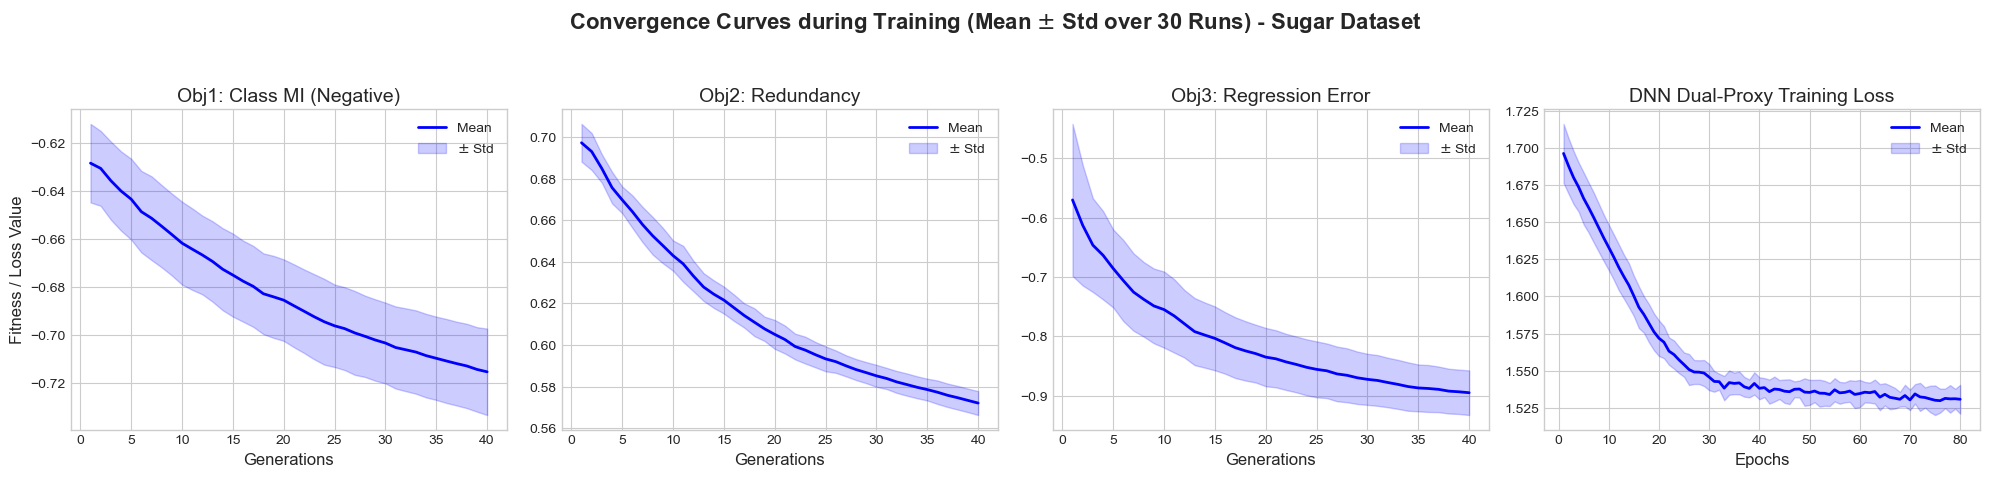

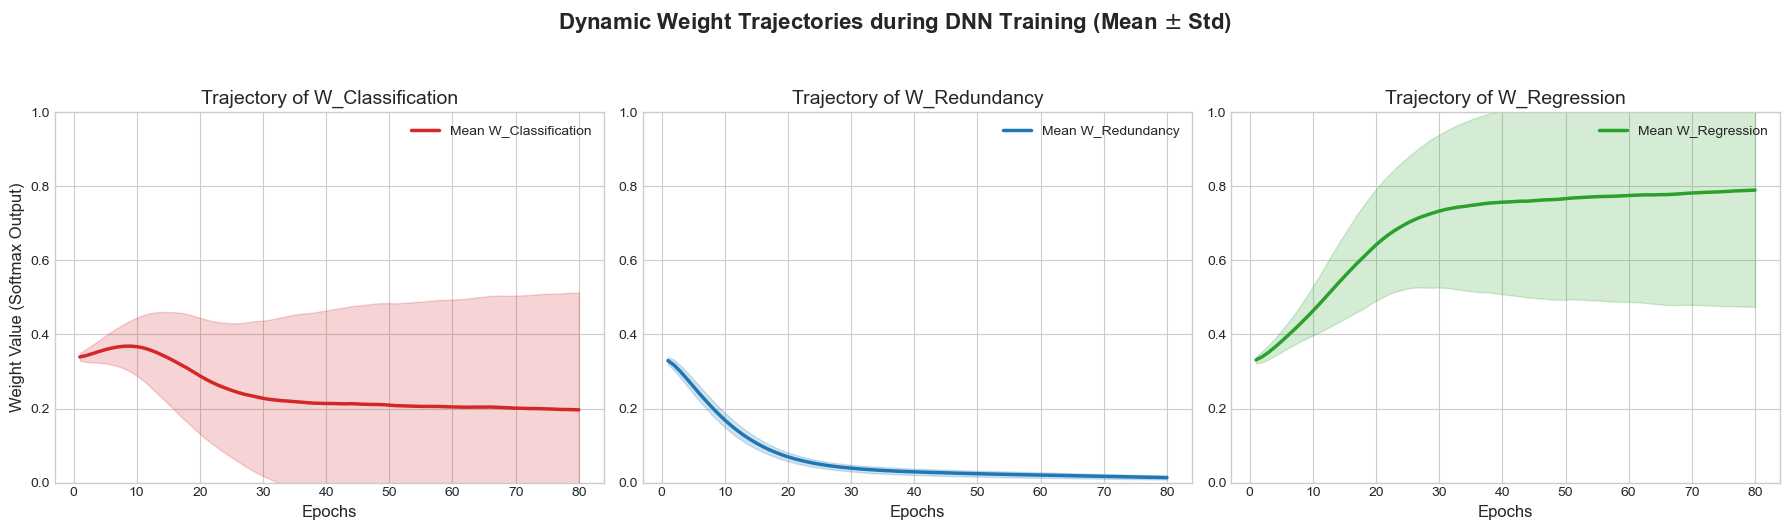

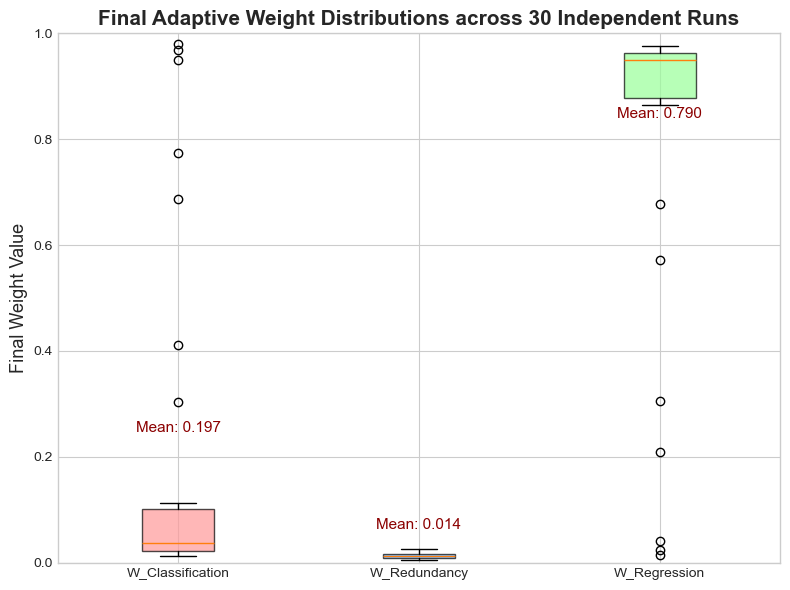

In [2]:
# ==============================================================
# 专属验证实验：Sugar Dataset (Dual Task: Classification & Regression)
# 包含：GA-NN (Adaptive) 30次运行 + 自动绘制收敛曲线与权重分布箱线图
# 运行环境：Jupyter Notebook 兼容版
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import time
import torch
import matplotlib.pyplot as plt

# --- Sklearn ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# --- Ours ---
# Ensure these imports match your project structure
from utils.data_loader import load_sugar_data
from core.ga_utils import jfs, keep_elite
from core.fitness_fast import Obj_Max_MI_Fast, Obj2_Min_Redundancy_Safe, Obj_Min_Regression_Safe
from core.networks import train_softmask_dnn_dual_proxy

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def calc_mean_std(x): 
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def get_top_k(scores, k):
    idx = np.argsort(scores)[::-1][:k]
    return idx if len(idx) > 0 else np.array([0])

# ==============================================================
# 1. Core Evaluation Routine (OURS ONLY)
# ==============================================================
def run_ours_only_sugar(feat, y_class, y_reg, run_idx, args):
    current_seed = 42 + run_idx
    set_seed(current_seed)
    
    # --- 数据划分 ---
    xt_tr, xt_te, yc_tr, yc_te, yr_tr, yr_te = train_test_split(
        feat, y_class, y_reg, test_size=0.3, stratify=y_class, random_state=current_seed
    )
    
    # 内部划分为 GA Obj3 (Regression Proxy) 提供 Train/Val 验证集
    xt_in, xv_in, yc_in, yc_val, yr_in, yr_val = train_test_split(
        xt_tr, yc_tr, yr_tr, test_size=0.25, stratify=yc_tr, random_state=current_seed
    )
    
    print(f"\n  [Run {run_idx}/{args.n_run}] Pre-computing Mutual Information...")
    mi_class = mutual_info_classif(xt_in, yc_in, random_state=current_seed)
    
    opts = {
        'xt_in': xt_in, 
        'yt_in': yr_in, 
        'xv_in': xv_in, 
        'yv_in': yr_val, 
        'mi_class': mi_class, 
        'N': 91, 
        'T': 40, 
        'CR': 0.8, 
        'MR': 0.01
    }
    
    results = []
    clf_lda = LinearDiscriminantAnalysis()
    reg_rf = RandomForestRegressor(n_estimators=50, random_state=42)
    
    print(f"    -> Optimizing with GA-NN (Adaptive)...")
    
    start_time = time.time()
    
    # 1. 独立单目标 GA 搜索 (记录收敛曲线)
    res1 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_class'))
    res2 = jfs(opts, Obj2_Min_Redundancy_Safe)
    res3 = jfs(opts, Obj_Min_Regression_Safe)
    
    curve1 = res1.get('curve', [])
    curve2 = res2.get('curve', [])
    curve3 = res3.get('curve', [])
    
    # 2. 提取精英解
    pop1 = keep_elite(**res1)
    pop2 = keep_elite(**res2)
    pop3 = keep_elite(**res3)
    
    # 3. 双任务深度特征融合 (记录最终的动态权重 lam, w_hist 和 Loss 历史 l_hist)
    sc_ad, lam, w_hist, l_hist = train_softmask_dnn_dual_proxy(
        pop1, pop2, pop3, xt_tr, yc_tr, yr_tr, xt_tr.shape[1], True, temp_scale=5.0
    )
    
    elapsed_time = time.time() - start_time
    
    # 验证分类精度与回归 R2 (K=1..15)
    for k in range(1, 16):
        idx = get_top_k(sc_ad, k)
        
        # Classification (LDA)
        clf_lda.fit(xt_tr[:, idx], yc_tr)
        acc = clf_lda.score(xt_te[:, idx], yc_te)
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Classification", "Model": "LDA", "Score": acc,
            "Time_Seconds": elapsed_time
        })
        
        # Regression (RF)
        reg_rf.fit(xt_tr[:, idx], yr_tr)
        r2 = r2_score(yr_te, reg_rf.predict(xt_te[:, idx]))
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Regression", "Model": "RF", "Score": r2,
            "Time_Seconds": elapsed_time
        })
            
    # 返回评估结果与绘图所需的历史记录
    return results, (curve1, curve2, curve3, l_hist, lam, w_hist)

# ==============================================================
# 2. Orchestrator & Execution
# ==============================================================
def run_benchmark(features, class_labels, regression_target, args):
    y_class = np.asarray(class_labels)
    y_reg = np.asarray(regression_target)
    
    feat = normalize(np.asarray(features), norm='l1')

    all_results = []
    
    # 绘图数据存储器
    all_c1, all_c2, all_c3 = [], [], []
    all_loss, all_weights, all_w_hist = [], [], []

    print("="*80)
    print(f"Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Sugar): {args.n_run} Runs")
    print("="*80)
    
    global_start_time = time.time()
    
    for run_idx in range(1, args.n_run + 1):
        res, histories = run_ours_only_sugar(feat, y_class, y_reg, run_idx, args)
        all_results.extend(res)
        
        # 收集绘图数据
        c1, c2, c3, l_hist, lam, w_hist = histories
        all_c1.append(c1)
        all_c2.append(c2)
        all_c3.append(c3)
        all_loss.append(l_hist)
        all_weights.append(lam)
        all_w_hist.append(w_hist)

    # ==============================================================
    # 3. Output Generation
    # ==============================================================
    df = pd.DataFrame(all_results)

    print("\n\n" + "="*80)
    print("             FINAL OURS-ONLY OUTPUT TABLES (Mean ± Std)")
    print("="*80)
    
    # 1. Classification (LDA) Table
    df_lda = df[(df["Task"] == "Classification") & (df["Model"] == "LDA")]
    if not df_lda.empty:
        tb_lda = df_lda.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 1] Classification Accuracy (LDA)")
        print(tb_lda)
        tb_lda.to_csv("Final_Sugar_Class_LDA_Ours.csv")
    
    # 2. Regression (RF) Table
    df_rf = df[(df["Task"] == "Regression") & (df["Model"] == "RF")]
    if not df_rf.empty:
        tb_rf = df_rf.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 2] Regression R2 Score (RF)")
        print(tb_rf)
        tb_rf.to_csv("Final_Sugar_Reg_RF_Ours.csv")

    # 3. Execution Time Table
    tb_time = df.pivot_table(index="Method", values="Time_Seconds", aggfunc=calc_mean_std)
    print("\n[TABLE 3] Execution Time (Seconds)")
    print(tb_time)
    tb_time.to_csv("Final_Sugar_Time_Ours.csv")

    total_minutes = (time.time() - global_start_time) / 60
    print(f"\n-> GA-NN (Adaptive) 30 次独立运行测试完毕！共耗时 {total_minutes:.2f} 分钟。开始绘制审稿人要求的图表...\n")

    # ==============================================================
    # 4. Plotting for Reviewers (收敛曲线、最终权重与权重变化轨迹)
    # ==============================================================
    plot_reviewer_figures(all_c1, all_c2, all_c3, all_loss, all_weights, all_w_hist)


def plot_reviewer_figures(c1_list, c2_list, c3_list, loss_list, weights_list, w_hist_list):
    """专门为审稿人生成论文级别的图表 (Sugar Dataset 专属)"""
    
    c1_arr = np.array(c1_list)
    c2_arr = np.array(c2_list)
    c3_arr = np.array(c3_list)
    loss_arr = np.array(loss_list)
    weights_arr = np.array(weights_list)         # shape: (30, 3)
    w_hist_arr = np.array(w_hist_list)           # shape: (30, epochs, 3)

    plt.style.use('seaborn-v0_8-whitegrid')
    
    # ---------------------------------------------------------
    # 图 1: 收敛曲线 (GA 3个目标 + DNN Loss)
    # ---------------------------------------------------------
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    fig.suptitle('Convergence Curves during Training (Mean $\pm$ Std over 30 Runs) - Sugar Dataset', fontsize=16, fontweight='bold', y=1.05)

    titles = ['Obj1: Class MI (Negative)', 'Obj2: Redundancy', 'Obj3: Regression Error', 'DNN Dual-Proxy Training Loss']
    data_arrays = [c1_arr, c2_arr, c3_arr, loss_arr]
    x_labels = ['Generations'] * 3 + ['Epochs']

    for i in range(4):
        ax = axes[i]
        mean_val = np.mean(data_arrays[i], axis=0)
        std_val = np.std(data_arrays[i], axis=0)
        x_axis = np.arange(1, len(mean_val) + 1)
        
        ax.plot(x_axis, mean_val, color='b', linewidth=2, label='Mean')
        ax.fill_between(x_axis, mean_val - std_val, mean_val + std_val, color='b', alpha=0.2, label='$\pm$ Std')
        
        ax.set_title(titles[i], fontsize=14)
        ax.set_xlabel(x_labels[i], fontsize=12)
        if i == 0: ax.set_ylabel('Fitness / Loss Value', fontsize=12)
        ax.legend()

    plt.tight_layout()
    plt.savefig("Sugar_Fig1_Convergence.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 2: 动态权重变化轨迹 (3个子图，展示 w1, w2, w3 的 Epoch 变化)
    # ---------------------------------------------------------
    fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
    fig2.suptitle('Dynamic Weight Trajectories during DNN Training (Mean $\pm$ Std)', fontsize=16, fontweight='bold', y=1.05)

    weight_names = ['W_Classification', 'W_Redundancy', 'W_Regression']
    line_colors = ['#d62728', '#1f77b4', '#2ca02c'] # 红, 蓝, 绿

    for i in range(3):
        ax = axes2[i]
        mean_w = np.mean(w_hist_arr[:, :, i], axis=0)
        std_w = np.std(w_hist_arr[:, :, i], axis=0)
        epochs_x = np.arange(1, len(mean_w) + 1)

        ax.plot(epochs_x, mean_w, color=line_colors[i], linewidth=2.5, label=f'Mean {weight_names[i]}')
        ax.fill_between(epochs_x, mean_w - std_w, mean_w + std_w, color=line_colors[i], alpha=0.2)

        ax.set_title(f'Trajectory of {weight_names[i]}', fontsize=14)
        ax.set_xlabel('Epochs', fontsize=12)
        if i == 0: ax.set_ylabel('Weight Value (Softmax Output)', fontsize=12)
        ax.set_ylim(0, 1.0)
        ax.legend()

    plt.tight_layout()
    plt.savefig("Sugar_Fig2_Weight_Trajectories.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 3: 最终自适应权重分布 (Boxplot)
    # ---------------------------------------------------------
    plt.figure(figsize=(8, 6))
    
    # 使用箱线图展示 30 次运行的权重分布
    box = plt.boxplot([weights_arr[:, 0], weights_arr[:, 1], weights_arr[:, 2]], 
                      labels=['W_Classification', 'W_Redundancy', 'W_Regression'],
                      patch_artist=True)
    
    colors = ['#FF9999', '#66B2FF', '#99FF99']
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
        
    plt.title('Final Adaptive Weight Distributions across 30 Independent Runs', fontsize=15, fontweight='bold')
    plt.ylabel('Final Weight Value', fontsize=13)
    plt.ylim(0, 1.0)
    
    # 标注出均值
    means = np.mean(weights_arr, axis=0)
    for i, mean_val in enumerate(means):
        plt.text(i+1, mean_val + 0.05, f'Mean: {mean_val:.3f}', horizontalalignment='center', fontsize=11, color='darkred')

    plt.tight_layout()
    plt.savefig("Sugar_Fig3_Weight_Boxplot.pdf", bbox_inches='tight', dpi=300)
    plt.show()

if __name__ == "__main__":
    class Args:
        n_run = 30 # 审稿人要求的 30 次独立运行
        
    args = Args()

    try:
        print("Loading Data...")
        X, yc, yr = load_sugar_data()
        run_benchmark(X, yc, yr, args)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        X_mock = np.random.rand(150, 50)
        yc_mock = np.random.randint(0, 2, 150)
        yr_mock = np.random.rand(150) * 10 + 5
        run_benchmark(X_mock, yc_mock, yr_mock, args)

Loading Data...
Loading Sugar Dataset...
Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Sugar): 30 Runs

  [Run 1/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 2/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 3/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 4/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 5/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 6/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 7/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 8/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 9/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 10/30] Pre-computing Mutual Information...
    -> Opt

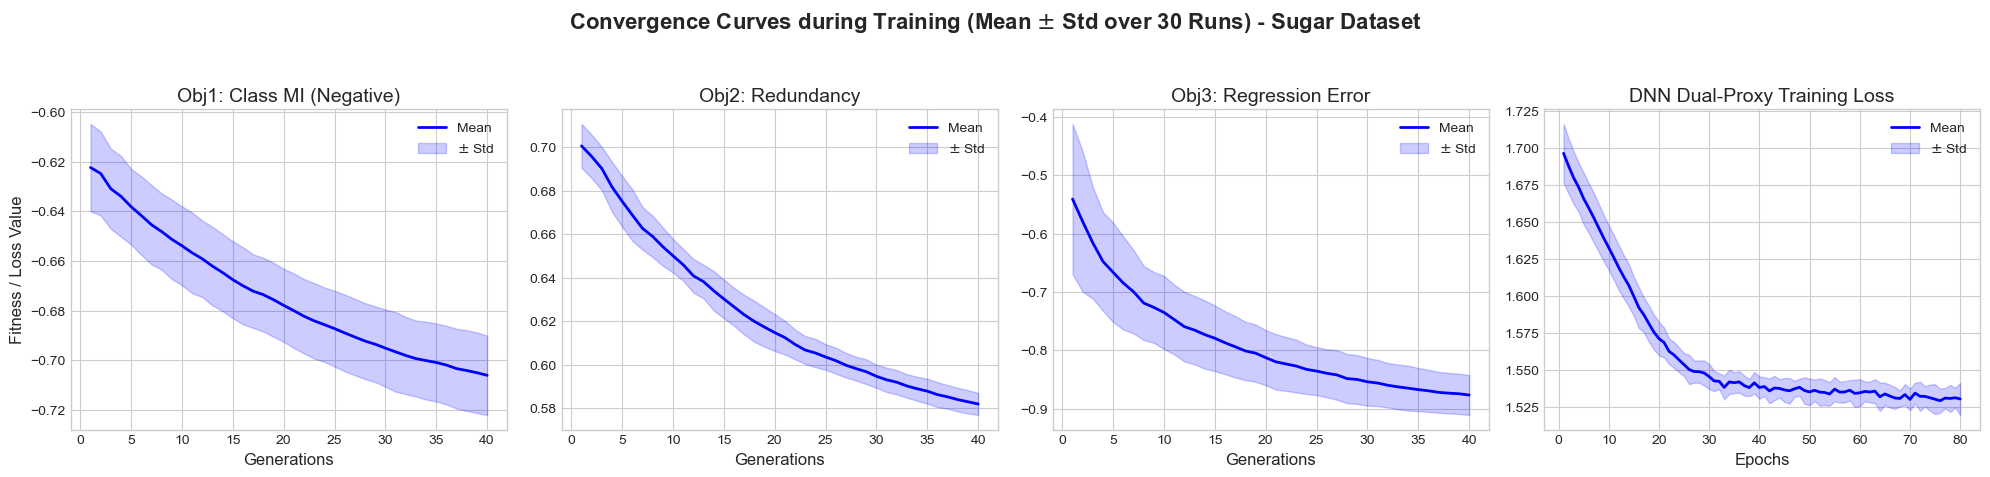

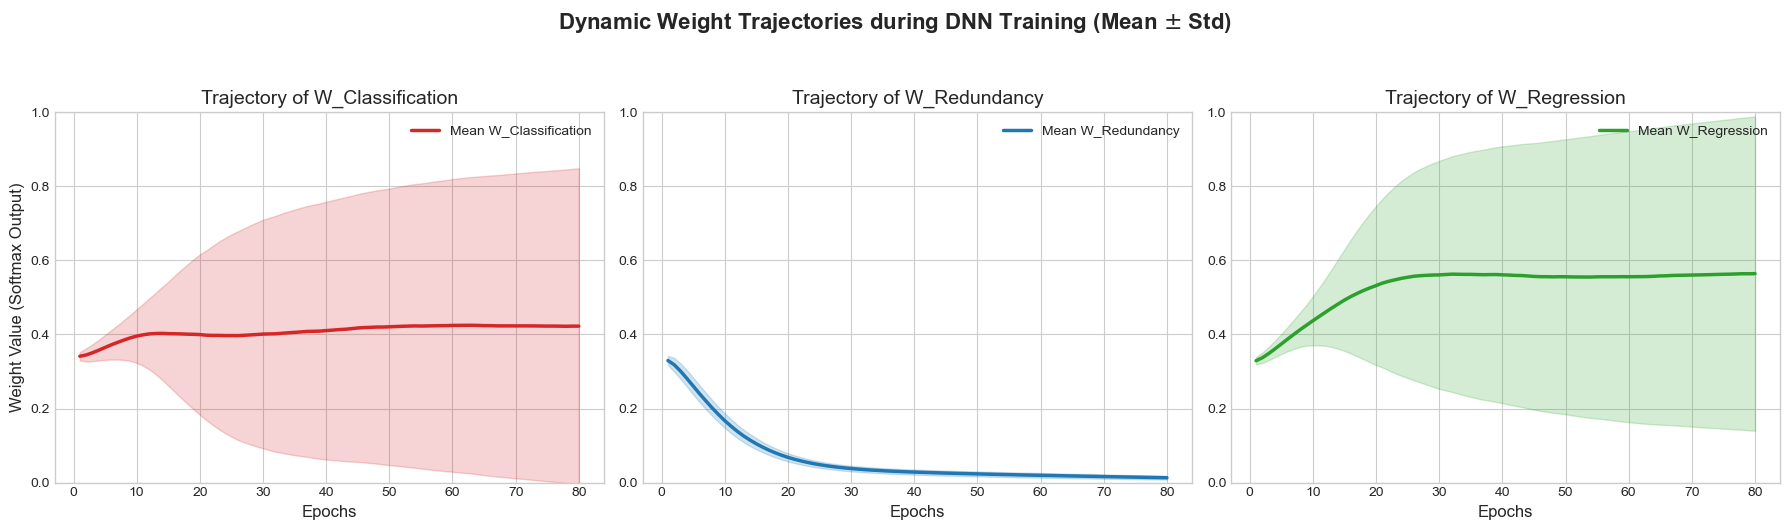

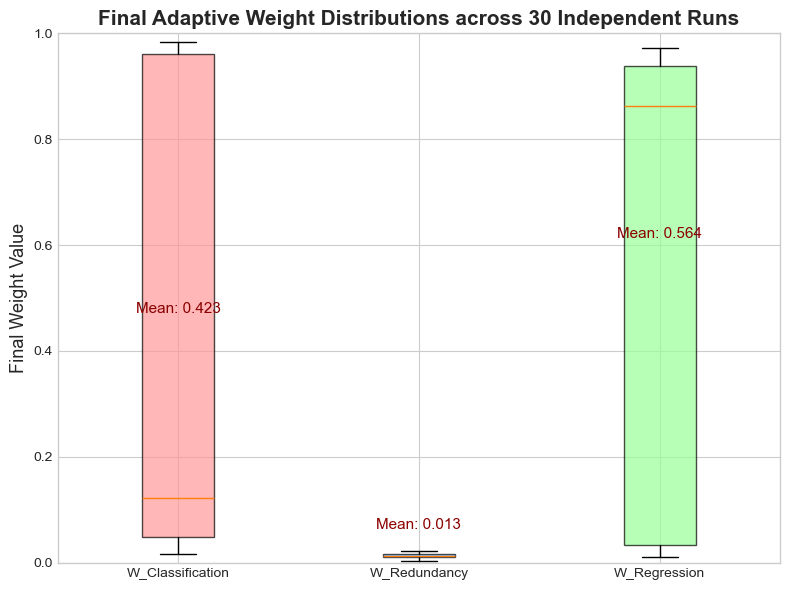

In [1]:
# ==============================================================
# 专属验证实验：Sugar Dataset (Dual Task: Classification & Regression)
# 包含：GA-NN (Adaptive) 30次运行 + 自动绘制收敛曲线与权重分布箱线图
# 运行环境：Jupyter Notebook 兼容版
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import time
import torch
import matplotlib.pyplot as plt

# --- Sklearn ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# --- Ours ---
# Ensure these imports match your project structure
from utils.data_loader import load_sugar_data
from core.ga_utils import jfs, keep_elite
from core.fitness_fast import Obj_Max_MI_Fast, Obj2_Min_Redundancy_Safe, Obj_Min_Regression_Safe
from core.networks import train_softmask_dnn_dual_proxy

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def calc_mean_std(x): 
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def get_top_k(scores, k):
    idx = np.argsort(scores)[::-1][:k]
    return idx if len(idx) > 0 else np.array([0])

# ==============================================================
# 1. Core Evaluation Routine (OURS ONLY)
# ==============================================================
def run_ours_only_sugar(feat, y_class, y_reg, run_idx, args):
    current_seed = 42 + run_idx
    set_seed(current_seed)
    
    # --- 数据划分 ---
    xt_tr, xt_te, yc_tr, yc_te, yr_tr, yr_te = train_test_split(
        feat, y_class, y_reg, test_size=0.3, stratify=y_class, random_state=current_seed
    )
    
    # 内部划分为 GA Obj3 (Regression Proxy) 提供 Train/Val 验证集
    xt_in, xv_in, yc_in, yc_val, yr_in, yr_val = train_test_split(
        xt_tr, yc_tr, yr_tr, test_size=0.25, stratify=yc_tr, random_state=current_seed
    )
    
    print(f"\n  [Run {run_idx}/{args.n_run}] Pre-computing Mutual Information...")
    mi_class = mutual_info_classif(xt_in, yc_in, random_state=current_seed)
    
    opts = {
        'xt_in': xt_in, 
        'yt_in': yr_in, 
        'xv_in': xv_in, 
        'yv_in': yr_val, 
        'mi_class': mi_class, 
        'N': 40, 
        'T': 40, 
        'CR': 0.8, 
        'MR': 0.01
    }
    
    results = []
    clf_lda = LinearDiscriminantAnalysis()
    reg_rf = RandomForestRegressor(n_estimators=50, random_state=42)
    
    print(f"    -> Optimizing with GA-NN (Adaptive)...")
    
    start_time = time.time()
    
    # 1. 独立单目标 GA 搜索 (记录收敛曲线)
    res1 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_class'))
    res2 = jfs(opts, Obj2_Min_Redundancy_Safe)
    res3 = jfs(opts, Obj_Min_Regression_Safe)
    
    curve1 = res1.get('curve', [])
    curve2 = res2.get('curve', [])
    curve3 = res3.get('curve', [])
    
    # 2. 提取精英解
    pop1 = keep_elite(**res1)
    pop2 = keep_elite(**res2)
    pop3 = keep_elite(**res3)
    
    # 3. 双任务深度特征融合 (记录最终的动态权重 lam, w_hist 和 Loss 历史 l_hist)
    sc_ad, lam, w_hist, l_hist = train_softmask_dnn_dual_proxy(
        pop1, pop2, pop3, xt_tr, yc_tr, yr_tr, xt_tr.shape[1], True, temp_scale=5.0
    )
    
    elapsed_time = time.time() - start_time
    
    # 验证分类精度与回归 R2 (K=1..15)
    for k in range(1, 16):
        idx = get_top_k(sc_ad, k)
        
        # Classification (LDA)
        clf_lda.fit(xt_tr[:, idx], yc_tr)
        acc = clf_lda.score(xt_te[:, idx], yc_te)
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Classification", "Model": "LDA", "Score": acc,
            "Time_Seconds": elapsed_time
        })
        
        # Regression (RF)
        reg_rf.fit(xt_tr[:, idx], yr_tr)
        r2 = r2_score(yr_te, reg_rf.predict(xt_te[:, idx]))
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Regression", "Model": "RF", "Score": r2,
            "Time_Seconds": elapsed_time
        })
            
    # 返回评估结果与绘图所需的历史记录
    return results, (curve1, curve2, curve3, l_hist, lam, w_hist)

# ==============================================================
# 2. Orchestrator & Execution
# ==============================================================
def run_benchmark(features, class_labels, regression_target, args):
    y_class = np.asarray(class_labels)
    y_reg = np.asarray(regression_target)
    
    feat = normalize(np.asarray(features), norm='l1')

    all_results = []
    
    # 绘图数据存储器
    all_c1, all_c2, all_c3 = [], [], []
    all_loss, all_weights, all_w_hist = [], [], []

    print("="*80)
    print(f"Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Sugar): {args.n_run} Runs")
    print("="*80)
    
    global_start_time = time.time()
    
    for run_idx in range(1, args.n_run + 1):
        res, histories = run_ours_only_sugar(feat, y_class, y_reg, run_idx, args)
        all_results.extend(res)
        
        # 收集绘图数据
        c1, c2, c3, l_hist, lam, w_hist = histories
        all_c1.append(c1)
        all_c2.append(c2)
        all_c3.append(c3)
        all_loss.append(l_hist)
        all_weights.append(lam)
        all_w_hist.append(w_hist)

    # ==============================================================
    # 3. Output Generation
    # ==============================================================
    df = pd.DataFrame(all_results)

    print("\n\n" + "="*80)
    print("             FINAL OURS-ONLY OUTPUT TABLES (Mean ± Std)")
    print("="*80)
    
    # 1. Classification (LDA) Table
    df_lda = df[(df["Task"] == "Classification") & (df["Model"] == "LDA")]
    if not df_lda.empty:
        tb_lda = df_lda.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 1] Classification Accuracy (LDA)")
        print(tb_lda)
        tb_lda.to_csv("Final_Sugar_Class_LDA_Ours.csv")
    
    # 2. Regression (RF) Table
    df_rf = df[(df["Task"] == "Regression") & (df["Model"] == "RF")]
    if not df_rf.empty:
        tb_rf = df_rf.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 2] Regression R2 Score (RF)")
        print(tb_rf)
        tb_rf.to_csv("Final_Sugar_Reg_RF_Ours.csv")

    # 3. Execution Time Table
    tb_time = df.pivot_table(index="Method", values="Time_Seconds", aggfunc=calc_mean_std)
    print("\n[TABLE 3] Execution Time (Seconds)")
    print(tb_time)
    tb_time.to_csv("Final_Sugar_Time_Ours.csv")

    total_minutes = (time.time() - global_start_time) / 60
    print(f"\n-> GA-NN (Adaptive) 30 次独立运行测试完毕！共耗时 {total_minutes:.2f} 分钟。开始绘制审稿人要求的图表...\n")

    # ==============================================================
    # 4. Plotting for Reviewers (收敛曲线、最终权重与权重变化轨迹)
    # ==============================================================
    plot_reviewer_figures(all_c1, all_c2, all_c3, all_loss, all_weights, all_w_hist)


def plot_reviewer_figures(c1_list, c2_list, c3_list, loss_list, weights_list, w_hist_list):
    """专门为审稿人生成论文级别的图表 (Sugar Dataset 专属)"""
    
    c1_arr = np.array(c1_list)
    c2_arr = np.array(c2_list)
    c3_arr = np.array(c3_list)
    loss_arr = np.array(loss_list)
    weights_arr = np.array(weights_list)         # shape: (30, 3)
    w_hist_arr = np.array(w_hist_list)           # shape: (30, epochs, 3)

    plt.style.use('seaborn-v0_8-whitegrid')
    
    # ---------------------------------------------------------
    # 图 1: 收敛曲线 (GA 3个目标 + DNN Loss)
    # ---------------------------------------------------------
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    fig.suptitle('Convergence Curves during Training (Mean $\pm$ Std over 30 Runs) - Sugar Dataset', fontsize=16, fontweight='bold', y=1.05)

    titles = ['Obj1: Class MI (Negative)', 'Obj2: Redundancy', 'Obj3: Regression Error', 'DNN Dual-Proxy Training Loss']
    data_arrays = [c1_arr, c2_arr, c3_arr, loss_arr]
    x_labels = ['Generations'] * 3 + ['Epochs']

    for i in range(4):
        ax = axes[i]
        mean_val = np.mean(data_arrays[i], axis=0)
        std_val = np.std(data_arrays[i], axis=0)
        x_axis = np.arange(1, len(mean_val) + 1)
        
        ax.plot(x_axis, mean_val, color='b', linewidth=2, label='Mean')
        ax.fill_between(x_axis, mean_val - std_val, mean_val + std_val, color='b', alpha=0.2, label='$\pm$ Std')
        
        ax.set_title(titles[i], fontsize=14)
        ax.set_xlabel(x_labels[i], fontsize=12)
        if i == 0: ax.set_ylabel('Fitness / Loss Value', fontsize=12)
        ax.legend()

    plt.tight_layout()
    plt.savefig("Sugar_Fig1_Convergence.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 2: 动态权重变化轨迹 (3个子图，展示 w1, w2, w3 的 Epoch 变化)
    # ---------------------------------------------------------
    fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
    fig2.suptitle('Dynamic Weight Trajectories during DNN Training (Mean $\pm$ Std)', fontsize=16, fontweight='bold', y=1.05)

    weight_names = ['W_Classification', 'W_Redundancy', 'W_Regression']
    line_colors = ['#d62728', '#1f77b4', '#2ca02c'] # 红, 蓝, 绿

    for i in range(3):
        ax = axes2[i]
        mean_w = np.mean(w_hist_arr[:, :, i], axis=0)
        std_w = np.std(w_hist_arr[:, :, i], axis=0)
        epochs_x = np.arange(1, len(mean_w) + 1)

        ax.plot(epochs_x, mean_w, color=line_colors[i], linewidth=2.5, label=f'Mean {weight_names[i]}')
        ax.fill_between(epochs_x, mean_w - std_w, mean_w + std_w, color=line_colors[i], alpha=0.2)

        ax.set_title(f'Trajectory of {weight_names[i]}', fontsize=14)
        ax.set_xlabel('Epochs', fontsize=12)
        if i == 0: ax.set_ylabel('Weight Value (Softmax Output)', fontsize=12)
        ax.set_ylim(0, 1.0)
        ax.legend()

    plt.tight_layout()
    plt.savefig("Sugar_Fig2_Weight_Trajectories.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 3: 最终自适应权重分布 (Boxplot)
    # ---------------------------------------------------------
    plt.figure(figsize=(8, 6))
    
    # 使用箱线图展示 30 次运行的权重分布
    box = plt.boxplot([weights_arr[:, 0], weights_arr[:, 1], weights_arr[:, 2]], 
                      labels=['W_Classification', 'W_Redundancy', 'W_Regression'],
                      patch_artist=True)
    
    colors = ['#FF9999', '#66B2FF', '#99FF99']
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
        
    plt.title('Final Adaptive Weight Distributions across 30 Independent Runs', fontsize=15, fontweight='bold')
    plt.ylabel('Final Weight Value', fontsize=13)
    plt.ylim(0, 1.0)
    
    # 标注出均值
    means = np.mean(weights_arr, axis=0)
    for i, mean_val in enumerate(means):
        plt.text(i+1, mean_val + 0.05, f'Mean: {mean_val:.3f}', horizontalalignment='center', fontsize=11, color='darkred')

    plt.tight_layout()
    plt.savefig("Sugar_Fig3_Weight_Boxplot.pdf", bbox_inches='tight', dpi=300)
    plt.show()

if __name__ == "__main__":
    class Args:
        n_run = 30 # 审稿人要求的 30 次独立运行
        
    args = Args()

    try:
        print("Loading Data...")
        X, yc, yr = load_sugar_data()
        run_benchmark(X, yc, yr, args)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        X_mock = np.random.rand(150, 50)
        yc_mock = np.random.randint(0, 2, 150)
        yr_mock = np.random.rand(150) * 10 + 5
        run_benchmark(X_mock, yc_mock, yr_mock, args)

Loading Data...
Loading Sugar Dataset...
Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Sugar): 30 Runs

  [Run 1/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 2/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 3/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 4/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 5/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 6/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 7/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 8/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 9/30] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Run 10/30] Pre-computing Mutual Information...
    -> Opt

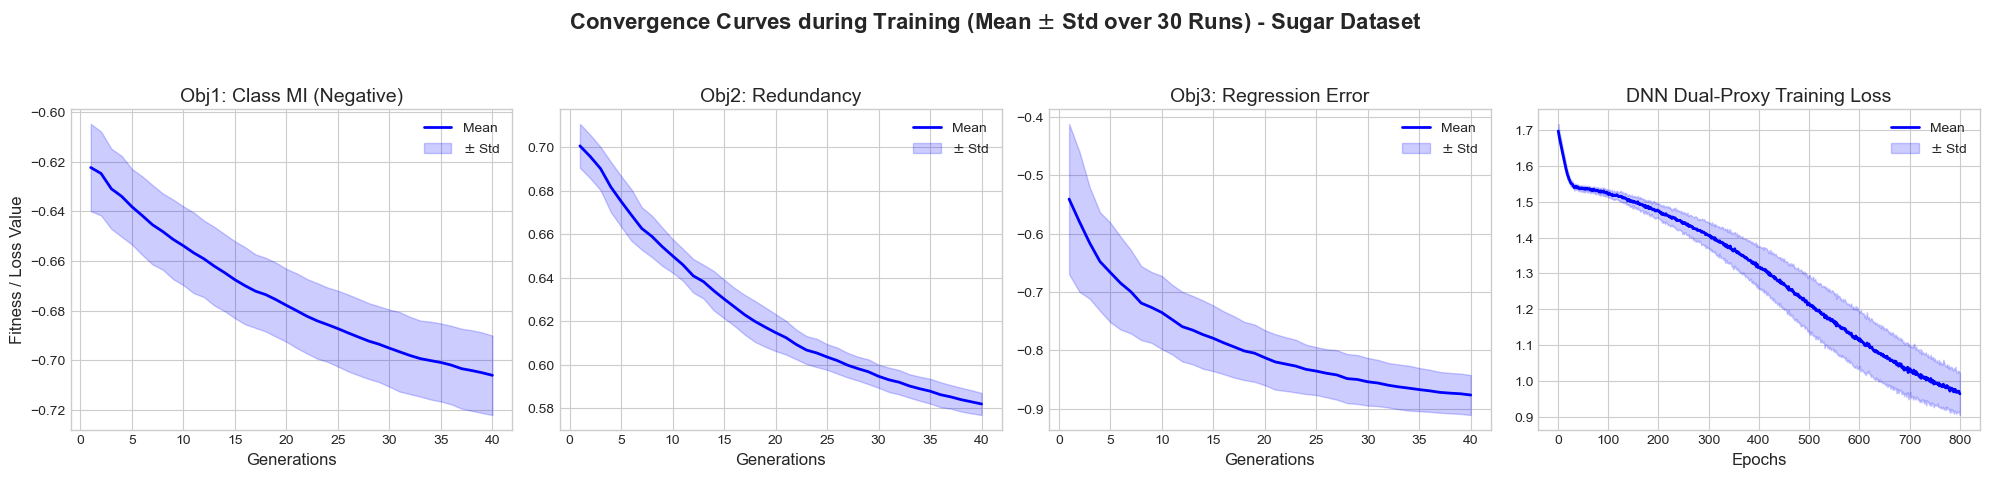

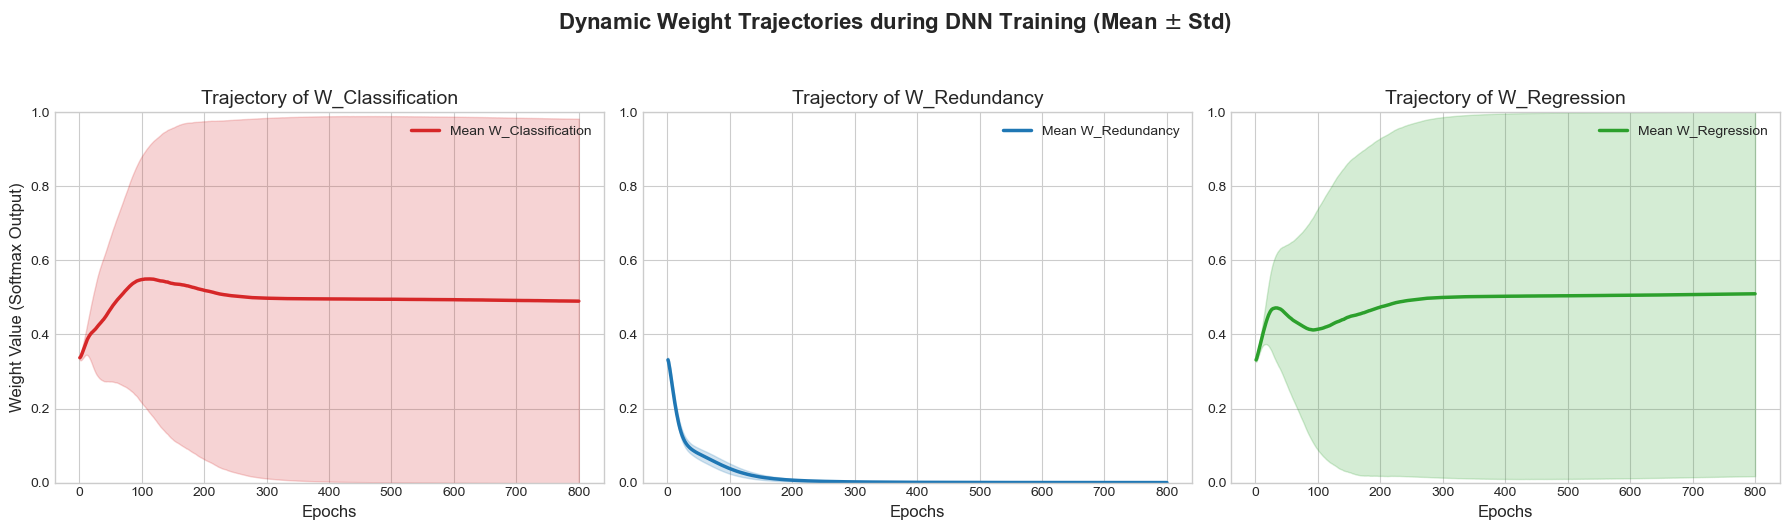

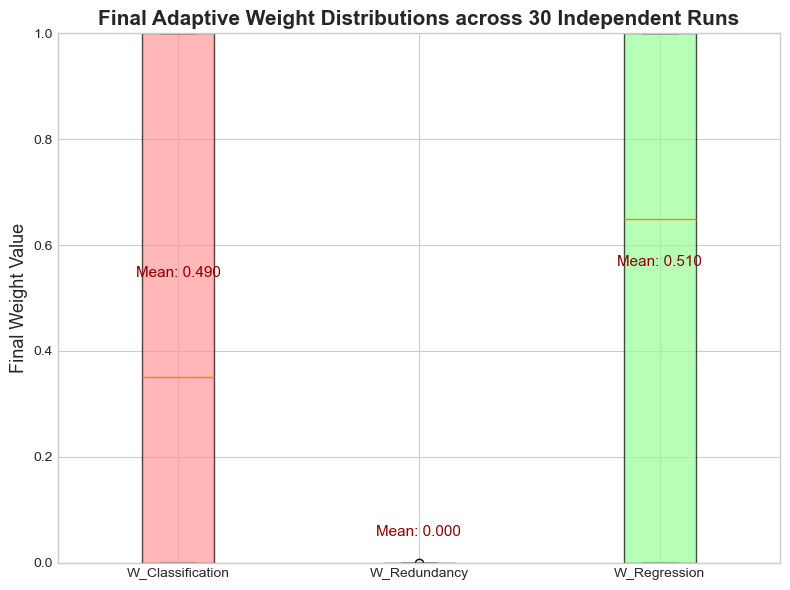

In [1]:
# ==============================================================
# 专属验证实验：Sugar Dataset (Dual Task: Classification & Regression)
# 包含：GA-NN (Adaptive) 30次运行 + 自动绘制收敛曲线与权重分布箱线图
# 运行环境：Jupyter Notebook 兼容版
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import time
import torch
import matplotlib.pyplot as plt

# --- Sklearn ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# --- Ours ---
# Ensure these imports match your project structure
from utils.data_loader import load_sugar_data
from core.ga_utils import jfs, keep_elite
from core.fitness_fast import Obj_Max_MI_Fast, Obj2_Min_Redundancy_Safe, Obj_Min_Regression_Safe
from core.networks import train_softmask_dnn_dual_proxy

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def calc_mean_std(x): 
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def get_top_k(scores, k):
    idx = np.argsort(scores)[::-1][:k]
    return idx if len(idx) > 0 else np.array([0])

# ==============================================================
# 1. Core Evaluation Routine (OURS ONLY)
# ==============================================================
def run_ours_only_sugar(feat, y_class, y_reg, run_idx, args):
    current_seed = 42 + run_idx
    set_seed(current_seed)
    
    # --- 数据划分 ---
    xt_tr, xt_te, yc_tr, yc_te, yr_tr, yr_te = train_test_split(
        feat, y_class, y_reg, test_size=0.3, stratify=y_class, random_state=current_seed
    )
    
    # 内部划分为 GA Obj3 (Regression Proxy) 提供 Train/Val 验证集
    xt_in, xv_in, yc_in, yc_val, yr_in, yr_val = train_test_split(
        xt_tr, yc_tr, yr_tr, test_size=0.25, stratify=yc_tr, random_state=current_seed
    )
    
    print(f"\n  [Run {run_idx}/{args.n_run}] Pre-computing Mutual Information...")
    mi_class = mutual_info_classif(xt_in, yc_in, random_state=current_seed)
    
    opts = {
        'xt_in': xt_in, 
        'yt_in': yr_in, 
        'xv_in': xv_in, 
        'yv_in': yr_val, 
        'mi_class': mi_class, 
        'N': 40, 
        'T': 40, 
        'CR': 0.8, 
        'MR': 0.01
    }
    
    results = []
    clf_lda = LinearDiscriminantAnalysis()
    reg_rf = RandomForestRegressor(n_estimators=50, random_state=42)
    
    print(f"    -> Optimizing with GA-NN (Adaptive)...")
    
    start_time = time.time()
    
    # 1. 独立单目标 GA 搜索 (记录收敛曲线)
    res1 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_class'))
    res2 = jfs(opts, Obj2_Min_Redundancy_Safe)
    res3 = jfs(opts, Obj_Min_Regression_Safe)
    
    curve1 = res1.get('curve', [])
    curve2 = res2.get('curve', [])
    curve3 = res3.get('curve', [])
    
    # 2. 提取精英解
    pop1 = keep_elite(**res1)
    pop2 = keep_elite(**res2)
    pop3 = keep_elite(**res3)
    
    # 3. 双任务深度特征融合 (记录最终的动态权重 lam, w_hist 和 Loss 历史 l_hist)
    sc_ad, lam, w_hist, l_hist = train_softmask_dnn_dual_proxy(
        pop1, pop2, pop3, xt_tr, yc_tr, yr_tr, xt_tr.shape[1], True, temp_scale=10.0
    )
    
    elapsed_time = time.time() - start_time
    
    # 验证分类精度与回归 R2 (K=1..15)
    for k in range(1, 16):
        idx = get_top_k(sc_ad, k)
        
        # Classification (LDA)
        clf_lda.fit(xt_tr[:, idx], yc_tr)
        acc = clf_lda.score(xt_te[:, idx], yc_te)
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Classification", "Model": "LDA", "Score": acc,
            "Time_Seconds": elapsed_time
        })
        
        # Regression (RF)
        reg_rf.fit(xt_tr[:, idx], yr_tr)
        r2 = r2_score(yr_te, reg_rf.predict(xt_te[:, idx]))
        results.append({
            "Run": run_idx, "Method": "GA-NN (Adaptive)", "K": k, 
            "Task": "Regression", "Model": "RF", "Score": r2,
            "Time_Seconds": elapsed_time
        })
            
    # 返回评估结果与绘图所需的历史记录
    return results, (curve1, curve2, curve3, l_hist, lam, w_hist)

# ==============================================================
# 2. Orchestrator & Execution
# ==============================================================
def run_benchmark(features, class_labels, regression_target, args):
    y_class = np.asarray(class_labels)
    y_reg = np.asarray(regression_target)
    
    feat = normalize(np.asarray(features), norm='l1')

    all_results = []
    
    # 绘图数据存储器
    all_c1, all_c2, all_c3 = [], [], []
    all_loss, all_weights, all_w_hist = [], [], []

    print("="*80)
    print(f"Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Sugar): {args.n_run} Runs")
    print("="*80)
    
    global_start_time = time.time()
    
    for run_idx in range(1, args.n_run + 1):
        res, histories = run_ours_only_sugar(feat, y_class, y_reg, run_idx, args)
        all_results.extend(res)
        
        # 收集绘图数据
        c1, c2, c3, l_hist, lam, w_hist = histories
        all_c1.append(c1)
        all_c2.append(c2)
        all_c3.append(c3)
        all_loss.append(l_hist)
        all_weights.append(lam)
        all_w_hist.append(w_hist)

    # ==============================================================
    # 3. Output Generation
    # ==============================================================
    df = pd.DataFrame(all_results)

    print("\n\n" + "="*80)
    print("             FINAL OURS-ONLY OUTPUT TABLES (Mean ± Std)")
    print("="*80)
    
    # 1. Classification (LDA) Table
    df_lda = df[(df["Task"] == "Classification") & (df["Model"] == "LDA")]
    if not df_lda.empty:
        tb_lda = df_lda.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 1] Classification Accuracy (LDA)")
        print(tb_lda)
        tb_lda.to_csv("Final_Sugar_Class_LDA_Ours.csv")
    
    # 2. Regression (RF) Table
    df_rf = df[(df["Task"] == "Regression") & (df["Model"] == "RF")]
    if not df_rf.empty:
        tb_rf = df_rf.pivot_table(index="K", columns="Method", values="Score", aggfunc=calc_mean_std)
        print("\n[TABLE 2] Regression R2 Score (RF)")
        print(tb_rf)
        tb_rf.to_csv("Final_Sugar_Reg_RF_Ours.csv")

    # 3. Execution Time Table
    tb_time = df.pivot_table(index="Method", values="Time_Seconds", aggfunc=calc_mean_std)
    print("\n[TABLE 3] Execution Time (Seconds)")
    print(tb_time)
    tb_time.to_csv("Final_Sugar_Time_Ours.csv")

    total_minutes = (time.time() - global_start_time) / 60
    print(f"\n-> GA-NN (Adaptive) 30 次独立运行测试完毕！共耗时 {total_minutes:.2f} 分钟。开始绘制审稿人要求的图表...\n")

    # ==============================================================
    # 4. Plotting for Reviewers (收敛曲线、最终权重与权重变化轨迹)
    # ==============================================================
    plot_reviewer_figures(all_c1, all_c2, all_c3, all_loss, all_weights, all_w_hist)


def plot_reviewer_figures(c1_list, c2_list, c3_list, loss_list, weights_list, w_hist_list):
    """专门为审稿人生成论文级别的图表 (Sugar Dataset 专属)"""
    
    c1_arr = np.array(c1_list)
    c2_arr = np.array(c2_list)
    c3_arr = np.array(c3_list)
    loss_arr = np.array(loss_list)
    weights_arr = np.array(weights_list)         # shape: (30, 3)
    w_hist_arr = np.array(w_hist_list)           # shape: (30, epochs, 3)

    plt.style.use('seaborn-v0_8-whitegrid')
    
    # ---------------------------------------------------------
    # 图 1: 收敛曲线 (GA 3个目标 + DNN Loss)
    # ---------------------------------------------------------
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    fig.suptitle('Convergence Curves during Training (Mean $\pm$ Std over 30 Runs) - Sugar Dataset', fontsize=16, fontweight='bold', y=1.05)

    titles = ['Obj1: Class MI (Negative)', 'Obj2: Redundancy', 'Obj3: Regression Error', 'DNN Dual-Proxy Training Loss']
    data_arrays = [c1_arr, c2_arr, c3_arr, loss_arr]
    x_labels = ['Generations'] * 3 + ['Epochs']

    for i in range(4):
        ax = axes[i]
        mean_val = np.mean(data_arrays[i], axis=0)
        std_val = np.std(data_arrays[i], axis=0)
        x_axis = np.arange(1, len(mean_val) + 1)
        
        ax.plot(x_axis, mean_val, color='b', linewidth=2, label='Mean')
        ax.fill_between(x_axis, mean_val - std_val, mean_val + std_val, color='b', alpha=0.2, label='$\pm$ Std')
        
        ax.set_title(titles[i], fontsize=14)
        ax.set_xlabel(x_labels[i], fontsize=12)
        if i == 0: ax.set_ylabel('Fitness / Loss Value', fontsize=12)
        ax.legend()

    plt.tight_layout()
    plt.savefig("Sugar_Fig1_Convergence.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 2: 动态权重变化轨迹 (3个子图，展示 w1, w2, w3 的 Epoch 变化)
    # ---------------------------------------------------------
    fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
    fig2.suptitle('Dynamic Weight Trajectories during DNN Training (Mean $\pm$ Std)', fontsize=16, fontweight='bold', y=1.05)

    weight_names = ['W_Classification', 'W_Redundancy', 'W_Regression']
    line_colors = ['#d62728', '#1f77b4', '#2ca02c'] # 红, 蓝, 绿

    for i in range(3):
        ax = axes2[i]
        mean_w = np.mean(w_hist_arr[:, :, i], axis=0)
        std_w = np.std(w_hist_arr[:, :, i], axis=0)
        epochs_x = np.arange(1, len(mean_w) + 1)

        ax.plot(epochs_x, mean_w, color=line_colors[i], linewidth=2.5, label=f'Mean {weight_names[i]}')
        ax.fill_between(epochs_x, mean_w - std_w, mean_w + std_w, color=line_colors[i], alpha=0.2)

        ax.set_title(f'Trajectory of {weight_names[i]}', fontsize=14)
        ax.set_xlabel('Epochs', fontsize=12)
        if i == 0: ax.set_ylabel('Weight Value (Softmax Output)', fontsize=12)
        ax.set_ylim(0, 1.0)
        ax.legend()

    plt.tight_layout()
    plt.savefig("Sugar_Fig2_Weight_Trajectories.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 3: 最终自适应权重分布 (Boxplot)
    # ---------------------------------------------------------
    plt.figure(figsize=(8, 6))
    
    # 使用箱线图展示 30 次运行的权重分布
    box = plt.boxplot([weights_arr[:, 0], weights_arr[:, 1], weights_arr[:, 2]], 
                      labels=['W_Classification', 'W_Redundancy', 'W_Regression'],
                      patch_artist=True)
    
    colors = ['#FF9999', '#66B2FF', '#99FF99']
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
        
    plt.title('Final Adaptive Weight Distributions across 30 Independent Runs', fontsize=15, fontweight='bold')
    plt.ylabel('Final Weight Value', fontsize=13)
    plt.ylim(0, 1.0)
    
    # 标注出均值
    means = np.mean(weights_arr, axis=0)
    for i, mean_val in enumerate(means):
        plt.text(i+1, mean_val + 0.05, f'Mean: {mean_val:.3f}', horizontalalignment='center', fontsize=11, color='darkred')

    plt.tight_layout()
    plt.savefig("Sugar_Fig3_Weight_Boxplot.pdf", bbox_inches='tight', dpi=300)
    plt.show()

if __name__ == "__main__":
    class Args:
        n_run = 30 # 审稿人要求的 30 次独立运行
        
    args = Args()

    try:
        print("Loading Data...")
        X, yc, yr = load_sugar_data()
        run_benchmark(X, yc, yr, args)
        
    except Exception as e:
        print(f"Data loading failed ({e}). Running Safe Mock Benchmark...")
        X_mock = np.random.rand(150, 50)
        yc_mock = np.random.randint(0, 2, 150)
        yr_mock = np.random.rand(150) * 10 + 5
        run_benchmark(X_mock, yc_mock, yr_mock, args)